# LendingClub Credit Risk — Complete Pipeline
## Cleaning · EDA · WoE+LR · XGBoost · TabNet · **W-DRO** (Full Framework)

**W-DRO Optimization Problem:**
$$\min_{\theta} \frac{1}{N}\sum_{i=1}^{N}\log(1+e^{-y_i\theta^Tx_i}) + \varepsilon\|\theta\|_2 + \lambda\theta^TW\theta$$
$$\text{s.t.}\quad \theta_j \geq 0\;\text{(risk-increasing)},\quad \theta_k \leq 0\;\text{(risk-decreasing)}$$
where $W = \text{diag}(\text{Var}(X_j))$ is the **SHAP stability weight matrix** (Proposition 2).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from scipy.special import expit as sigmoid
from statsmodels.stats.outliers_influence import variance_inflation_factor

import cvxpy as cp

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (
    roc_auc_score, classification_report, confusion_matrix,
    average_precision_score, brier_score_loss,
    precision_recall_curve, auc as sklearn_auc
)
from sklearn.pipeline import Pipeline

print("All imports successful.")

All imports successful.


# 2. Data Cleaning

In [2]:
df = pd.read_csv("Loan_status_2007-2020Q3.gzip", low_memory=False)

# ── Parse loan origination date -> issue_year (used ONLY for the temporal
#    train/val/test split and for time-based diagnostics; it is explicitly
#    excluded from the model feature matrix in every section below) ────────
df["issue_year"] = pd.to_datetime(df["issue_d"], format="%b-%Y", errors="coerce").dt.year
print("issue_d parsed to issue_year. Range:", df["issue_year"].min(), "-", df["issue_year"].max())
print(df["issue_year"].value_counts().sort_index())

# ── Global temporal split windows (defined once, used everywhere) ─────────
# Train      : 2007-2016 -> fit preprocessing & model parameters
# Validation : 2017-2018 -> select imbalance strategy / architecture / hyperparameters
# Test       : 2019-2020 -> touched exactly once, for final reporting only
#
TRAIN_YEARS = list(range(2007, 2017))   # 2007-2016
VAL_YEARS   = [2017, 2018]
TEST_YEARS  = [2019, 2020]

df.head()

issue_d parsed to issue_year. Range: 2007.0 - 2020.0
issue_year
2007.0       603
2008.0      2393
2009.0      5281
2010.0     12537
2011.0     21721
2012.0     53367
2013.0    134814
2014.0    235629
2015.0    421095
2016.0    434407
2017.0    443579
2018.0    495242
2019.0    518107
2020.0    146717
Name: count, dtype: int64


,Unnamed: 0,id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,debt_settlement_flag,issue_year
0,0,1077501,5000.0,5000.0,4975.0,36 months,10.65%,162.87,B,B2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,2011.0
1,1,1077430,2500.0,2500.0,2500.0,60 months,15.27%,59.83,C,C4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,2011.0
2,2,1077175,2400.0,2400.0,2400.0,36 months,15.96%,84.33,C,C5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,2011.0
3,3,1076863,10000.0,10000.0,10000.0,36 months,13.49%,339.31,C,C1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,2011.0
4,4,1075358,3000.0,3000.0,3000.0,60 months,12.69%,67.79,B,B5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,2011.0


In [3]:
missing_percentage = df.isnull().mean() * 100

threshold = 50          
cols_to_drop = missing_percentage[missing_percentage > threshold].index
df_cleaned = df.drop(columns=cols_to_drop)

print(f"Dropped {len(cols_to_drop)} columns with >{threshold}% missing values.")
print(f"Remaining columns: {df_cleaned.shape[1]}")
print("Top dropped columns by missing %:")
print(missing_percentage[cols_to_drop].sort_values(ascending=False).head(20))

Dropped 35 columns with >50% missing values.
Remaining columns: 108
Top dropped columns by missing %:
hardship_loan_status                          95.097886
hardship_reason                               95.090332
hardship_status                               95.090229
hardship_dpd                                  95.090161
hardship_length                               95.090127
payment_plan_start_date                       95.090127
hardship_type                                 95.090127
hardship_end_date                             95.090127
hardship_start_date                           95.090127
deferral_term                                 95.090127
orig_projected_additional_accrued_interest    93.873169
hardship_last_payment_amount                  93.776228
hardship_payoff_balance_amount                93.776228
hardship_amount                               93.776228
sec_app_revol_util                            93.348574
verification_status_joint                     93.341738
re

In [4]:
critical_cols = [
    "il_util", "all_util", "inq_last_12m", "total_cu_tl",
    "open_act_il", "open_il_24m", "total_bal_il", "open_rv_12m"
]
for col in critical_cols:
    if col in df_cleaned.columns:
        df_cleaned[f"{col}_missing"] = df_cleaned[col].isnull().astype(int)
        df_cleaned[col] = df_cleaned[col].fillna(0)
    else:
        print(f"Warning: Column '{col}' not found in df_cleaned and will be skipped.")
print("Applied binary indicator and 0-imputation to critical columns.")

Applied binary indicator and 0-imputation to critical columns.


In [5]:
# ── Currency / percentage cleaning ─────────────────────────────────────────
def needs_cleaning(col):
    if col.dtype == "object":
        sample = col.dropna().astype(str).head(100)
        return sample.str.contains(r"[$,%]").any()
    return False

cols_to_clean = [col for col in df_cleaned.columns if needs_cleaning(df_cleaned[col])]
for col in cols_to_clean:
    df_cleaned[col] = pd.to_numeric(
        df_cleaned[col].astype(str).str.replace(r"[$,%]", "", regex=True),
        errors="coerce"
    )
print(f"Cleaned {len(cols_to_clean)} currency/percentage columns.")

Cleaned 3 currency/percentage columns.


In [6]:
# ── Ordinal encoding ────────────────────────────────────────────────────────
grade_map = {"A":7,"B":6,"C":5,"D":4,"E":3,"F":2,"G":1}
unique_sub_grades = df_cleaned["sub_grade"].dropna().unique()
sub_grade_map = {v:i for i,v in enumerate(reversed(sorted(unique_sub_grades)))}
emp_length_map = {
    "10+ years":10,"9 years":9,"8 years":8,"7 years":7,"6 years":6,
    "5 years":5,"4 years":4,"3 years":3,"2 years":2,"1 year":1,
    "< 1 year":0,"n/a":-1
}
term_map = {" 36 months":36," 60 months":60}

df_cleaned["grade"]      = df_cleaned["grade"].map(grade_map)
df_cleaned["sub_grade"]  = df_cleaned["sub_grade"].map(sub_grade_map).fillna(-1)
df_cleaned["emp_length"] = df_cleaned["emp_length"].map(emp_length_map)
df_cleaned["term"]       = df_cleaned["term"].map(term_map)

for col in ["grade","sub_grade","emp_length","term"]:
    if df_cleaned[col].isnull().any():
        df_cleaned[col] = df_cleaned[col].fillna(-1)
print("Ordinal features mapped.")

Ordinal features mapped.


In [7]:
# ── One-hot encode low-cardinality nominal features ─────────────────────────
categorical_cols  = df_cleaned.select_dtypes(include=["object"]).columns.tolist()
low_cardinality   = [c for c in categorical_cols if df_cleaned[c].nunique() <= 20]
high_cardinality  = [c for c in categorical_cols if df_cleaned[c].nunique() >  20]

df_final = df_cleaned.drop(columns=high_cardinality)
df_final = pd.get_dummies(df_final, columns=low_cardinality)
print(f"Features after encoding: {df_final.shape[1]}")

Features after encoding: 140


In [8]:
# ── Deduplication ────────────────────────────────────────────────────────────
df_final = df_final.drop_duplicates()
if "id" in df_final.columns:
    df_final = df_final.drop_duplicates(subset=["id"])
if "Unnamed: 0" in df_final.columns:
    df_final = df_final.drop(columns=["Unnamed: 0"])
print(f"Shape after dedup: {df_final.shape}")

Shape after dedup: (2925493, 139)


In [9]:
# ── Reconstruct binary target ────────────────────────────────────────────────
status_columns   = [c for c in df_final.columns if c.startswith("loan_status")]
good_status_cols = ["loan_status_Fully Paid","loan_status_Current",
                    "loan_status_Does not meet the credit policy. Status:Fully Paid"]
bad_status_cols  = ["loan_status_Charged Off","loan_status_Default",
                    "loan_status_Does not meet the credit policy. Status:Charged Off"]

is_good = df_final[[c for c in good_status_cols if c in df_final.columns]].any(axis=1)
is_bad  = df_final[[c for c in bad_status_cols  if c in df_final.columns]].any(axis=1)
df_final = df_final[is_good | is_bad].copy()
df_final["loan_status_binary"] = is_bad.loc[df_final.index].astype(int)
df_final = df_final.drop(columns=status_columns)

print(df_final["loan_status_binary"].value_counts())
print(df_final["loan_status_binary"].value_counts(normalize=True))

loan_status_binary
0    2530787
1     363742
Name: count, dtype: int64
loan_status_binary
0    0.874335
1    0.125665
Name: proportion, dtype: float64


# 3. Exploratory Data Analysis

## 3.2 Loan Amount & Interest Rate

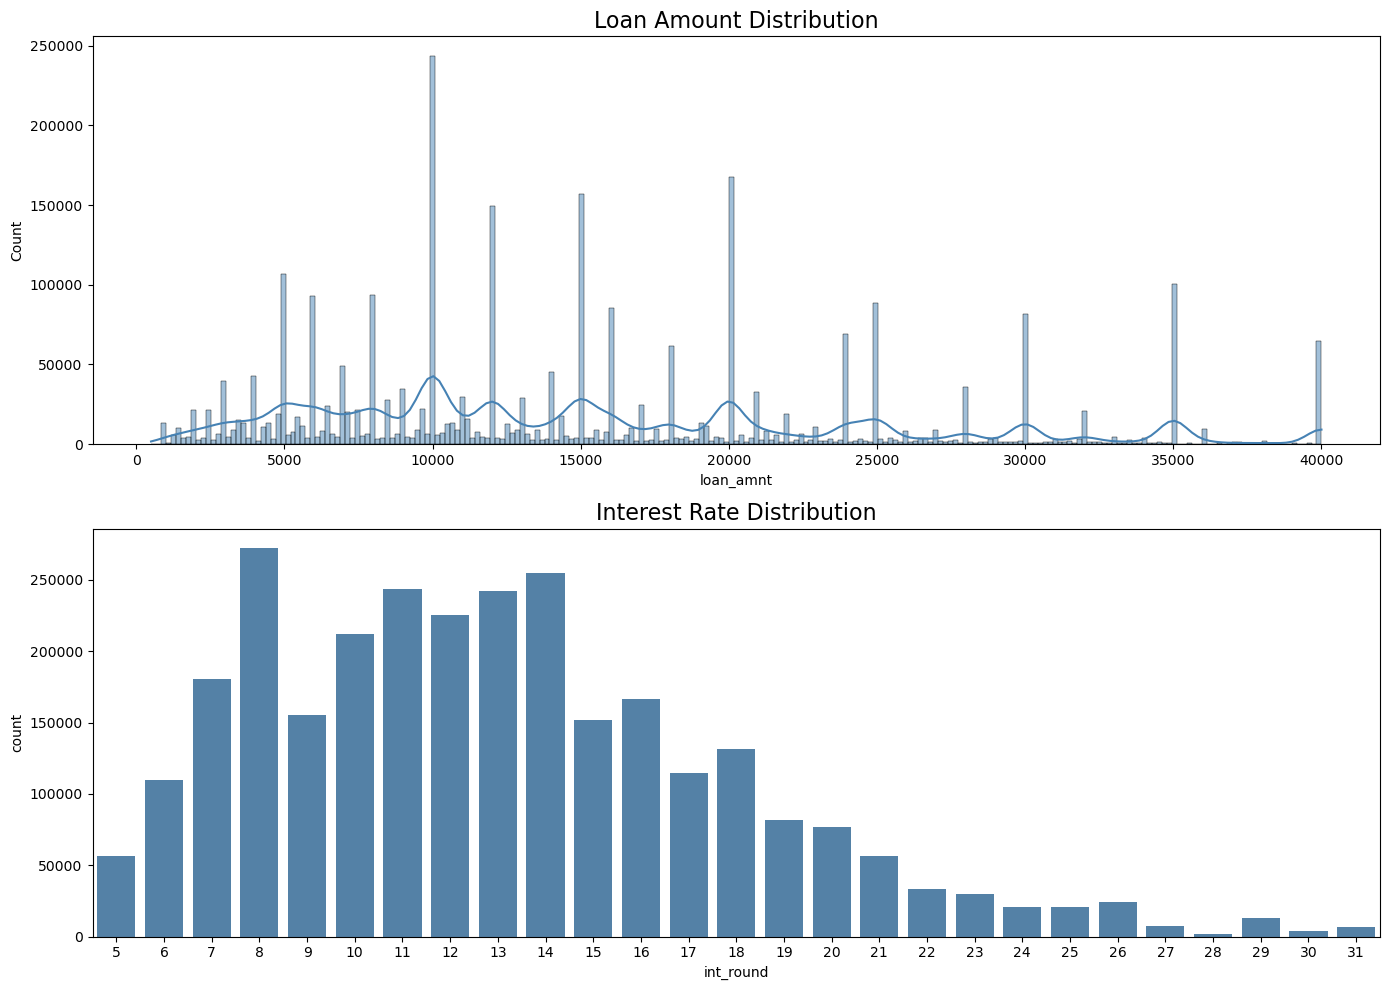

In [10]:
df_final["int_round"] = df_final["int_rate"].round(0).astype(int)

fig, axes = plt.subplots(2, 1, figsize=(14,10))

sns.histplot(df_final["loan_amnt"], ax=axes[0], kde=True, color="steelblue")
axes[0].set_title("Loan Amount Distribution", fontsize=16)

sns.countplot(x="int_round", data=df_final, color="steelblue", ax=axes[1])
axes[1].set_title("Interest Rate Distribution", fontsize=16)

plt.tight_layout(); plt.show()

## 3.3 Loan Status by Rate & Amount

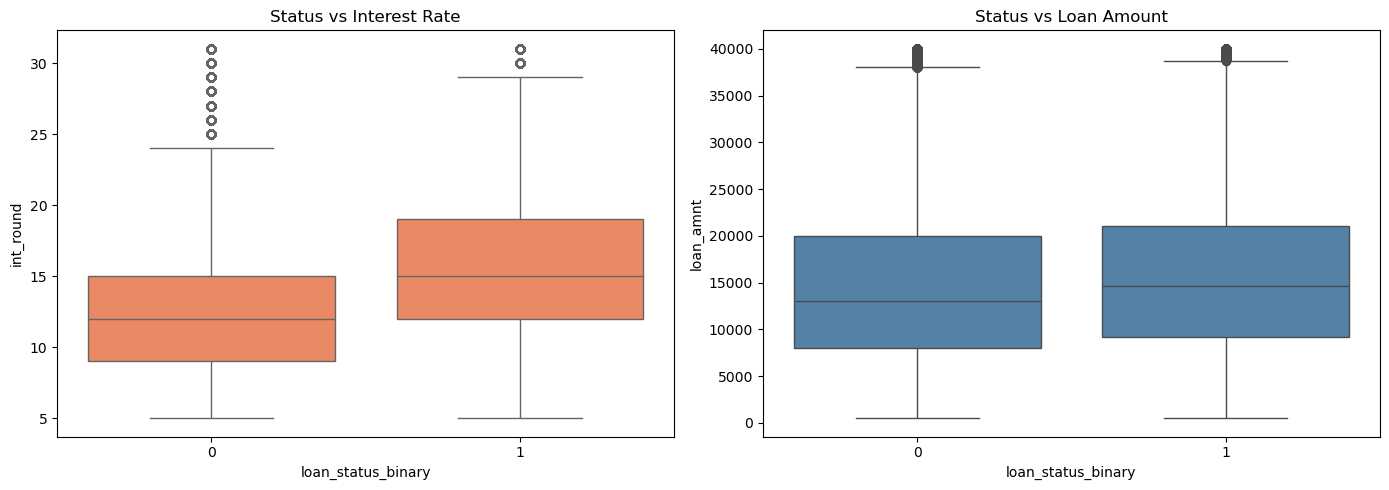

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.boxplot(x="loan_status_binary", y="int_round",  data=df_final, ax=axes[0], color="coral")
axes[0].set_title("Status vs Interest Rate")
sns.boxplot(x="loan_status_binary", y="loan_amnt", data=df_final, ax=axes[1], color="steelblue")
axes[1].set_title("Status vs Loan Amount")
plt.tight_layout(); plt.show()

## 3.4 Correlation Heatmap (Top 10 features)

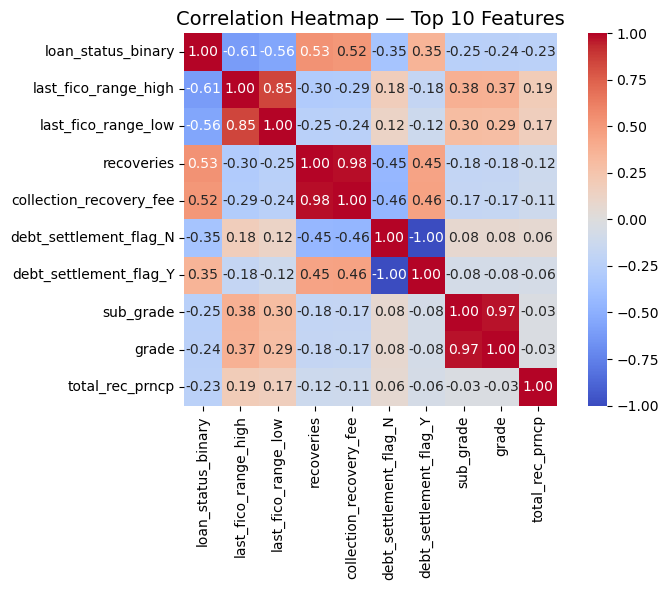

In [12]:
corr = df_final.corr()
top_features = corr["loan_status_binary"].abs().sort_values(ascending=False).head(10).index
plt.figure(figsize=(8,6))
sns.heatmap(df_final[top_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Heatmap — Top 10 Features", fontsize=14)
plt.tight_layout(); plt.show()

# 4. Feature Engineering & Selection

## 4.1 Multicollinearity — drop |r| > 0.8

In [13]:
# Computed on TRAIN YEARS ONLY (2007-2016) so that the validation/test sets
# never influence which features are judged collinear -- this is a feature-
# selection decision and must not see val/test data (see Section 4.4 below
# for the full temporal split; issue_year is available from Section 2).
_train_mask_corr = df_final["issue_year"].isin(TRAIN_YEARS)
corr_abs = df_final.loc[_train_mask_corr].corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
high_corr_pairs = [(col,row,upper.loc[row,col])
    for col in upper.columns for row in upper.index
    if upper.loc[row,col] > 0.8]
print(f"High-correlation pairs (|r|>0.8), computed on TRAIN (2007-2016) only: {len(high_corr_pairs)}")
for p in high_corr_pairs: print(p)

High-correlation pairs (|r|>0.8), computed on TRAIN (2007-2016) only: 98
('funded_amnt', 'loan_amnt', 0.9995238469565293)
('funded_amnt_inv', 'loan_amnt', 0.9981351556905246)
('funded_amnt_inv', 'funded_amnt', 0.9987239867358868)
('installment', 'loan_amnt', 0.9466153341537239)
('installment', 'funded_amnt', 0.9472859581820904)
('installment', 'funded_amnt_inv', 0.945751765718624)
('grade', 'int_rate', 0.953922568477166)
('sub_grade', 'int_rate', 0.9777981239645622)
('sub_grade', 'grade', 0.9754639692243604)
('fico_range_high', 'fico_range_low', 0.9999999375159097)
('out_prncp_inv', 'out_prncp', 0.9999992281392287)
('total_pymnt', 'loan_amnt', 0.8852195116372522)
('total_pymnt', 'funded_amnt', 0.8855917322202451)
('total_pymnt', 'funded_amnt_inv', 0.8848631128940017)
('total_pymnt', 'installment', 0.8306392384827379)
('total_pymnt_inv', 'loan_amnt', 0.8844631368916901)
('total_pymnt_inv', 'funded_amnt', 0.8849285681663217)
('total_pymnt_inv', 'funded_amnt_inv', 0.8861482943980399)
('to

## 4.2 Drop Leakage, Multicollinear & Weak Features

In [14]:
leakage_features = [
    "out_prncp","out_prncp_inv","total_pymnt","total_pymnt_inv",
    "total_rec_prncp","total_rec_int","total_rec_late_fee",
    "recoveries","collection_recovery_fee","last_pymnt_amnt",
    "last_fico_range_high","last_fico_range_low",
    "debt_settlement_flag_N","debt_settlement_flag_Y",
    "hardship_flag_N","hardship_flag_Y",
    "acc_now_delinq","delinq_amnt","chargeoff_within_12_mths"
]
multicollinear_drop = [
    "funded_amnt","funded_amnt_inv","installment","sub_grade","fico_range_high",
    "num_sats","num_bc_sats","num_actv_bc_tl","bc_util","tot_cur_bal",
    "tot_hi_cred_lim","all_util_missing","inq_last_12m_missing",
    "total_cu_tl_missing","open_act_il_missing","open_il_24m_missing",
    "total_bal_il_missing","open_rv_12m_missing",
    "initial_list_status_w","application_type_Joint App"
]
optional_drop = ["emp_title","policy_code"]

for drop_list in [leakage_features, multicollinear_drop, optional_drop]:
    df_final = df_final.drop(columns=[c for c in drop_list if c in df_final.columns])

if "int_round" in df_final.columns:
    df_final = df_final.drop(columns=["int_round"])

print(f"Final feature count: {df_final.shape[1]-1} predictors + 1 target")

Final feature count: 88 predictors + 1 target


## 4.3 Target Distribution After Collinearity Reduction


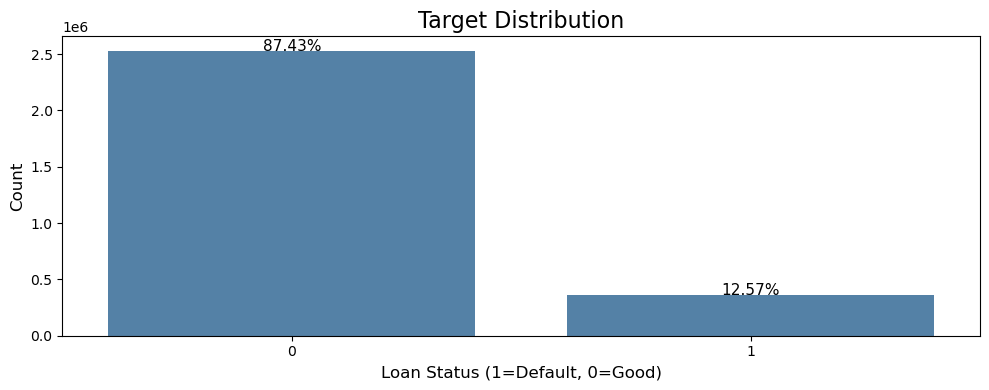

In [15]:
total = len(df_final)
plt.figure(figsize=(10,4))
g = sns.countplot(x="loan_status_binary", data=df_final, color="steelblue")
g.set_xlabel("Loan Status (1=Default, 0=Good)", fontsize=12)
g.set_ylabel("Count", fontsize=12)
g.set_title("Target Distribution", fontsize=16)
for p in g.patches:
    h = p.get_height()
    g.text(p.get_x()+p.get_width()/2., h+3, f"{h/total*100:.2f}%", ha="center", fontsize=11)
plt.tight_layout(); plt.show()
# We observe ~87.4% good / 12.6% default — significant class imbalance. (1=Default is the minority class)

## 4.4 Temporal Train / Validation / Test Split — No Test-Set Leakage

To prevent any form of test-set leakage into model selection, the data is split **strictly by
loan origination year** (`issue_year`), never randomly:

| Split | Years | Role |
|---|---|---|
| **Train** | 2007-2016 | Fit preprocessing (imputers, scalers, WoE binning) and model parameters |
| **Validation** | 2017-2018 | Select the imbalance-handling strategy, model architecture, hyperparameters |
| **Test** | 2019-2020 | Touched **exactly once**, only to report final, unbiased performance |

The test set never determines the imbalance strategy, model architecture, hyperparameters,
preprocessing, or feature selection for any model in this notebook. Those decisions are made
using the training set (via cross-validation) and/or the validation set only.

In [16]:
# ── Temporal Train / Validation / Test split (fixes test-set leakage) ──────
assert "issue_year" in df_final.columns, "issue_year missing -- check Section 2 parsing."

n_no_year = df_final["issue_year"].isna().sum()
if n_no_year:
    print(f"Dropping {n_no_year} rows with unparseable issue_d (excluded from all splits).")

train_df = df_final[df_final["issue_year"].isin(TRAIN_YEARS)].copy()
val_df   = df_final[df_final["issue_year"].isin(VAL_YEARS)].copy()
test_df  = df_final[df_final["issue_year"].isin(TEST_YEARS)].copy()

print(f"Train : {len(train_df):>8,} rows | years {min(TRAIN_YEARS)}-{max(TRAIN_YEARS)} "
      f"| default rate {train_df['loan_status_binary'].mean():.2%}")
print(f"Val   : {len(val_df):>8,} rows | years {min(VAL_YEARS)}-{max(VAL_YEARS)} "
      f"| default rate {val_df['loan_status_binary'].mean():.2%}")
print(f"Test  : {len(test_df):>8,} rows | years {min(TEST_YEARS)}-{max(TEST_YEARS)} "
      f"| default rate {test_df['loan_status_binary'].mean():.2%}")

DROP_FOR_X = ["loan_status_binary", "issue_year"]

def split_Xy(split_df):
    """Returns (X, y) for a split. issue_year is always excluded from X -- it
    is the split key, never a model feature (a fielded model would not know
    a future origination year at scoring time)."""
    X = split_df.drop(columns=[c for c in DROP_FOR_X if c in split_df.columns])
    y = split_df["loan_status_binary"]
    return X, y

X_train_raw, y_train_raw = split_Xy(train_df)
X_val_raw,   y_val_raw   = split_Xy(val_df)
X_test_raw,  y_test_raw  = split_Xy(test_df)

print(f"\nFeature count (excl. target/year): {X_train_raw.shape[1]}")

Train : 1,319,905 rows | years 2007-2016 | default rate 17.93%
Val   :  924,065 rows | years 2017-2018 | default rate 12.28%
Test  :  650,559 rows | years 2019-2020 | default rate 2.09%

Feature count (excl. target/year): 87


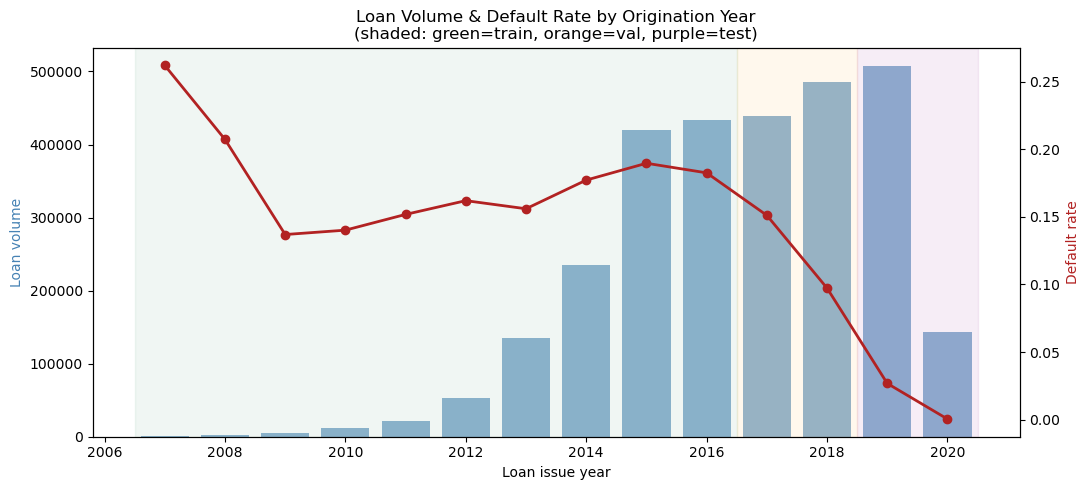

,n_loans,default_rate
issue_year,,
2007.0,603,0.2620
2008.0,2393,0.2073
2009.0,5281,0.1369
2010.0,12537,0.1401
2011.0,21721,0.1518
2012.0,53367,0.1620
2013.0,134814,0.1560
2014.0,235623,0.1772
2015.0,420342,0.1896


In [17]:
# Loan volume & default rate by origination year -- also motivates which
# years are reasonable "stress periods" later on (Section 11).
year_stats = df_final.groupby("issue_year")["loan_status_binary"].agg(["count","mean"])
year_stats.columns = ["n_loans","default_rate"]

fig, ax1 = plt.subplots(figsize=(11,5))
ax1.bar(year_stats.index, year_stats["n_loans"], color="steelblue", alpha=0.6, label="Loan volume")
ax1.set_ylabel("Loan volume", color="steelblue")
ax2 = ax1.twinx()
ax2.plot(year_stats.index, year_stats["default_rate"], color="firebrick", marker="o", lw=2, label="Default rate")
ax2.set_ylabel("Default rate", color="firebrick")
for yrs, color in [(TRAIN_YEARS,"seagreen"), (VAL_YEARS,"orange"), (TEST_YEARS,"purple")]:
    ax1.axvspan(min(yrs)-0.5, max(yrs)+0.5, color=color, alpha=0.07)
ax1.set_xlabel("Loan issue year")
ax1.set_title("Loan Volume & Default Rate by Origination Year\n(shaded: green=train, orange=val, purple=test)")
plt.tight_layout(); plt.show()
display(year_stats.round(4))

# 5. Baseline Model 1 — WoE + Logistic Regression

We skip scaling for WoE because the transformation already maps all features to a
comparable log-odds scale (typically −3 to +3), preserving the direct coefficient
interpretability that is the hallmark of a credit scorecard.

WoE+LR validation AUC (2017-2018): 0.6985
--- WOE + LOGISTIC REGRESSION (test = 2019-2020) ---
              precision    recall  f1-score   support

     Good(0)       0.99      0.66      0.79    636936
  Default(1)       0.04      0.59      0.07     13623

    accuracy                           0.66    650559
   macro avg       0.51      0.63      0.43    650559
weighted avg       0.97      0.66      0.78    650559

ROC-AUC : 0.6734
Avg Prec: 0.0405


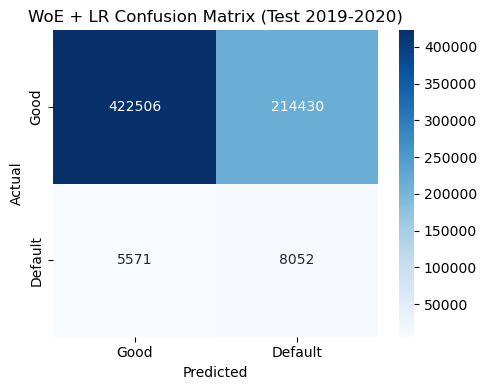

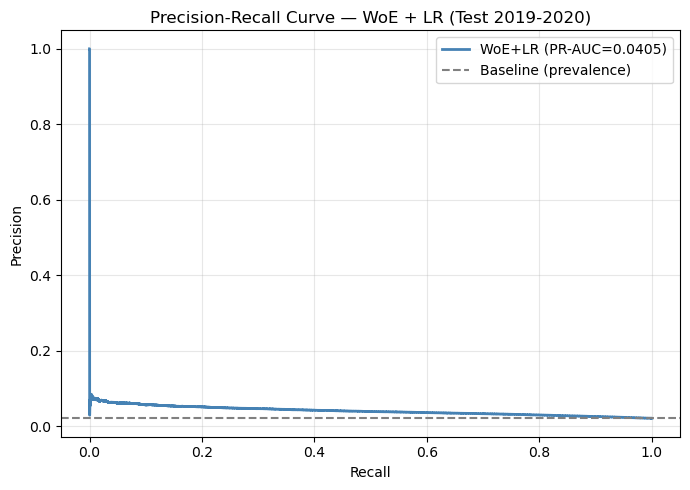

PR-AUC (WoE+LR): 0.0405


In [18]:
from optbinning import BinningProcess

X_woe_train_df, y_woe_train = X_train_raw.copy(), y_train_raw.copy()
X_woe_val_df,   y_woe_val   = X_val_raw.copy(),   y_val_raw.copy()
X_woe_test_df,  y_woe_test  = X_test_raw.copy(),  y_test_raw.copy()

# Binning is FIT on TRAIN ONLY -- validation/test are only ever .transform()-ed.
binning_process = BinningProcess(variable_names=X_woe_train_df.columns.tolist())
binning_process.fit(X_woe_train_df, y_woe_train)

X_train_woe = binning_process.transform(X_woe_train_df)
X_val_woe   = binning_process.transform(X_woe_val_df)
X_test_woe  = binning_process.transform(X_woe_test_df)

lr_woe = LogisticRegression(class_weight="balanced", solver="lbfgs", max_iter=1000)
lr_woe.fit(X_train_woe, y_woe_train)

# Validation is used only to sanity-check the fitted model -- it does not
# feed back into any preprocessing/hyperparameter decision for this model.
y_prob_val_w = lr_woe.predict_proba(X_val_woe)[:,1]
print(f"WoE+LR validation AUC (2017-2018): {roc_auc_score(y_woe_val, y_prob_val_w):.4f}")

# Final, single-use evaluation on the held-out test set (2019-2020)
y_test_w = y_woe_test
y_pred_w = lr_woe.predict(X_test_woe)
y_prob_w = lr_woe.predict_proba(X_test_woe)[:,1]

auc_woe = roc_auc_score(y_test_w, y_prob_w)
ap_woe  = average_precision_score(y_test_w, y_prob_w)
print("--- WOE + LOGISTIC REGRESSION (test = 2019-2020) ---")
print(classification_report(y_test_w, y_pred_w, target_names=["Good(0)","Default(1)"]))
print(f"ROC-AUC : {auc_woe:.4f}")
print(f"Avg Prec: {ap_woe:.4f}")

# Confusion matrix
cm = confusion_matrix(y_test_w, y_pred_w)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Good","Default"], yticklabels=["Good","Default"])
plt.title("WoE + LR Confusion Matrix (Test 2019-2020)"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

# Precision-Recall curve
prec_w, rec_w, _ = precision_recall_curve(y_test_w, y_prob_w)
pr_auc_w = sklearn_auc(rec_w, prec_w)
plt.figure(figsize=(7,5))
plt.plot(rec_w, prec_w, color="steelblue", lw=2,
         label=f"WoE+LR (PR-AUC={pr_auc_w:.4f})")
plt.axhline(y_test_w.mean(), color="gray", linestyle="--", label="Baseline (prevalence)")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall Curve — WoE + LR (Test 2019-2020)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f"PR-AUC (WoE+LR): {pr_auc_w:.4f}")

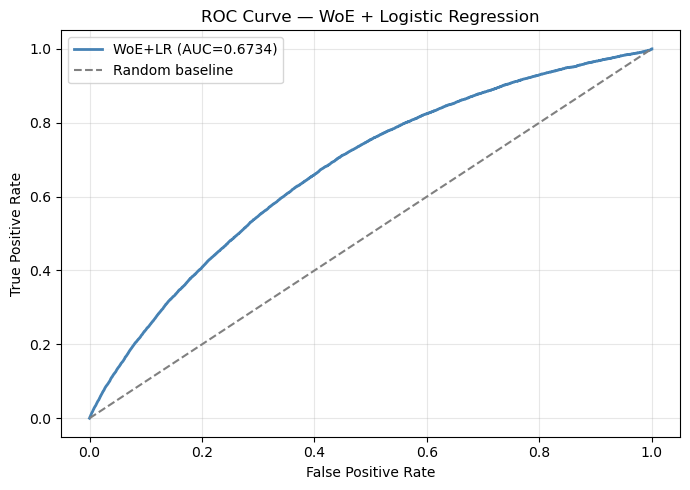

In [19]:
# ROC-AUC Curve — WoE + LR
from sklearn.metrics import roc_curve

fpr_w, tpr_w, _ = roc_curve(y_test_w, y_prob_w)
plt.figure(figsize=(7,5))
plt.plot(fpr_w, tpr_w, color="steelblue", lw=2,
         label=f"WoE+LR (AUC={auc_woe:.4f})")
plt.plot([0,1],[0,1], color="gray", linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve — WoE + Logistic Regression")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


## 5.4 100,000-Record Versions of the Baseline Models (W-DRO-style Subsample)

The W-DRO model (Section 10.5) is trained on a **stratified subsample of exactly
100,000 rows** drawn from the training split, since CVXPY's solver has a
practical memory ceiling around that size. To make the baselines directly
comparable to W-DRO on an equal-N basis, this subsection retrains WoE + LR,
XGBoost, and TabNet on the *same size* subsample, using the *same*
methodology (`train_test_split(..., train_size=100_000, stratify=y,
random_state=42)`, applied to the already-preprocessed TRAIN split — the
preprocessing itself, i.e. WoE binning / imputer / scaler, stays fit on the
**full** training set, exactly as in the W-DRO pipeline). Each 100k model is
evaluated on the **same held-out 2019-2020 test set** as its full-train
counterpart above, so the only thing that changes is the number of training
rows.


In [20]:
# ── Stratified 100,000-row subsample helper — mirrors the W-DRO
# 100k final-training methodology (Section 10.5) exactly:
# train_size=100_000, stratified by target, random_state=42, applied to
# an ALREADY-preprocessed train split (preprocessing itself is never
# refit on the subsample). Reused below for WoE+LR, XGBoost, and TabNet.
N_100K = 100_000

def get_100k_subsample(X, y, n=N_100K, seed=42):
    """Stratified subsample of the (already-preprocessed) TRAIN split
    only, taken to exactly `n` rows -- identical logic to the 100k
    final-training subsample used for W-DRO."""
    if len(X) <= n:
        print(f"  Train set already <= {n:,} rows ({len(X):,}); using as-is.")
        return X, y
    idx, _ = train_test_split(
        np.arange(len(X)), train_size=n, stratify=y, random_state=seed
    )
    X_s = X.iloc[idx].reset_index(drop=True) if isinstance(X, pd.DataFrame) else X[idx]
    y_s = y.iloc[idx].reset_index(drop=True) if isinstance(y, (pd.Series, pd.DataFrame)) else y[idx]
    return X_s, y_s

print("get_100k_subsample defined.")


get_100k_subsample defined.


### WoE + LR — Fit on the 100,000-Row Subsample

[WoE + LR - 100,000-record version]
  Subsample: 100,000 rows | default rate: 17.93%
--- WOE + LOGISTIC REGRESSION - 100,000 RECORDS (test = 2019-2020) ---
              precision    recall  f1-score   support

     Good(0)       0.99      0.65      0.79    636936
  Default(1)       0.04      0.61      0.07     13623

    accuracy                           0.65    650559
   macro avg       0.51      0.63      0.43    650559
weighted avg       0.97      0.65      0.77    650559

ROC-AUC : 0.6738
Avg Prec: 0.0406


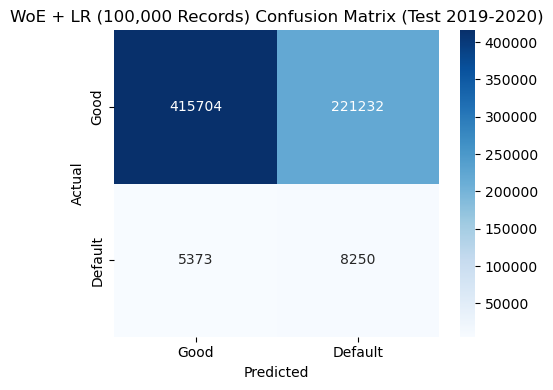

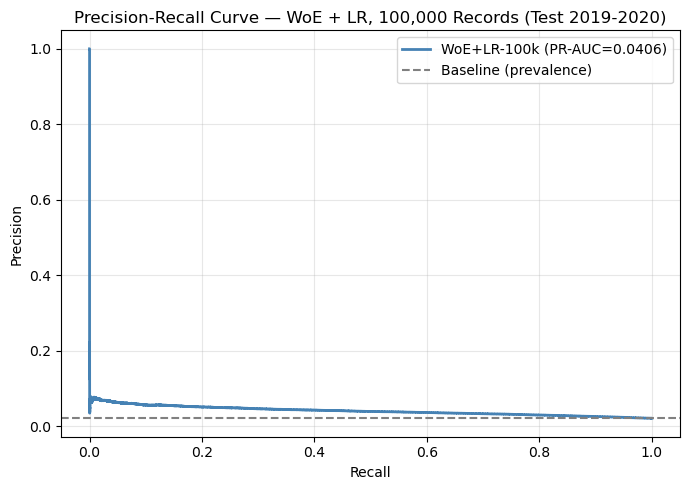

PR-AUC (WoE+LR-100k): 0.0406


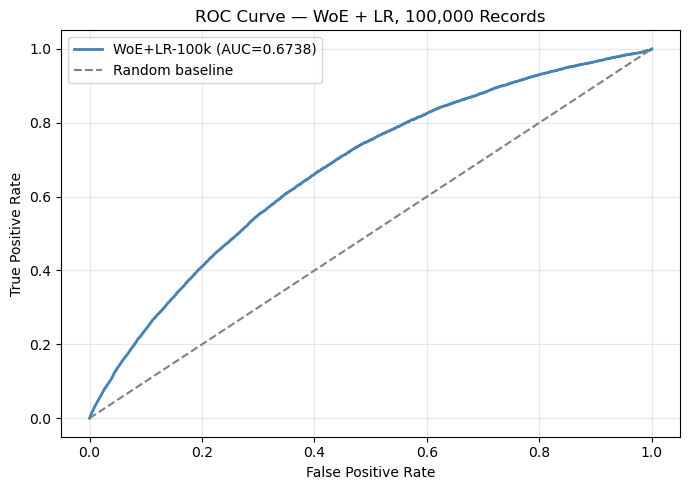

In [21]:
print("[WoE + LR - 100,000-record version]")
X_train_woe_100k, y_woe_train_100k = get_100k_subsample(X_train_woe, y_woe_train)
print(f"  Subsample: {len(X_train_woe_100k):,} rows | default rate: {y_woe_train_100k.mean():.2%}")

lr_woe_100k = LogisticRegression(class_weight="balanced", solver="lbfgs", max_iter=1000)
lr_woe_100k.fit(X_train_woe_100k, y_woe_train_100k)

# Evaluated on the SAME held-out test set (2019-2020) as the full-train version
y_pred_w_100k = lr_woe_100k.predict(X_test_woe)
y_prob_w_100k = lr_woe_100k.predict_proba(X_test_woe)[:,1]

auc_woe_100k = roc_auc_score(y_test_w, y_prob_w_100k)
ap_woe_100k  = average_precision_score(y_test_w, y_prob_w_100k)
bs_woe_100k  = brier_score_loss(y_test_w, y_prob_w_100k)
print("--- WOE + LOGISTIC REGRESSION - 100,000 RECORDS (test = 2019-2020) ---")
print(classification_report(y_test_w, y_pred_w_100k, target_names=["Good(0)","Default(1)"]))
print(f"ROC-AUC : {auc_woe_100k:.4f}")
print(f"Avg Prec: {ap_woe_100k:.4f}")

cm = confusion_matrix(y_test_w, y_pred_w_100k)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Good","Default"], yticklabels=["Good","Default"])
plt.title("WoE + LR (100,000 Records) Confusion Matrix (Test 2019-2020)")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

prec_w_100k, rec_w_100k, _ = precision_recall_curve(y_test_w, y_prob_w_100k)
pr_auc_w_100k = sklearn_auc(rec_w_100k, prec_w_100k)
plt.figure(figsize=(7,5))
plt.plot(rec_w_100k, prec_w_100k, color="steelblue", lw=2,
         label=f"WoE+LR-100k (PR-AUC={pr_auc_w_100k:.4f})")
plt.axhline(y_test_w.mean(), color="gray", linestyle="--", label="Baseline (prevalence)")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall Curve — WoE + LR, 100,000 Records (Test 2019-2020)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f"PR-AUC (WoE+LR-100k): {pr_auc_w_100k:.4f}")

fpr_w_100k, tpr_w_100k, _ = roc_curve(y_test_w, y_prob_w_100k)
plt.figure(figsize=(7,5))
plt.plot(fpr_w_100k, tpr_w_100k, color="steelblue", lw=2,
         label=f"WoE+LR-100k (AUC={auc_woe_100k:.4f})")
plt.plot([0,1],[0,1], color="gray", linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve — WoE + LR, 100,000 Records")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


# 6. Baseline Model 2 — XGBoost (Multi-Strategy Imbalance Comparison)

In [22]:
# We compare SMOTE, scale_pos_weight, class_weight via sample_weight,
# Random Under-Sampling + XGBoost, and ADASYN to find the best strategy.
# IMPORTANT: the winning strategy is selected using VALIDATION AUC (2017-2018) only


from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight

X_train_m, y_train_m = X_train_raw.copy(), y_train_raw.copy()
X_val_m,   y_val_m   = X_val_raw.copy(),   y_val_raw.copy()
X_test_m,  y_test_m  = X_test_raw.copy(),  y_test_raw.copy()

imputer_xgb = SimpleImputer(strategy="median")
X_train_imp = imputer_xgb.fit_transform(X_train_m)
X_val_imp   = imputer_xgb.transform(X_val_m)
X_test_imp  = imputer_xgb.transform(X_test_m)

scaler_xgb = StandardScaler()
X_train_sc = scaler_xgb.fit_transform(X_train_imp)
X_val_sc   = scaler_xgb.transform(X_val_imp)
X_test_sc  = scaler_xgb.transform(X_test_imp)

# Base XGBoost hyperparameters 
BASE_XGB_PARAMS = dict(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.5,
    random_state=42,
    eval_metric="logloss",
    verbosity=0,
    use_label_encoder=False
)

neg_count = (y_train_m == 0).sum()
pos_count = (y_train_m == 1).sum()
spw = neg_count / pos_count   # scale_pos_weight ratio

strategies = {}

# ── Strategy 1: SMOTE ─────────────────────────────────────────────────────
print("[1/5] SMOTE...")
sm = SMOTE(random_state=42)
X_sm, y_sm = sm.fit_resample(X_train_sc, y_train_m)
m1 = XGBClassifier(**BASE_XGB_PARAMS)
m1.fit(X_sm, y_sm, verbose=False)
strategies["SMOTE"] = {"model": m1, "val_auc": roc_auc_score(y_val_m, m1.predict_proba(X_val_sc)[:,1])}

# ── Strategy 2: scale_pos_weight ─────────────────────────────────────────
print("[2/5] scale_pos_weight...")
m2 = XGBClassifier(**BASE_XGB_PARAMS, scale_pos_weight=spw)
m2.fit(X_train_sc, y_train_m, verbose=False)
strategies["scale_pos_weight"] = {"model": m2, "val_auc": roc_auc_score(y_val_m, m2.predict_proba(X_val_sc)[:,1])}

# ── Strategy 3: Sample weights (class_weight balanced equivalent) ─────────
print("[3/5] sample_weight...")
sw = compute_sample_weight("balanced", y_train_m)
m3 = XGBClassifier(**BASE_XGB_PARAMS)
m3.fit(X_train_sc, y_train_m, sample_weight=sw, verbose=False)
strategies["sample_weight"] = {"model": m3, "val_auc": roc_auc_score(y_val_m, m3.predict_proba(X_val_sc)[:,1])}

# ── Strategy 4: Random Under-Sampling ────────────────────────────────────
print("[4/5] RandomUnderSampler...")
rus = RandomUnderSampler(random_state=42)
X_us, y_us = rus.fit_resample(X_train_sc, y_train_m)
m4 = XGBClassifier(**BASE_XGB_PARAMS)
m4.fit(X_us, y_us, verbose=False)
strategies["RUS+XGB"] = {"model": m4, "val_auc": roc_auc_score(y_val_m, m4.predict_proba(X_val_sc)[:,1])}

# ── Strategy 5: ADASYN ───────────────────────────────────────────────────
print("[5/5] ADASYN...")
try:
    ada = ADASYN(random_state=42)
    X_ada, y_ada = ada.fit_resample(X_train_sc, y_train_m)
    m5 = XGBClassifier(**BASE_XGB_PARAMS)
    m5.fit(X_ada, y_ada, verbose=False)
    strategies["ADASYN"] = {"model": m5, "val_auc": roc_auc_score(y_val_m, m5.predict_proba(X_val_sc)[:,1])}
except Exception as e:
    print(f"  ADASYN failed: {e}. Skipping.")

# ── Strategy comparison table (validation AUC) ─────────────────────────────
print(f"\n{'Strategy':<22} {'Val AUC (2017-2018)':>20}")
print("-" * 44)
for name, res in strategies.items():
    print(f"{name:<22} {res['val_auc']:>20.4f}")

# Select best by VALIDATION AUC-ROC 
best_xgb_name = max(strategies, key=lambda k: strategies[k]["val_auc"])
xgb_model     = strategies[best_xgb_name]["model"]
print(f"\n>>> Best XGBoost strategy (by validation AUC): {best_xgb_name} "
      f"(val AUC={strategies[best_xgb_name]['val_auc']:.4f})")

# Final, single-use evaluation on the held-out test set (2019-2020)
y_prob_xgb = xgb_model.predict_proba(X_test_sc)[:,1]
y_pred_xgb = xgb_model.predict(X_test_sc)
best_xgb_data = {
    "model": xgb_model,
    "probs": y_prob_xgb,
    "auc": roc_auc_score(y_test_m, y_prob_xgb),
    "ap":  average_precision_score(y_test_m, y_prob_xgb),
}

print(f"\n--- BEST XGBoost ({best_xgb_name}) CLASSIFICATION REPORT (Test 2019-2020) ---")
print(classification_report(y_test_m, y_pred_xgb, target_names=["Good(0)","Default(1)"]))
print(f"Test AUC-ROC: {best_xgb_data['auc']:.4f}")

[1/5] SMOTE...
[2/5] scale_pos_weight...
[3/5] sample_weight...
[4/5] RandomUnderSampler...
[5/5] ADASYN...

Strategy                Val AUC (2017-2018)
--------------------------------------------
SMOTE                                0.7045
scale_pos_weight                     0.7099
sample_weight                        0.7102
RUS+XGB                              0.7103
ADASYN                               0.7041

>>> Best XGBoost strategy (by validation AUC): RUS+XGB (val AUC=0.7103)

--- BEST XGBoost (RUS+XGB) CLASSIFICATION REPORT (Test 2019-2020) ---
              precision    recall  f1-score   support

     Good(0)       0.99      0.69      0.81    636936
  Default(1)       0.04      0.58      0.07     13623

    accuracy                           0.69    650559
   macro avg       0.51      0.64      0.44    650559
weighted avg       0.97      0.69      0.80    650559

Test AUC-ROC: 0.6879


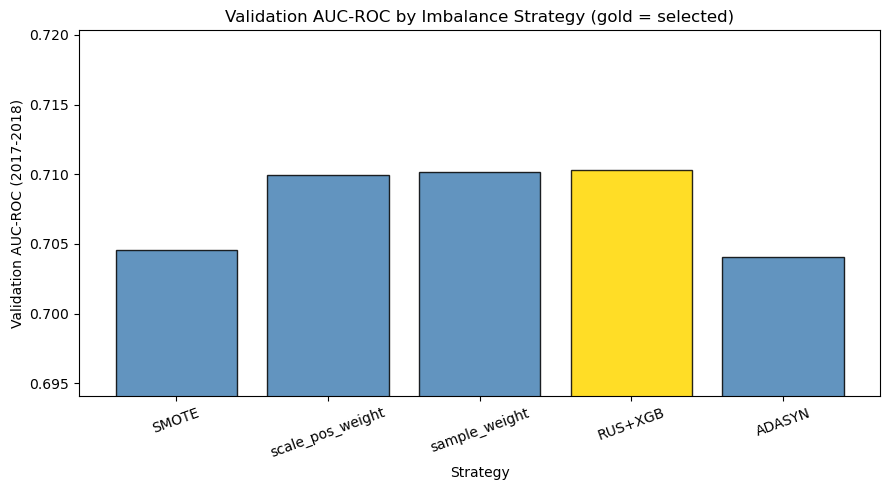

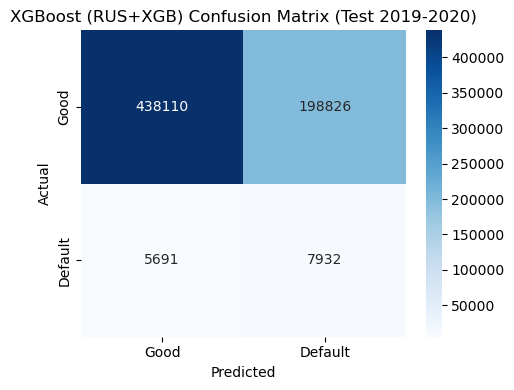

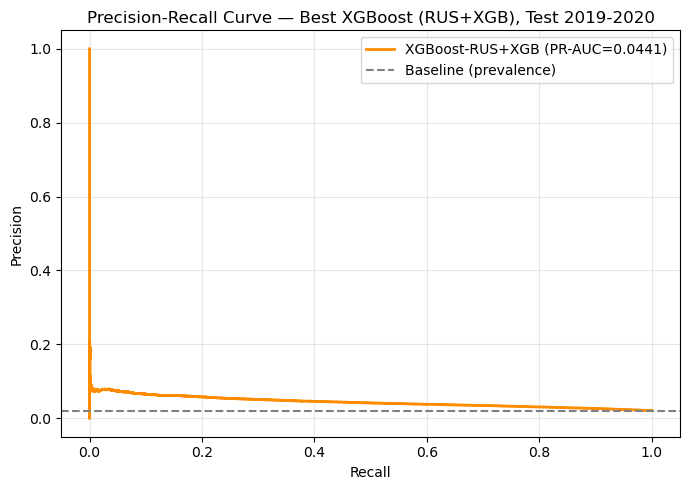

PR-AUC (XGBoost-RUS+XGB): 0.0441


In [23]:
# ── XGBoost Strategy Comparison Plot (validation AUC) ──
fig, ax = plt.subplots(figsize=(9,5))
names  = list(strategies.keys())
vaucs  = [strategies[n]["val_auc"] for n in names]
colors = ["gold" if n == best_xgb_name else "steelblue" for n in names]
ax.bar(names, vaucs, color=colors, edgecolor="k", alpha=0.85)
ax.set_ylim(min(vaucs)-0.01, max(vaucs)+0.01)
ax.set_xlabel("Strategy"); ax.set_ylabel("Validation AUC-ROC (2017-2018)")
ax.set_title("Validation AUC-ROC by Imbalance Strategy (gold = selected)")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

# Confusion matrix for best XGBoost -- TEST SET (2019-2020)
cm = confusion_matrix(y_test_m, y_pred_xgb)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Good","Default"], yticklabels=["Good","Default"])
plt.title(f"XGBoost ({best_xgb_name}) Confusion Matrix (Test 2019-2020)")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

# PR curve for best -- TEST SET
prec_xgb, rec_xgb, _ = precision_recall_curve(y_test_m, y_prob_xgb)
pr_auc_xgb = sklearn_auc(rec_xgb, prec_xgb)
plt.figure(figsize=(7,5))
plt.plot(rec_xgb, prec_xgb, color="darkorange", lw=2,
         label=f"XGBoost-{best_xgb_name} (PR-AUC={pr_auc_xgb:.4f})")
plt.axhline(y_test_m.mean(), color="gray", ls="--", label="Baseline (prevalence)")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title(f"Precision-Recall Curve — Best XGBoost ({best_xgb_name}), Test 2019-2020")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f"PR-AUC (XGBoost-{best_xgb_name}): {pr_auc_xgb:.4f}")

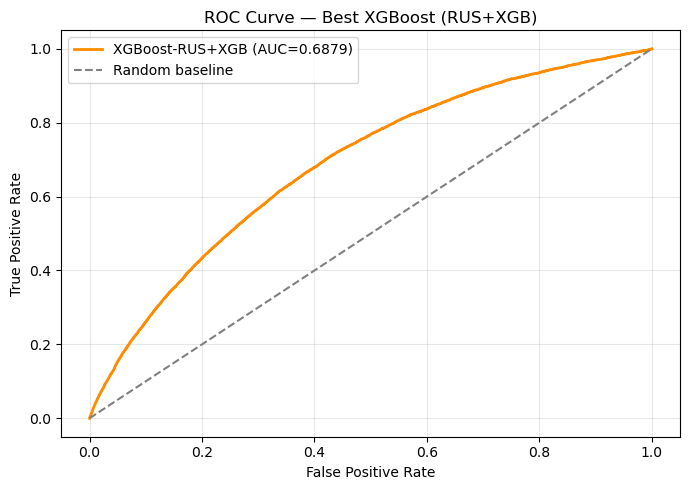

In [24]:
# ROC-AUC Curve — Best XGBoost strategy
from sklearn.metrics import roc_curve

fpr_xgb, tpr_xgb, _ = roc_curve(y_test_m, y_prob_xgb)
plt.figure(figsize=(7,5))
plt.plot(fpr_xgb, tpr_xgb, color="darkorange", lw=2,
         label=f"XGBoost-{best_xgb_name} (AUC={best_xgb_data['auc']:.4f})")
plt.plot([0,1],[0,1], color="gray", linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve — Best XGBoost ({best_xgb_name})")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


### XGBoost — Fit on the 100,000-Row Subsample

Uses the imbalance-handling strategy already selected above via validation AUC (`best_xgb_name`), retrained on the 100,000-row subsample — the same tune-then-scale relationship as W-DRO (hyperparameters chosen once, final model trained on the 100k set).

[XGBoost - 100,000-record version, strategy = RUS+XGB (selected via validation AUC above)]
  Subsample: 100,000 rows | default rate: 17.93%

--- XGBoost (RUS+XGB) - 100,000 RECORDS - CLASSIFICATION REPORT (Test 2019-2020) ---
              precision    recall  f1-score   support

     Good(0)       0.99      0.67      0.80    636936
  Default(1)       0.04      0.58      0.07     13623

    accuracy                           0.67    650559
   macro avg       0.51      0.63      0.43    650559
weighted avg       0.97      0.67      0.78    650559

Test AUC-ROC: 0.6751


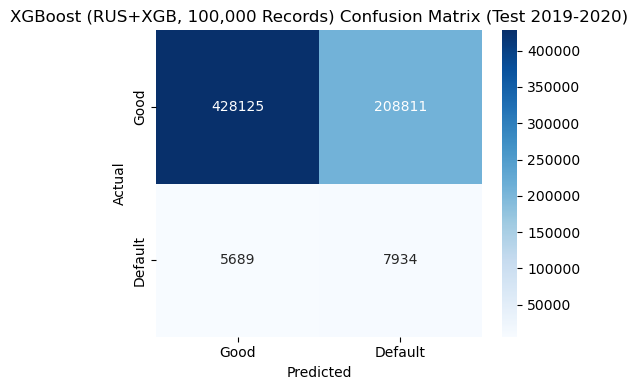

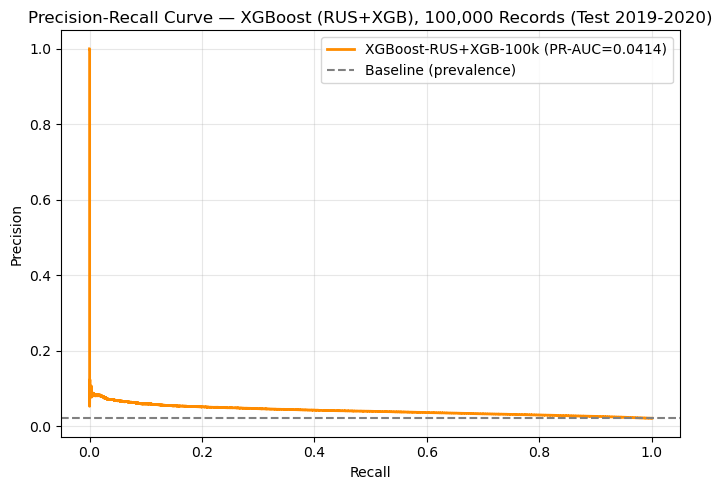

PR-AUC (XGBoost-RUS+XGB-100k): 0.0414


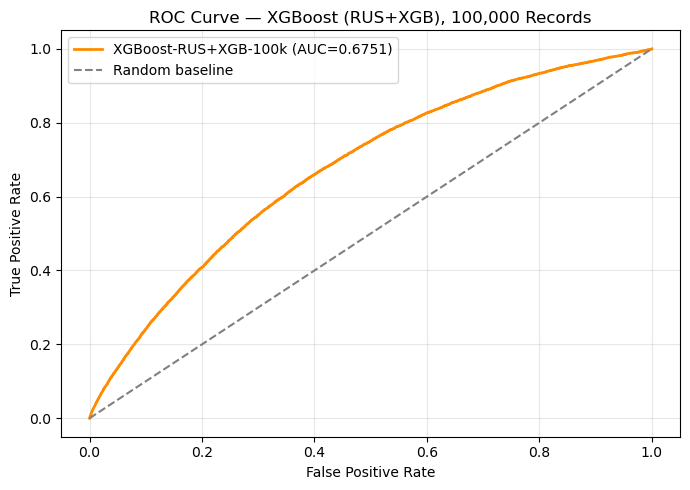

In [25]:
print(f"[XGBoost - 100,000-record version, strategy = {best_xgb_name} (selected via validation AUC above)]")
X_train_sc_100k, y_train_m_100k = get_100k_subsample(X_train_sc, y_train_m)
print(f"  Subsample: {len(X_train_sc_100k):,} rows | default rate: {y_train_m_100k.mean():.2%}")

if best_xgb_name == "SMOTE":
    X_fit_xgb_100k, y_fit_xgb_100k = SMOTE(random_state=42).fit_resample(X_train_sc_100k, y_train_m_100k)
    xgb_model_100k = XGBClassifier(**BASE_XGB_PARAMS)
    xgb_model_100k.fit(X_fit_xgb_100k, y_fit_xgb_100k, verbose=False)
elif best_xgb_name == "scale_pos_weight":
    neg_100k = (y_train_m_100k == 0).sum(); pos_100k = (y_train_m_100k == 1).sum()
    spw_100k = neg_100k / pos_100k
    xgb_model_100k = XGBClassifier(**BASE_XGB_PARAMS, scale_pos_weight=spw_100k)
    xgb_model_100k.fit(X_train_sc_100k, y_train_m_100k, verbose=False)
elif best_xgb_name == "sample_weight":
    sw_100k = compute_sample_weight("balanced", y_train_m_100k)
    xgb_model_100k = XGBClassifier(**BASE_XGB_PARAMS)
    xgb_model_100k.fit(X_train_sc_100k, y_train_m_100k, sample_weight=sw_100k, verbose=False)
elif best_xgb_name == "RUS+XGB":
    X_fit_xgb_100k, y_fit_xgb_100k = RandomUnderSampler(random_state=42).fit_resample(X_train_sc_100k, y_train_m_100k)
    xgb_model_100k = XGBClassifier(**BASE_XGB_PARAMS)
    xgb_model_100k.fit(X_fit_xgb_100k, y_fit_xgb_100k, verbose=False)
elif best_xgb_name == "ADASYN":
    X_fit_xgb_100k, y_fit_xgb_100k = ADASYN(random_state=42).fit_resample(X_train_sc_100k, y_train_m_100k)
    xgb_model_100k = XGBClassifier(**BASE_XGB_PARAMS)
    xgb_model_100k.fit(X_fit_xgb_100k, y_fit_xgb_100k, verbose=False)
else:
    raise ValueError(f"Unknown strategy: {best_xgb_name}")

# Final, single-use evaluation on the SAME held-out test set (2019-2020)
y_prob_xgb_100k = xgb_model_100k.predict_proba(X_test_sc)[:,1]
y_pred_xgb_100k = xgb_model_100k.predict(X_test_sc)
best_xgb_data_100k = {
    "model": xgb_model_100k,
    "probs": y_prob_xgb_100k,
    "auc": roc_auc_score(y_test_m, y_prob_xgb_100k),
    "ap":  average_precision_score(y_test_m, y_prob_xgb_100k),
}

print(f"\n--- XGBoost ({best_xgb_name}) - 100,000 RECORDS - CLASSIFICATION REPORT (Test 2019-2020) ---")
print(classification_report(y_test_m, y_pred_xgb_100k, target_names=["Good(0)","Default(1)"]))
print(f"Test AUC-ROC: {best_xgb_data_100k['auc']:.4f}")

cm = confusion_matrix(y_test_m, y_pred_xgb_100k)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Good","Default"], yticklabels=["Good","Default"])
plt.title(f"XGBoost ({best_xgb_name}, 100,000 Records) Confusion Matrix (Test 2019-2020)")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

prec_xgb_100k, rec_xgb_100k, _ = precision_recall_curve(y_test_m, y_prob_xgb_100k)
pr_auc_xgb_100k = sklearn_auc(rec_xgb_100k, prec_xgb_100k)
plt.figure(figsize=(7,5))
plt.plot(rec_xgb_100k, prec_xgb_100k, color="darkorange", lw=2,
         label=f"XGBoost-{best_xgb_name}-100k (PR-AUC={pr_auc_xgb_100k:.4f})")
plt.axhline(y_test_m.mean(), color="gray", ls="--", label="Baseline (prevalence)")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title(f"Precision-Recall Curve — XGBoost ({best_xgb_name}), 100,000 Records (Test 2019-2020)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f"PR-AUC (XGBoost-{best_xgb_name}-100k): {pr_auc_xgb_100k:.4f}")

fpr_xgb_100k, tpr_xgb_100k, _ = roc_curve(y_test_m, y_prob_xgb_100k)
plt.figure(figsize=(7,5))
plt.plot(fpr_xgb_100k, tpr_xgb_100k, color="darkorange", lw=2,
         label=f"XGBoost-{best_xgb_name}-100k (AUC={best_xgb_data_100k['auc']:.4f})")
plt.plot([0,1],[0,1], color="gray", linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve — XGBoost ({best_xgb_name}), 100,000 Records")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


# 7. Baseline Model 3 — TabNet

epoch 0  | loss: 0.63961 | train_auc: 0.70022 | valid_auc: 0.69456 |  0:03:44s
epoch 1  | loss: 0.62637 | train_auc: 0.70792 | valid_auc: 0.70218 |  0:07:32s
epoch 2  | loss: 0.62319 | train_auc: 0.70959 | valid_auc: 0.70327 |  0:11:23s
epoch 3  | loss: 0.62254 | train_auc: 0.71024 | valid_auc: 0.70447 |  0:15:09s
epoch 4  | loss: 0.62125 | train_auc: 0.7124  | valid_auc: 0.70483 |  0:18:30s
epoch 5  | loss: 0.62002 | train_auc: 0.71443 | valid_auc: 0.70663 |  0:21:50s
epoch 6  | loss: 0.61937 | train_auc: 0.71418 | valid_auc: 0.706   |  0:25:08s
epoch 7  | loss: 0.61928 | train_auc: 0.71512 | valid_auc: 0.70719 |  0:28:24s
epoch 8  | loss: 0.61908 | train_auc: 0.71513 | valid_auc: 0.70689 |  0:31:37s
epoch 9  | loss: 0.61805 | train_auc: 0.71614 | valid_auc: 0.70735 |  0:34:51s
epoch 10 | loss: 0.61825 | train_auc: 0.71656 | valid_auc: 0.70837 |  0:38:03s
epoch 11 | loss: 0.61931 | train_auc: 0.70598 | valid_auc: 0.703   |  0:41:14s
epoch 12 | loss: 0.61982 | train_auc: 0.71624 | vali

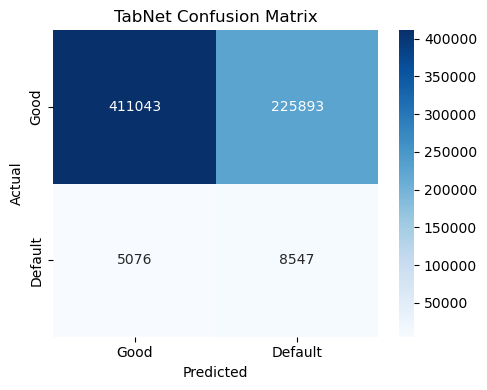

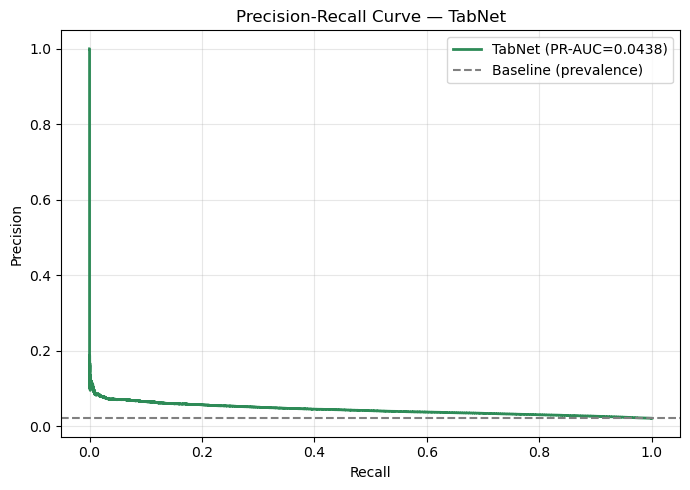

PR-AUC (TabNet): 0.0438


In [26]:
from pytorch_tabnet.tab_model import TabNetClassifier
import torch

tabnet_model = TabNetClassifier(
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    scheduler_params={"step_size":10,"gamma":0.9},
    scheduler_fn=torch.optim.lr_scheduler.StepLR,
    mask_type="sparsemax",
    device_name="auto"
)

# X_train_sc / X_val_sc / X_test_sc carry over from the XGBoost cell
# (imputer + scaler fit on TRAIN only). Early stopping uses the VALIDATION
# set (2017-2018) -- the test set (2019-2020) is not used until final scoring.
tabnet_model.fit(
    X_train_sc, y_train_m.values,
    eval_set=[(X_train_sc, y_train_m.values),(X_val_sc, y_val_m.values)],
    eval_name=["train","valid"],
    eval_metric=["auc"],
    max_epochs=50, patience=10, batch_size=1024,
    virtual_batch_size=128, num_workers=0, drop_last=False, weights=1
)

# Final, single-use evaluation on the held-out test set (2019-2020)
y_pred_tn = tabnet_model.predict(X_test_sc)
y_prob_tn = tabnet_model.predict_proba(X_test_sc)[:,1]

auc_tn = roc_auc_score(y_test_m, y_prob_tn)
ap_tn  = average_precision_score(y_test_m, y_prob_tn)
print("--- TABNET CLASSIFICATION REPORT ---")
print(classification_report(y_test_m, y_pred_tn, target_names=["Good(0)","Default(1)"]))
print(f"TabNet  ROC-AUC: {auc_tn:.4f}")
print(f"TabNet  Avg Prec: {ap_tn:.4f}")

# Confusion matrix
cm = confusion_matrix(y_test_m, y_pred_tn)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Good","Default"], yticklabels=["Good","Default"])
plt.title("TabNet Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

# Precision-Recall curve
prec_tn, rec_tn, _ = precision_recall_curve(y_test_m, y_prob_tn)
pr_auc_tn = sklearn_auc(rec_tn, prec_tn)
plt.figure(figsize=(7,5))
plt.plot(rec_tn, prec_tn, color="seagreen", lw=2,
         label=f"TabNet (PR-AUC={pr_auc_tn:.4f})")
plt.axhline(y_test_m.mean(), color="gray", ls="--", label="Baseline (prevalence)")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall Curve — TabNet")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f"PR-AUC (TabNet): {pr_auc_tn:.4f}")

### TabNet — Fit on the 100,000-Row Subsample

[TabNet - 100,000-record version]
  Subsample: 100,000 rows | default rate: 17.93%
epoch 0  | loss: 0.66755 | train_auc: 0.67618 | valid_auc: 0.67169 |  0:00:48s
epoch 1  | loss: 0.64259 | train_auc: 0.67979 | valid_auc: 0.67966 |  0:01:40s
epoch 2  | loss: 0.63872 | train_auc: 0.68371 | valid_auc: 0.68318 |  0:02:27s
epoch 3  | loss: 0.63846 | train_auc: 0.685   | valid_auc: 0.68263 |  0:03:18s
epoch 4  | loss: 0.63924 | train_auc: 0.68539 | valid_auc: 0.68264 |  0:04:07s
epoch 5  | loss: 0.63651 | train_auc: 0.69046 | valid_auc: 0.68371 |  0:04:56s
epoch 6  | loss: 0.6353  | train_auc: 0.69261 | valid_auc: 0.68629 |  0:05:45s
epoch 7  | loss: 0.63504 | train_auc: 0.69369 | valid_auc: 0.68573 |  0:06:35s
epoch 8  | loss: 0.63441 | train_auc: 0.69451 | valid_auc: 0.68569 |  0:07:23s
epoch 9  | loss: 0.6346  | train_auc: 0.69367 | valid_auc: 0.68428 |  0:08:11s
epoch 10 | loss: 0.63432 | train_auc: 0.69492 | valid_auc: 0.6827  |  0:09:01s
epoch 11 | loss: 0.63252 | train_auc: 0.69426 | 

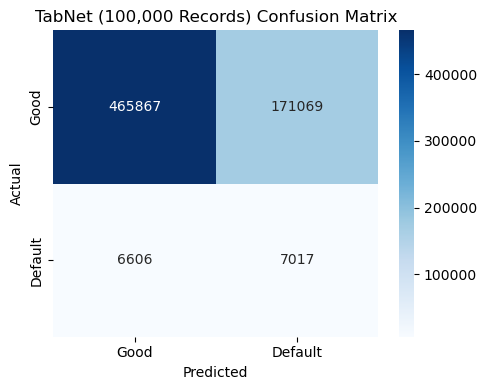

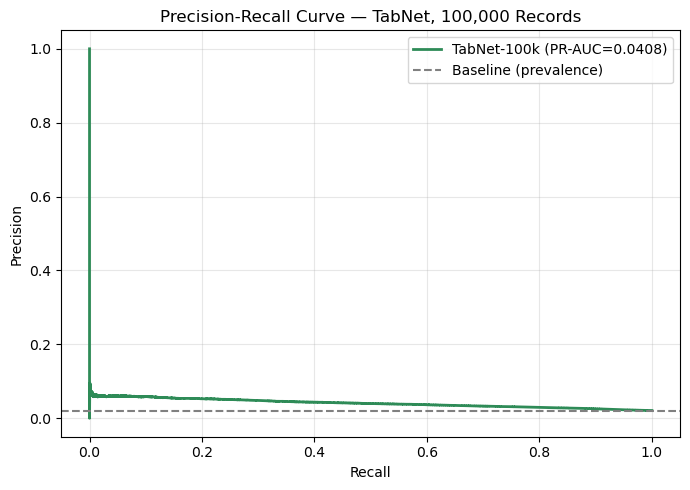

PR-AUC (TabNet-100k): 0.0408


In [27]:
print("[TabNet - 100,000-record version]")
X_train_sc_100k_tn, y_train_m_100k_tn = get_100k_subsample(X_train_sc, y_train_m)
print(f"  Subsample: {len(X_train_sc_100k_tn):,} rows | default rate: {y_train_m_100k_tn.mean():.2%}")

tabnet_model_100k = TabNetClassifier(
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    scheduler_params={"step_size":10,"gamma":0.9},
    scheduler_fn=torch.optim.lr_scheduler.StepLR,
    mask_type="sparsemax",
    device_name="auto"
)

# Early stopping uses the VALIDATION set (2017-2018), same as the full-train
# TabNet above; the test set (2019-2020) is not used until final scoring.
tabnet_model_100k.fit(
    X_train_sc_100k_tn, y_train_m_100k_tn.values,
    eval_set=[(X_train_sc_100k_tn, y_train_m_100k_tn.values),(X_val_sc, y_val_m.values)],
    eval_name=["train","valid"],
    eval_metric=["auc"],
    max_epochs=50, patience=10, batch_size=1024,
    virtual_batch_size=128, num_workers=0, drop_last=False, weights=1
)

y_pred_tn_100k = tabnet_model_100k.predict(X_test_sc)
y_prob_tn_100k = tabnet_model_100k.predict_proba(X_test_sc)[:,1]

auc_tn_100k = roc_auc_score(y_test_m, y_prob_tn_100k)
ap_tn_100k  = average_precision_score(y_test_m, y_prob_tn_100k)
print("--- TABNET - 100,000 RECORDS - CLASSIFICATION REPORT ---")
print(classification_report(y_test_m, y_pred_tn_100k, target_names=["Good(0)","Default(1)"]))
print(f"TabNet-100k  ROC-AUC: {auc_tn_100k:.4f}")
print(f"TabNet-100k  Avg Prec: {ap_tn_100k:.4f}")

cm = confusion_matrix(y_test_m, y_pred_tn_100k)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Good","Default"], yticklabels=["Good","Default"])
plt.title("TabNet (100,000 Records) Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

prec_tn_100k, rec_tn_100k, _ = precision_recall_curve(y_test_m, y_prob_tn_100k)
pr_auc_tn_100k = sklearn_auc(rec_tn_100k, prec_tn_100k)
plt.figure(figsize=(7,5))
plt.plot(rec_tn_100k, prec_tn_100k, color="seagreen", lw=2,
         label=f"TabNet-100k (PR-AUC={pr_auc_tn_100k:.4f})")
plt.axhline(y_test_m.mean(), color="gray", ls="--", label="Baseline (prevalence)")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall Curve — TabNet, 100,000 Records")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f"PR-AUC (TabNet-100k): {pr_auc_tn_100k:.4f}")


### 7.1 Summary — Baselines Retrained on 100,000 Records

All three baselines above, retrained on exactly 100,000 stratified training rows using the same subsample methodology as the W-DRO final model (Section 10.5), and evaluated on the same held-out 2019-2020 test set as their full-train counterparts.

In [28]:
summary_100k = pd.DataFrame([
    {"Model": "WoE + LR (100k)",
     "AUC-ROC": auc_woe_100k, "Avg Precision": ap_woe_100k,
     "Brier Score": bs_woe_100k, "PR-AUC": pr_auc_w_100k},
    {"Model": f"XGBoost ({best_xgb_name}, 100k)",
     "AUC-ROC": best_xgb_data_100k["auc"], "Avg Precision": best_xgb_data_100k["ap"],
     "Brier Score": brier_score_loss(y_test_m, y_prob_xgb_100k), "PR-AUC": pr_auc_xgb_100k},
    {"Model": "TabNet (100k)",
     "AUC-ROC": auc_tn_100k, "Avg Precision": ap_tn_100k,
     "Brier Score": brier_score_loss(y_test_m, y_prob_tn_100k), "PR-AUC": pr_auc_tn_100k},
]).set_index("Model")

for c in summary_100k.columns:
    summary_100k[c] = summary_100k[c].round(4)

print("Baselines retrained on exactly 100,000 training records (same stratified-")
print("subsample methodology as the W-DRO final model, Section 10.5), evaluated on")
print("the same held-out 2019-2020 test set as their full-train counterparts:")
display(summary_100k)


Baselines retrained on exactly 100,000 training records (same stratified-
subsample methodology as the W-DRO final model, Section 10.5), evaluated on
the same held-out 2019-2020 test set as their full-train counterparts:


,AUC-ROC,Avg Precision,Brier Score,PR-AUC
Model,,,,
WoE + LR (100k),0.6738,0.0406,0.2098,0.0406
"XGBoost (RUS+XGB, 100k)",0.6751,0.0414,0.2022,0.0414
TabNet (100k),0.6753,0.0408,0.1858,0.0408


# 8. W-DRO — Theoretical Framework

Three propositions underpin every component of the formulation.

---

### Proposition 1 — DRO Primal → Dual Reformulation

**DRO Primal:**
$$\min_{\theta}\sup_{P:\,W_c(P,\hat{P})\leq\rho}\mathbb{E}_P[\ell(\theta;(x,y))]$$

where $W_c$ is the Wasserstein-1 distance and $\rho$ is the robustness radius.

Under the logistic loss (L-Lipschitz in $z$), the dual reformulation (Kuhn et al., 2019, Thm 1) yields:

$$\min_{\theta}\;\mathbb{E}_{\hat{P}}[\ell]+\rho\cdot\sup_{\|\delta\|\leq 1}\mathbb{E}[\nabla_z\ell^T\delta]=\min_{\theta}\;\hat{\mathbb{E}}[\ell]+\varepsilon\|\theta\|_2$$

**$\varepsilon\|\theta\|_2$ is NOT arbitrary L2 regularization** — it is the exact dual of the Wasserstein ambiguity set.

---

### Proposition 2 — SHAP Stability Surrogate (exact derivation)

For $f(x)=\theta^Tx$, LinearSHAP gives $\phi_j(x)=\theta_j(x_j-\mathbb{E}[X_j])$ exactly under feature independence.

Therefore:
$$\text{Var}(\phi_j)=\theta_j^2\text{Var}(X_j) \implies \sum_j\text{Var}(\phi_j)=\theta^TW\theta,\quad W=\text{diag}(\text{Var}(X_j))$$

**Minimising $\lambda\theta^TW\theta$ directly minimises aggregate SHAP attribution variance.** Verified numerically to machine precision below.

---

### Proposition 3 — Convexity (Global Optimality Guarantee)

| Component | Convex? | Reason |
|---|---|---|
| $(1/N)\sum\log(1+e^{-y_i\theta^Tx_i})$ | ✓ | log-sum-exp |
| $\varepsilon\|\theta\|_2$ | ✓ | norm |
| $\lambda\theta^TW\theta$ | ✓ | $W=\text{diag}(\text{Var})\succeq 0$ |
| $\theta_j\geq 0,\;\theta_k\leq 0$ | ✓ | linear half-spaces |

**Corollary:** Any solution found by ECOS/SCS is the **global optimum**. No local minima, no saddle points — a decisive advantage over XGBoost and TabNet.

## 8.1 Proposition 2 — Numerical Verification

In [29]:
# ── Verify: sum_j Var(phi_j) == theta^T W theta  (exactly) ─────────────────
np.random.seed(42)
N_p2, d_p2 = 5000, 30
X_p2    = np.random.randn(N_p2, d_p2)
theta_p2 = np.random.randn(d_p2)

means_p2 = X_p2.mean(axis=0)
phi_p2   = theta_p2[np.newaxis,:] * (X_p2 - means_p2[np.newaxis,:])   # LinearSHAP

lhs = np.sum(np.var(phi_p2, axis=0))           # sum_j Var(phi_j)
W_p2 = np.diag(np.var(X_p2, axis=0))
rhs  = float(theta_p2 @ W_p2 @ theta_p2)       # theta^T W theta

print("=== Proposition 2 Numerical Verification ===")
print(f"  sum_j Var(phi_j)  = {lhs:.10f}")
print(f"  theta^T W theta   = {rhs:.10f}")
print(f"  Absolute error    = {abs(lhs-rhs):.2e}")
print(f"  EXACT EQUALITY    : {abs(lhs-rhs) < 1e-10}")

=== Proposition 2 Numerical Verification ===
  sum_j Var(phi_j)  = 21.8073901683
  theta^T W theta   = 21.8073901683
  Absolute error    = 7.11e-15
  EXACT EQUALITY    : True


# 9. W-DRO — Core Functions (Self-Contained)

## 9.1 Data Preparation

In [30]:
def prepare_wdro_data(train_df, val_df, test_df):
    """
    Prepares data for W-DRO using the pre-defined TEMPORAL split
    (train=2007-2016, val=2017-2018, test=2019-2020) -- see Section 4.4.
    - Target: +1 = default, -1 = healthy  (W-DRO convention)
    - Drops constant features (would zero the W diagonal) -- determined on TRAIN only
    - Median imputation fit on TRAIN only
    - StandardScaler fit on TRAIN only
    - W = diag(Var(X_j)) computed from training data only (no leakage)
    """
    print("[DATA PREP] Preparing data for W-DRO (temporal split)...")

    def to_Xy(d):
        X = d.drop(columns=[c for c in ["loan_status_binary","issue_year"] if c in d.columns])
        y = np.where(d["loan_status_binary"] == 1, 1, -1)
        return X, y

    X_tr_df, y_tr = to_Xy(train_df)
    X_vl_df, y_vl = to_Xy(val_df)
    X_te_df, y_te = to_Xy(test_df)

    constant_cols = [c for c in X_tr_df.columns if X_tr_df[c].nunique() <= 1]
    if constant_cols:
        print(f"  Dropping {len(constant_cols)} constant features (determined on TRAIN only).")
    keep_cols = [c for c in X_tr_df.columns if c not in constant_cols]
    X_tr_df, X_vl_df, X_te_df = X_tr_df[keep_cols], X_vl_df[keep_cols], X_te_df[keep_cols]
    feature_names = keep_cols

    imputer = SimpleImputer(strategy="median")
    X_tr_imp = imputer.fit_transform(X_tr_df)
    X_vl_imp = imputer.transform(X_vl_df)
    X_te_imp = imputer.transform(X_te_df)

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_tr_imp)
    X_vl = scaler.transform(X_vl_imp)
    X_te = scaler.transform(X_te_imp)

    # W = diag(Var(X_j))  -- SHAP stability weight matrix (Prop. 2), TRAIN only
    variances = np.clip(np.var(X_tr, axis=0), 1e-8, None)
    W = np.diag(variances)
    W = (W + W.T) / 2.0

    print(f"  Train: {X_tr.shape[0]:,}  |  Val: {X_vl.shape[0]:,}  |  Test: {X_te.shape[0]:,}  |  Features: {X_tr.shape[1]}")
    print(f"  Default rate -- train: {(y_tr==1).mean():.2%} | val: {(y_vl==1).mean():.2%} | test: {(y_te==1).mean():.2%}")
    print(f"  W is PSD: {np.all(variances >= 0)}")
    return X_tr, X_vl, X_te, y_tr, y_vl, y_te, W, feature_names, imputer, scaler


def get_subsample(X, y, W, n=50_000, seed=42):
    """Stratified subsample for hyperparameter tuning (CVXPY KKT memory limit).
    Subsamples TRAIN only -- never touches val/test."""
    if len(X) <= n:
        return X, y, W
    idx, _ = train_test_split(
        np.arange(len(X)), train_size=n, stratify=y, random_state=seed
    )
    X_s = X[idx]; y_s = y[idx]
    var_s = np.clip(np.var(X_s, axis=0), 1e-8, None)
    W_s = (np.diag(var_s) + np.diag(var_s).T) / 2
    return X_s, y_s, W_s

print("prepare_wdro_data / get_subsample defined.")

prepare_wdro_data / get_subsample defined.


## 9.2 Monotonicity Constraints

In [31]:
def get_monotonicity_constraints(feature_names):
    """
    Returns (pos_idx, neg_idx) based on domain knowledge.

    Regulatory alignment:
      - Basel III / BCBS 239 : model behaviour must be economically meaningful
      - SR 11-7 (Fed)        : consistent with domain knowledge
      - EU AI Act Art. 13    : transparency and explainability

    Design principle: only UNAMBIGUOUSLY directional features are constrained.
    Ambiguous features (e.g. open_acc) are deliberately left unconstrained.
    """
    # Higher value → MORE default risk  (theta_j >= 0)
    risk_increasing = [
        "loan_amnt",                   # More debt → more repayment burden
        "int_rate",                    # Higher rate → lender's own risk signal
        "dti",                         # Debt-to-income → capacity stress
        "delinq_2yrs",                 # Past delinquencies
        "inq_last_6mths",              # Recent credit applications
        "pub_rec",                     # Derogatory public records
        "revol_util",                  # Credit utilisation → financial stress
        "collections_12_mths_ex_med",  # Recent collections
        "all_util",                    # Total credit utilisation
        "inq_last_12m",                # 12-month inquiries
        "num_tl_90g_dpd_24m",         # 90+ DPD in 24 months
        "pub_rec_bankruptcies",        # Bankruptcies
        "percent_bc_gt_75",           # High bankcard utilisation
    ]
    # Higher value → LESS default risk  (theta_k <= 0)
    risk_decreasing = [
        "annual_inc",                  # Income → repayment capacity
        "emp_length",                  # Employment stability
        "fico_range_low",              # Credit score
        "avg_cur_bal",                 # Balance stability
        "mo_sin_old_il_acct",          # Age of oldest installment account
        "mo_sin_old_rev_tl_op",        # Age of oldest revolving account
        "pct_tl_nvr_dlq",             # % accounts never delinquent
        "total_bc_limit",              # Total credit limit (trust signal)
        "total_il_high_credit_limit",  # Total installment credit capacity
    ]
    n2i = {name:i for i,name in enumerate(feature_names)}
    pos_idx = [n2i[f] for f in risk_increasing if f in n2i]
    neg_idx = [n2i[f] for f in risk_decreasing if f in n2i]

    print(f"  Risk-increasing constrained (theta>=0): {len(pos_idx)} features")
    print(f"  Risk-decreasing constrained (theta<=0): {len(neg_idx)} features")
    return pos_idx, neg_idx

print("get_monotonicity_constraints defined.")

get_monotonicity_constraints defined.


## 9.3 Core Solver

In [32]:
def solve_wdro(X, y, epsilon, lam, W_mat, pos_indices, neg_indices, verbose=False):
    """
    Solves the W-DRO convex optimisation problem:

        min_{theta}  (1/N) * sum_i log(1 + exp(-y_i theta^T x_i))   [logistic loss]
                     + epsilon * ||theta||_2                          [DRO term, Prop 1]
                     + lam    * theta^T W theta                      [SHAP stability, Prop 2]
        s.t.  theta[pos_indices] >= 0
              theta[neg_indices] <= 0

    CONVEXITY (Proposition 3):
      (a) logistic loss   : convex  (log-sum-exp)
      (b) epsilon*||.||_2 : convex  (norm)
      (c) lam*theta^T W theta : convex since W=diag(Var)>=0 (PSD)
      (d) linear inequality constraints preserve convexity
    => Any solution from ECOS/SCS is the GLOBAL optimum.
    """
    import time
    n, d = X.shape
    theta = cp.Variable(d)

    # Logistic loss
    margins = cp.multiply(y, X @ theta)
    logistic_loss = cp.sum(cp.logistic(-margins)) / n

    # DRO robustness term  (Proposition 1 dual)
    dro_term = epsilon * cp.norm(theta, 2)

    # SHAP stability term  (Proposition 2 exact surrogate)
    shap_term = lam * cp.quad_form(theta, cp.psd_wrap(W_mat))

    objective = cp.Minimize(logistic_loss + dro_term + shap_term)

    constraints = []
    if pos_indices:
        constraints.append(theta[pos_indices] >= 0)
    if neg_indices:
        constraints.append(theta[neg_indices] <= 0)

    problem = cp.Problem(objective, constraints)
    t0 = time.time()
    try:
        problem.solve(solver=cp.ECOS, max_iters=500, verbose=verbose,
                      abstol=1e-6, reltol=1e-6)
    except cp.SolverError:
        try:
            problem.solve(solver=cp.SCS, verbose=verbose, eps=1e-5, max_iters=5000)
        except cp.SolverError:
            return None, np.inf, 0.0
    elapsed = time.time() - t0
    return theta.value, problem.value, elapsed

print("solve_wdro defined.")

solve_wdro defined.


## 9.4 Cross-Validated Hyperparameter Tuning

In [33]:
def tune_hyperparameters(X_tune, y_tune, W_mat, pos_idx, neg_idx,
                         eps_grid, lam_grid, X_val=None, y_val=None, n_splits=3):
    """
    Two-stage hyperparameter selection over (epsilon, lambda):
      1. Stratified k-fold CV *within the training/tuning subset* -- a
         stability diagnostic only.
      2. Each grid point is refit on the FULL tuning subset and scored on
         the dedicated VALIDATION set (2017-2018). This validation AUC is
         the criterion used to pick the winning (epsilon, lambda). The test
         set (2019-2020) is never touched during tuning.
    """
    print(f"[TUNING] Grid: {len(eps_grid)}x{len(lam_grid)} | CV splits: {n_splits}")
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    y_bin = (y_tune == 1).astype(int)
    y_val_bin = (y_val == 1).astype(int) if y_val is not None else None

    records = []
    best_score = -np.inf
    best_params = {}
    total = len(eps_grid) * len(lam_grid)
    combo = 0

    for eps in eps_grid:
        for lam in lam_grid:
            combo += 1

            # (1) CV diagnostic, within the training/tuning subset only
            fold_aucs = []
            for tr_idx, vl_idx in skf.split(X_tune, y_bin):
                X_tr, X_vl = X_tune[tr_idx], X_tune[vl_idx]
                y_tr, y_vl = y_tune[tr_idx], y_bin[vl_idx]
                var_f = np.clip(np.var(X_tr, axis=0), 1e-8, None)
                W_f = (np.diag(var_f) + np.diag(var_f).T) / 2
                th, _, _ = solve_wdro(X_tr, y_tr, eps, lam, W_f,
                                      pos_idx, neg_idx)
                if th is None: continue
                probs = sigmoid(X_vl @ th)
                try:
                    fold_aucs.append(roc_auc_score(y_vl, probs))
                except ValueError:
                    pass
            cv_mu, cv_sd = (float(np.mean(fold_aucs)), float(np.std(fold_aucs))) if fold_aucs else (np.nan, np.nan)

            # (2) Refit on the whole tuning subset, score on the TRUE validation set
            val_auc = np.nan
            if X_val is not None:
                th_full, _, _ = solve_wdro(X_tune, y_tune, eps, lam, W_mat, pos_idx, neg_idx)
                if th_full is not None:
                    val_probs = sigmoid(X_val @ th_full)
                    try:
                        val_auc = roc_auc_score(y_val_bin, val_probs)
                    except ValueError:
                        pass

            score = val_auc if not np.isnan(val_auc) else cv_mu
            records.append({"epsilon":eps,"lambda":lam,
                             "mean_cv_auc":cv_mu,"std_cv_auc":cv_sd,
                             "val_auc":val_auc})
            star = "*" if score > best_score else " "
            print(f"  [{combo:3d}/{total}] {star} eps={eps:.4f}  lam={lam:.4f}  "
                  f"CV_AUC={cv_mu:.4f}+/-{cv_sd:.4f}  VAL_AUC={val_auc:.4f}")
            if score > best_score:
                best_score = score
                best_params = {"epsilon":eps,"lambda":lam,"val_auc":score}

    print(f"\n[TUNING] Best (selected on VALIDATION set 2017-2018): eps={best_params['epsilon']}, "
          f"lam={best_params['lambda']}, AUC={best_params['val_auc']:.4f}")
    return best_params, pd.DataFrame(records)

print("tune_hyperparameters defined.")

tune_hyperparameters defined.


## 9.5 Explanation Stability Metrics

In [34]:
def compute_shap_linear(theta, X, feature_means):
    """LinearSHAP: phi_j(x) = theta_j * (x_j - E[X_j])  [exact under independence]"""
    return theta[np.newaxis,:] * (X - feature_means[np.newaxis,:])


def explanation_stability_report(theta, X_test, feature_means, feature_names,
                                 n_bootstrap=200, noise_std=0.05, top_k=10):
    """
    Computes four reviewer-required stability metrics (Reviewer comment 8.2):

    1. SHAP variance per feature + total  (validates Proposition 2)
    2. Bootstrap rank correlation          (Bhatt et al., 2020)
    3. Top-K feature consistency
    4. Local explanation sensitivity      (under Gaussian noise)
    """
    np.random.seed(42)
    N = min(len(X_test), 2000)
    X_s = X_test[:N]

    # 1. SHAP variance (Proposition 2)
    phi = compute_shap_linear(theta, X_s, feature_means)
    shap_var = np.var(phi, axis=0)
    total_sv = float(np.sum(shap_var))
    tWt      = float(theta @ np.diag(np.var(X_s, axis=0)) @ theta)

    # 2. Bootstrap rank correlation
    base_imp  = np.abs(phi).mean(axis=0)
    base_rank = np.argsort(-base_imp)
    rank_corrs = []
    for _ in range(n_bootstrap):
        idx  = np.random.choice(N, N, replace=True)
        phi_b = compute_shap_linear(theta, X_s[idx], feature_means)
        r, _ = spearmanr(base_rank, np.argsort(-np.abs(phi_b).mean(axis=0)))
        rank_corrs.append(r)
    mu_r, sd_r = float(np.mean(rank_corrs)), float(np.std(rank_corrs))

    # 3. Top-K consistency
    base_topk = set(base_rank[:top_k])
    topk_hits = []
    for _ in range(n_bootstrap):
        idx = np.random.choice(N, N, replace=True)
        phi_b = compute_shap_linear(theta, X_s[idx], feature_means)
        boot_topk = set(np.argsort(-np.abs(phi_b).mean(axis=0))[:top_k])
        topk_hits.append(len(base_topk & boot_topk) / top_k)
    topk_cons = float(np.mean(topk_hits))

    # 4. Local sensitivity
    delta = np.random.normal(0, noise_std, X_s.shape)
    phi_p = compute_shap_linear(theta, X_s + delta, feature_means)
    loc_sens = float(np.mean(np.linalg.norm(phi_p - phi, axis=1)))

    metrics = {
        "shap_var_per_feature"        : shap_var,
        "total_shap_variance"         : total_sv,
        "theta_T_W_theta"             : tWt,
        "surrogate_tightness"         : abs(total_sv - tWt) / (total_sv + 1e-10),
        "mean_rank_corr"              : mu_r,
        "std_rank_corr"               : sd_r,
        f"top{top_k}_consistency"     : topk_cons,
        "local_sensitivity"           : loc_sens,
    }

    print("\n=== SHAP Explanation Stability Report ===")
    print(f"  Total SHAP Variance  sum_j Var(phi_j) : {total_sv:.6f}")
    print(f"  theta^T W theta  (Prop.2 surrogate)   : {tWt:.6f}")
    print(f"  Surrogate tightness (relative gap)     : {metrics["surrogate_tightness"]:.2%}")
    print(f"  Bootstrap rank corr  (mean +/- std)    : {mu_r:.4f} +/- {sd_r:.4f}")
    print(f"  Top-{top_k} feature consistency        : {topk_cons:.2%}")
    print(f"  Local explanation sensitivity          : {loc_sens:.6f}")
    return metrics

print("explanation_stability_report defined.")

explanation_stability_report defined.


## 9.6 Monotonicity Verification

In [35]:
def verify_monotonicity(theta, pos_idx, neg_idx, feature_names):
    """Checks regulatory compliance of monotonicity constraints."""
    total = len(pos_idx) + len(neg_idx)
    compliant = sum(theta[i] >= 0 for i in pos_idx) + \
                sum(theta[i] <= 0 for i in neg_idx)
    viol_pos = [feature_names[i] for i in pos_idx if theta[i] < 0]
    viol_neg = [feature_names[i] for i in neg_idx if theta[i] > 0]

    print(f"\n[MONOTONICITY] Compliance: {compliant}/{total} = {compliant/total:.1%}")
    if viol_pos or viol_neg:
        print(f"  Violations pos: {viol_pos}")
        print(f"  Violations neg: {viol_neg}")
    else:
        print("  All constraints satisfied (expected for convex solver).")
    return {"compliance_rate":compliant/total,
            "violations_pos":viol_pos,"violations_neg":viol_neg}

print("verify_monotonicity defined.")

verify_monotonicity defined.


## 9.7 Robustness Evaluation Under Covariate Shift

In [36]:
def evaluate_robustness(theta_wdro, baselines_dict,
                     X_test_wdro, y_test_wdro,
                     X_test_xgb=None, xgb_model=None, xgb_name="XGBoost",
                     X_test_woe=None, lr_woe_model=None, y_test_woe=None,
                     X_test_tn=None, tabnet_model_obj=None,
                     y_test_shared=None,
                     noise_levels=None):
    """
    Tests AUC degradation under Gaussian noise perturbations.
    Includes ALL models: W-DRO, Robust_LR_Huber, WoE+LR, Best XGBoost,
    TabNet. Validates Proposition 1: W-DRO degrades more slowly.
    """
    if noise_levels is None:
        noise_levels = [0.0, 0.05, 0.1, 0.2, 0.5]

    y_sk_wdro = (y_test_wdro == 1).astype(int)
    records = []
    np.random.seed(42)

    for sigma in noise_levels:
        row = {"noise_sigma": sigma}

        # Perturbed W-DRO test set
        X_p_wdro = (X_test_wdro + np.random.normal(0, sigma, X_test_wdro.shape)
                    if sigma > 0 else X_test_wdro.copy())
        probs_w = sigmoid(X_p_wdro @ theta_wdro)
        row["W-DRO"] = roc_auc_score(y_sk_wdro, probs_w)

        # Robust_LR_Huber and any other W-DRO baselines (on W-DRO test set)
        for bname, bdata in baselines_dict.items():
            try:
                row[bname] = roc_auc_score(y_sk_wdro,
                    bdata["model"].predict_proba(X_p_wdro)[:,1])
            except Exception:
                row[bname] = np.nan

        # WoE+LR — evaluated on its own test space (binning-transformed)
        if X_test_woe is not None and lr_woe_model is not None:
            # WoE features cannot simply be noise-perturbed at raw level;
            # we approximate by perturbing the WoE-transformed features directly.
            try:
                _X_woe = np.asarray(X_test_woe)  # safe whether pandas or numpy
                X_p_woe = (_X_woe + np.random.normal(0, sigma, _X_woe.shape)
                           if sigma > 0 else _X_woe.copy())
                _y_woe = (y_test_woe if y_test_woe is not None
                           else (y_test_wdro == 1).astype(int))
                row["WoE+LR"] = roc_auc_score(_y_woe, lr_woe_model.predict_proba(X_p_woe)[:,1])
            except Exception as _e:
                print(f"[WoE+LR robustness error] {_e}")
                row["WoE+LR"] = np.nan

        # Best XGBoost
        if X_test_xgb is not None and xgb_model is not None:
            try:
                X_p_xgb = (X_test_xgb + np.random.normal(0, sigma, X_test_xgb.shape)
                            if sigma > 0 else X_test_xgb.copy())
                # Use explicitly passed y_test_shared (avoids globals() inside function)
                _y_xgb = y_test_shared if y_test_shared is not None else (y_test_wdro == 1).astype(int)
                row[xgb_name] = roc_auc_score(_y_xgb, xgb_model.predict_proba(X_p_xgb)[:,1])
            except Exception:
                row[xgb_name] = np.nan

        # TabNet
        if X_test_tn is not None and tabnet_model_obj is not None:
            try:
                X_p_tn = (X_test_tn + np.random.normal(0, sigma, X_test_tn.shape)
                           if sigma > 0 else X_test_tn.copy())
                _y_tn = y_test_shared if y_test_shared is not None else (y_test_wdro == 1).astype(int)
                row["TabNet"] = roc_auc_score(_y_tn, tabnet_model_obj.predict_proba(X_p_tn)[:,1])
            except Exception:
                row["TabNet"] = np.nan

        records.append(row)
        woe_v  = f"{row.get('WoE+LR', float('nan')):.4f}"
        huber_v= f"{row.get('Robust_LR_Huber', float('nan')):.4f}"
        xgb_v  = f"{row.get(xgb_name, float('nan')):.4f}"
        tn_v   = f"{row.get('TabNet', float('nan')):.4f}"
        print(f"  sigma={sigma:.2f}  W-DRO={row['W-DRO']:.4f}  "
              f"Huber={huber_v}  WoE+LR={woe_v}  "
              f"{xgb_name}={xgb_v}  TabNet={tn_v}")

    rob_df = pd.DataFrame(records).set_index("noise_sigma")
    deg = rob_df.iloc[0] - rob_df.iloc[-1]
    print("[ROBUSTNESS] AUC degradation (clean -> max noise):")
    for c in rob_df.columns:
        print(f"  {c:<28} delta AUC = {deg[c]:.4f}")
    return rob_df

print("evaluate_robustness (all-models version) defined.")

evaluate_robustness (all-models version) defined.


## 9.8 Baseline Models (W-DRO Section)

In [37]:
def fit_wdro_baselines(X_train, X_test, y_train, y_test):
    """
    Fits the required W-DRO comparison baseline:
      - Robust_LR_Huber  (SGD with modified_huber loss)
    LR-L2, LR-L1/LASSO, and Elastic Net are excluded per study design.
    class_weight=balanced handles the 87/13 imbalance.
    """
    y_tr_sk = (y_train == 1).astype(int)
    y_te_sk = (y_test  == 1).astype(int)
    results = {}

    specs = [
        ("Robust_LR_Huber",
         SGDClassifier(loss="modified_huber", penalty="l2", alpha=0.01,
                       class_weight="balanced", max_iter=1000,
                       random_state=42, tol=1e-4)),
    ]

    print("[BASELINES]")
    print(f"  {'Model':<25} {'AUC-ROC':>8} {'Avg Prec':>10} {'Brier':>8}")
    print("  " + "-"*55)
    for name, mdl in specs:
        mdl.fit(X_train, y_tr_sk)
        prob = mdl.predict_proba(X_test)[:,1]
        auc_ = roc_auc_score(y_te_sk, prob)
        ap_  = average_precision_score(y_te_sk, prob)
        bs_  = brier_score_loss(y_te_sk, prob)
        results[name] = {"model":mdl,"probs":prob,"auc":auc_,"ap":ap_,"brier":bs_}
        print(f"  {name:<25} {auc_:>8.4f} {ap_:>10.4f} {bs_:>8.4f}")

        # Precision-Recall curve for Huber
        prec_h, rec_h, _ = precision_recall_curve(y_te_sk, prob)
        pr_auc_h = sklearn_auc(rec_h, prec_h)
        plt.figure(figsize=(7,5))
        plt.plot(rec_h, prec_h, color="purple", lw=2,
                 label=f"{name} (PR-AUC={pr_auc_h:.4f})")
        plt.axhline(y_te_sk.mean(), color="gray", ls="--", label="Baseline")
        plt.xlabel("Recall"); plt.ylabel("Precision")
        plt.title(f"Precision-Recall Curve — {name}")
        plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
        print(f"  PR-AUC ({name}): {pr_auc_h:.4f}")

    return results

print("fit_wdro_baselines defined.")

fit_wdro_baselines defined.


## 9.9 Plots

In [38]:
def plot_tuning_heatmap(tuning_df):
    if tuning_df.empty: return
    value_col = "val_auc" if "val_auc" in tuning_df.columns and tuning_df["val_auc"].notna().any() else "mean_cv_auc"
    pivot = tuning_df.pivot(index="epsilon",columns="lambda",values=value_col)
    plt.figure(figsize=(8,5))
    sns.heatmap(pivot, annot=True, fmt=".4f", cmap="YlOrRd", linewidths=0.5)
    label = "Validation (2017-2018)" if value_col == "val_auc" else "CV"
    plt.title(f"""Hyperparameter Tuning: {label} AUC-ROC
epsilon (Wasserstein radius) x lambda (SHAP stability)""")
    plt.xlabel("Lambda (SHAP stability strength)")
    plt.ylabel("Epsilon (DRO robustness radius)")
    plt.tight_layout(); plt.show()


def plot_coefficient_profile(theta, feature_names, pos_idx, neg_idx, top_n=30):
    abs_t  = np.abs(theta)
    top_ix = np.argsort(-abs_t)[:top_n]
    colors = []
    for i in top_ix:
        if i in pos_idx: colors.append("seagreen")
        elif i in neg_idx: colors.append("tomato")
        else: colors.append("steelblue")
    fig, ax = plt.subplots(figsize=(12,8))
    ax.barh(range(len(top_ix)), theta[top_ix], color=colors, alpha=0.85, edgecolor="k", lw=0.4)
    ax.set_yticks(range(len(top_ix)))
    ax.set_yticklabels([feature_names[i] for i in top_ix], fontsize=9)
    ax.axvline(0,color="black",lw=1)
    ax.set_xlabel("Coefficient Value (theta)")
    plt.title("""W-DRO Coefficient Profile
(Green=risk-increasing constrained, Red=risk-decreasing constrained)""")
    from matplotlib.patches import Patch
    ax.legend(handles=[
        Patch(facecolor="seagreen", label="theta>=0 (risk-increasing)"),
        Patch(facecolor="tomato",   label="theta<=0 (risk-decreasing)"),
        Patch(facecolor="steelblue",label="Unconstrained")
    ], loc="lower right", fontsize=9)
    plt.tight_layout(); plt.show()


def plot_shap_stability(shap_var, feature_names, top_n=20):
    top_ix = np.argsort(-shap_var)[:top_n]
    plt.figure(figsize=(10,7))
    plt.barh(range(top_n), shap_var[top_ix][::-1], color="coral", edgecolor="k", alpha=0.85)
    plt.yticks(range(top_n), [feature_names[i] for i in top_ix[::-1]], fontsize=9)
    plt.xlabel("SHAP Attribution Variance  Var(phi_j)")
    plt.title("SHAP Stability Profile (lower = more stable explanations)")
    plt.tight_layout(); plt.show()


def plot_robustness(rob_df):
    """Robustness plot for all models under covariate shift."""
    # Style map — models not in map get default style
    style_map = {
        "W-DRO":           dict(color="black",    lw=2.5, marker="o"),
        "Robust_LR_Huber": dict(color="purple",   lw=1.5, marker="v", ls="-."),
        "WoE+LR":          dict(color="steelblue", lw=1.5, marker="s", ls="--"),
        "TabNet":          dict(color="seagreen",  lw=1.5, marker="^", ls="--"),
    }
    # Detect best XGBoost column dynamically
    xgb_cols = [c for c in rob_df.columns if "XGB" in c or "SMOTE" in c or "scale_pos" in c
                or "sample_w" in c or "RUS" in c or "ADASYN" in c]
    for xc in xgb_cols:
        style_map[xc] = dict(color="darkorange", lw=1.5, marker="D", ls="--")

    default_styles = [
        dict(color="royalblue", lw=1.5, marker="x", ls=":"),
        dict(color="brown",     lw=1.5, marker="+", ls=":"),
    ]
    used_default = 0

    plt.figure(figsize=(10,6))
    for col in rob_df.columns:
        sty = style_map.get(col, default_styles[used_default % len(default_styles)])
        if col not in style_map:
            used_default += 1
        plt.plot(rob_df.index, rob_df[col], label=col, **sty)

    plt.xlabel("Gaussian Noise Std Dev (sigma)")
    plt.ylabel("AUC-ROC")
    plt.title("""Robustness Under Covariate Shift — All Models
(Proposition 1: W-DRO should degrade more slowly)""")
    plt.legend(fontsize=9); plt.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()


def plot_cm(y_true, y_pred, title="W-DRO Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Healthy","Default"],
                yticklabels=["Healthy","Default"])
    plt.title(title); plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.tight_layout(); plt.show()


def plot_all_pr_curves(pr_curves_dict, prevalence, title="Precision-Recall Curves — All Models"):
    """pr_curves_dict: {name: (precision_arr, recall_arr, pr_auc)}""",
    cmap = plt.cm.tab10
    plt.figure(figsize=(10,7))
    for i, (name, (prec, rec, pr_auc)) in enumerate(pr_curves_dict.items()):
        plt.plot(rec, prec, lw=2, color=cmap(i % 10),
                 label=f"{name} (PR-AUC={pr_auc:.4f})")
    plt.axhline(prevalence, color="gray", ls="--", label="Baseline (prevalence)")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.title(title); plt.legend(fontsize=9); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

print("All plot functions defined.")

All plot functions defined.


# 10. W-DRO — Full Pipeline Execution

All steps run in sequence:
data prep → constraints → baselines → tuning → final model →
SHAP stability → monotonicity → robustness → evaluation → plots.

## 10.1 Data Preparation

In [39]:
X_train_wdro, X_val_wdro, X_test_wdro, y_train_wdro, y_val_wdro, y_test_wdro, W_matrix, feature_names, wdro_imputer, wdro_scaler = \
    prepare_wdro_data(train_df, val_df, test_df)

feature_means = X_train_wdro.mean(axis=0)

[DATA PREP] Preparing data for W-DRO (temporal split)...
  Dropping 1 constant features (determined on TRAIN only).
  Train: 1,319,905  |  Val: 924,065  |  Test: 650,559  |  Features: 86
  Default rate -- train: 17.93% | val: 12.28% | test: 2.09%
  W is PSD: True


## 10.2 Monotonicity Constraints

In [40]:
pos_idx, neg_idx = get_monotonicity_constraints(feature_names)

print("\nRisk-INCREASING (theta >= 0):")
for i in pos_idx: print(f"  [{i:3d}] {feature_names[i]}")

print("\nRisk-DECREASING (theta <= 0):")
for i in neg_idx: print(f"  [{i:3d}] {feature_names[i]}")

  Risk-increasing constrained (theta>=0): 13 features
  Risk-decreasing constrained (theta<=0): 9 features

Risk-INCREASING (theta >= 0):
  [  0] loan_amnt
  [  2] int_rate
  [  6] dti
  [  7] delinq_2yrs
  [  9] inq_last_6mths
  [ 11] pub_rec
  [ 13] revol_util
  [ 15] collections_12_mths_ex_med
  [ 27] all_util
  [ 31] inq_last_12m
  [ 51] num_tl_90g_dpd_24m
  [ 55] pub_rec_bankruptcies
  [ 54] percent_bc_gt_75

Risk-DECREASING (theta <= 0):
  [  5] annual_inc
  [  4] emp_length
  [  8] fico_range_low
  [ 33] avg_cur_bal
  [ 35] mo_sin_old_il_acct
  [ 36] mo_sin_old_rev_tl_op
  [ 53] pct_tl_nvr_dlq
  [ 58] total_bc_limit
  [ 59] total_il_high_credit_limit


## 10.3 Baseline Models (W-DRO Section — Robust_LR_Huber only)

[BASELINES]
  Model                      AUC-ROC   Avg Prec    Brier
  -------------------------------------------------------
  Robust_LR_Huber             0.6668     0.0392   0.2070


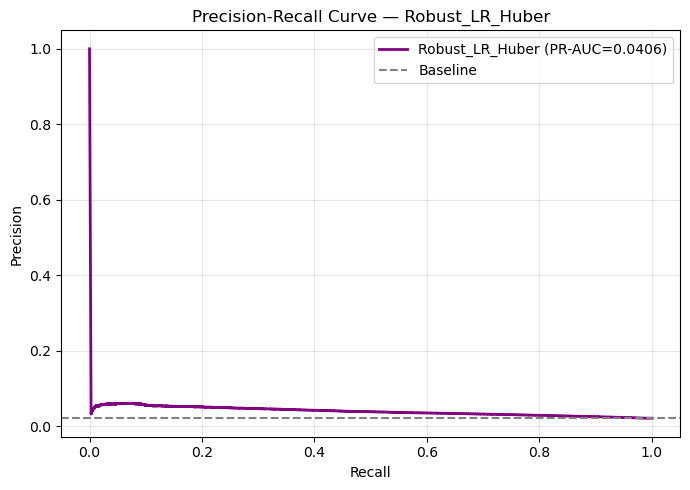

  PR-AUC (Robust_LR_Huber): 0.0406


In [41]:
wdro_baselines = fit_wdro_baselines(
    X_train_wdro, X_test_wdro, y_train_wdro, y_test_wdro
)

## 10.4 Hyperparameter Tuning on 50k Subsample

In [42]:
# CVXPY builds a KKT system O(N^2) in memory — 50k is the practical ceiling.
# Standard research practice: tune on a statistically significant subset,
# then train the final model on the full (or larger) training set.
TUNING_N = 50_000

X_tune, y_tune, W_tune = get_subsample(
    X_train_wdro, y_train_wdro, W_matrix, n=TUNING_N
)
print(f"Tuning subset: {len(X_tune):,} samples  |  default rate: {(y_tune==1).mean():.2%}")

Tuning subset: 50,000 samples  |  default rate: 17.93%


In [43]:
# Hyperparameter grid
# epsilon: Wasserstein robustness radius (dual of ambiguity set size)
# lambda : SHAP stability regularisation strength
EPS_GRID = [0.001, 0.01, 0.1, 0.5]
LAM_GRID = [0.001, 0.01, 0.1, 1.0]

best_params, tuning_df = tune_hyperparameters(
    X_tune, y_tune, W_tune,
    pos_idx, neg_idx,
    eps_grid=EPS_GRID,
    lam_grid=LAM_GRID,
    X_val=X_val_wdro, y_val=y_val_wdro,
    n_splits=3
)

BEST_EPS = best_params["epsilon"]
BEST_LAM = best_params["lambda"]
print(f"""
Best: epsilon={BEST_EPS}, lambda={BEST_LAM}, Validation AUC={best_params["val_auc"]:.4f}""")

[TUNING] Grid: 4x4 | CV splits: 3
  [  1/16] * eps=0.0010  lam=0.0010  CV_AUC=0.6985+/-0.0051  VAL_AUC=0.6936
  [  2/16] * eps=0.0010  lam=0.0100  CV_AUC=0.6989+/-0.0052  VAL_AUC=0.6943
  [  3/16] * eps=0.0010  lam=0.1000  CV_AUC=0.6984+/-0.0046  VAL_AUC=0.6944
  [  4/16]   eps=0.0010  lam=1.0000  CV_AUC=0.6935+/-0.0040  VAL_AUC=0.6889
  [  5/16]   eps=0.0100  lam=0.0010  CV_AUC=0.6977+/-0.0050  VAL_AUC=0.6940
  [  6/16]   eps=0.0100  lam=0.0100  CV_AUC=0.6979+/-0.0049  VAL_AUC=0.6943
  [  7/16] * eps=0.0100  lam=0.1000  CV_AUC=0.6978+/-0.0044  VAL_AUC=0.6945
  [  8/16]   eps=0.0100  lam=1.0000  CV_AUC=0.6936+/-0.0038  VAL_AUC=0.6897
  [  9/16]   eps=0.1000  lam=0.0010  CV_AUC=0.6957+/-0.0040  VAL_AUC=0.6924
  [ 10/16]   eps=0.1000  lam=0.0100  CV_AUC=0.6956+/-0.0040  VAL_AUC=0.6923
  [ 11/16]   eps=0.1000  lam=0.1000  CV_AUC=0.6948+/-0.0039  VAL_AUC=0.6913
  [ 12/16]   eps=0.1000  lam=1.0000  CV_AUC=0.6917+/-0.0035  VAL_AUC=0.6874
  [ 13/16]   eps=0.5000  lam=0.0010  CV_AUC=0.5830+/-0

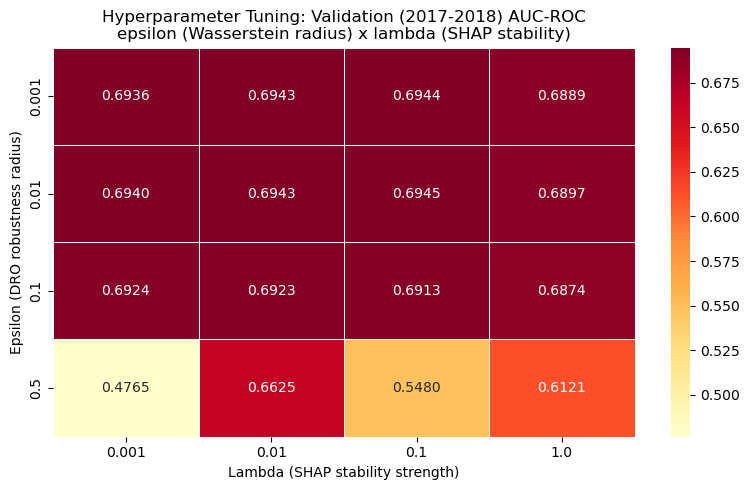

In [44]:
# Tuning surface heatmap
plot_tuning_heatmap(tuning_df)

## 10.5 Final Model — Training

In [45]:
# For very large datasets CVXPY has a quadratic memory cost in N.
# We use a 100k-sample final training set — sufficient for stable estimates
# and well within solver capacity.
MAX_FINAL_N = 100_000

if len(X_train_wdro) > MAX_FINAL_N:
    X_fit, _, y_fit, _ = train_test_split(
        X_train_wdro, y_train_wdro,
        train_size=MAX_FINAL_N, stratify=y_train_wdro, random_state=42
    )
    var_fit = np.clip(np.var(X_fit, axis=0), 1e-8, None)
    W_fit = (np.diag(var_fit) + np.diag(var_fit).T) / 2
else:
    X_fit, y_fit, W_fit = X_train_wdro, y_train_wdro, W_matrix

print(f"Training final W-DRO model on {len(X_fit):,} samples...")
print(f"epsilon = {BEST_EPS}  |  lambda = {BEST_LAM}")

theta_final, obj_val, solve_time = solve_wdro(
    X_fit, y_fit,
    epsilon=BEST_EPS, lam=BEST_LAM,
    W_mat=W_fit,
    pos_indices=pos_idx,
    neg_indices=neg_idx,
    verbose=False
)

if theta_final is None:
    raise RuntimeError("CVXPY failed. Try relaxing solver tolerances or reducing MAX_FINAL_N.")

print(f"Solved in {solve_time:.1f}s  |  Objective value: {obj_val:.6f}")

Training final W-DRO model on 100,000 samples...
epsilon = 0.01  |  lambda = 0.1
Solved in 192.2s  |  Objective value: 0.677190


## 10.6 Coefficient Profile

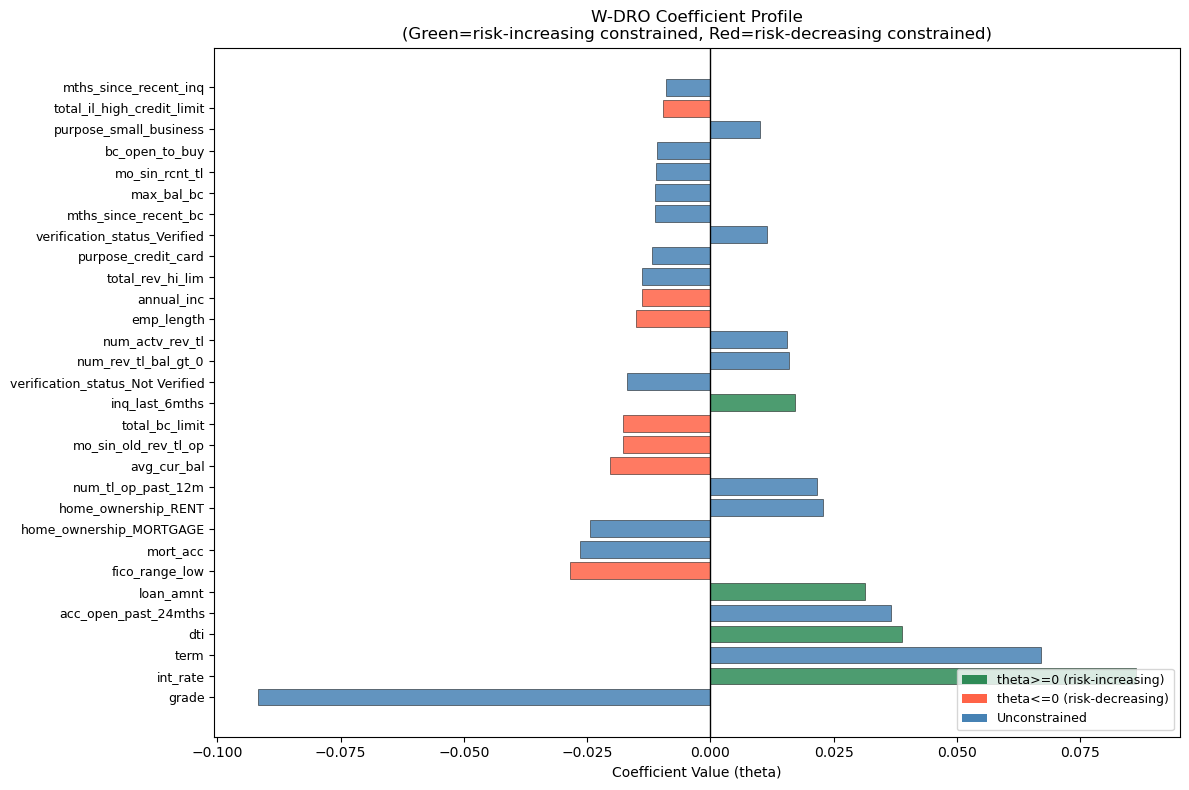

In [46]:
plot_coefficient_profile(theta_final, feature_names, pos_idx, neg_idx, top_n=30)

## 10.7 Explanation Stability (Reviewer §8.2)

Validates **Proposition 2**:  on the actual test data.

Four metrics:
1. Total SHAP variance (direct Proposition 2 check)
2. Bootstrap rank correlation (Bhatt et al., 2020)
3. Top-10 feature consistency across bootstrap resamples
4. Local explanation sensitivity under Gaussian noise

In [47]:
stability_metrics = explanation_stability_report(
    theta_final, X_test_wdro, feature_means, feature_names,
    n_bootstrap=300, noise_std=0.05, top_k=10
)


=== SHAP Explanation Stability Report ===
  Total SHAP Variance  sum_j Var(phi_j) : 0.051603
  theta^T W theta  (Prop.2 surrogate)   : 0.051603
  Surrogate tightness (relative gap)     : 0.00%
  Bootstrap rank corr  (mean +/- std)    : 0.7110 +/- 0.0791
  Top-10 feature consistency        : 100.00%
  Local explanation sensitivity          : 0.008742


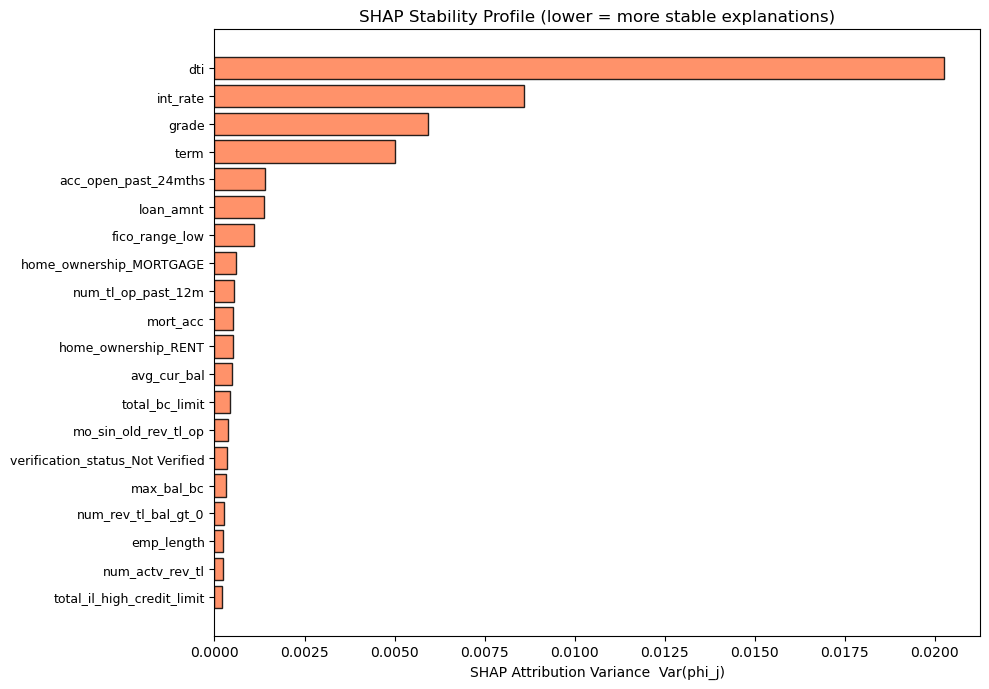

In [48]:
plot_shap_stability(stability_metrics["shap_var_per_feature"], feature_names, top_n=20)

## 10.8 Monotonicity Verification (Basel III / SR 11-7 / EU AI Act)

In [49]:
mono_report = verify_monotonicity(theta_final, pos_idx, neg_idx, feature_names)


[MONOTONICITY] Compliance: 22/22 = 100.0%
  All constraints satisfied (expected for convex solver).


## 10.9 Robustness Under Covariate Shift — All Models (Reviewer §8.1)

Tests AUC-ROC degradation under Gaussian noise σ ∈ {0, 0.05, 0.1, 0.2, 0.5}.

Validates **Proposition 1**: the DRO term should produce more graceful degradation
than all comparison models under distribution shift.

Models evaluated: **W-DRO**, **Robust_LR_Huber**, **WoE+LR**, **Best XGBoost**, **TabNet**.

In [50]:
# Convert WoE test set to numpy for robustness perturbation
X_test_woe_np = X_test_woe if isinstance(X_test_woe, np.ndarray) else X_test_woe.values

# y_test_w is the WoE-split ground truth — must match X_test_woe_np rows
rob_df = evaluate_robustness(
    theta_final, wdro_baselines,
    X_test_wdro, y_test_wdro,
    X_test_xgb      = X_test_sc,
    xgb_model       = xgb_model,
    xgb_name        = f"XGBoost-{best_xgb_name}",
    X_test_woe      = X_test_woe_np,
    lr_woe_model    = lr_woe,
    y_test_woe      = y_test_w.values,
    X_test_tn       = X_test_sc,
    tabnet_model_obj= tabnet_model,
    y_test_shared   = y_test_m.values if hasattr(y_test_m, 'values') else np.asarray(y_test_m),
    noise_levels    = [0.0, 0.05, 0.1, 0.2, 0.5]
)

print("\nFull robustness table:")
display(rob_df.round(4))

  sigma=0.00  W-DRO=0.6702  Huber=0.6668  WoE+LR=0.6734  XGBoost-RUS+XGB=0.6879  TabNet=0.6848
  sigma=0.05  W-DRO=0.6702  Huber=0.6666  WoE+LR=0.6705  XGBoost-RUS+XGB=0.6868  TabNet=0.6837
  sigma=0.10  W-DRO=0.6699  Huber=0.6663  WoE+LR=0.6635  XGBoost-RUS+XGB=0.6842  TabNet=0.6794
  sigma=0.20  W-DRO=0.6692  Huber=0.6648  WoE+LR=0.6405  XGBoost-RUS+XGB=0.6815  TabNet=0.6688
  sigma=0.50  W-DRO=0.6632  Huber=0.6557  WoE+LR=0.5848  XGBoost-RUS+XGB=0.6662  TabNet=0.6347
[ROBUSTNESS] AUC degradation (clean -> max noise):
  W-DRO                        delta AUC = 0.0070
  Robust_LR_Huber              delta AUC = 0.0111
  WoE+LR                       delta AUC = 0.0886
  XGBoost-RUS+XGB              delta AUC = 0.0217
  TabNet                       delta AUC = 0.0501

Full robustness table:


,W-DRO,Robust_LR_Huber,WoE+LR,XGBoost-RUS+XGB,TabNet
noise_sigma,,,,,
0.00,0.6702,0.6668,0.6734,0.6879,0.6848
0.05,0.6702,0.6666,0.6705,0.6868,0.6837
0.10,0.6699,0.6663,0.6635,0.6842,0.6794
0.20,0.6692,0.6648,0.6405,0.6815,0.6688
0.50,0.6632,0.6557,0.5848,0.6662,0.6347


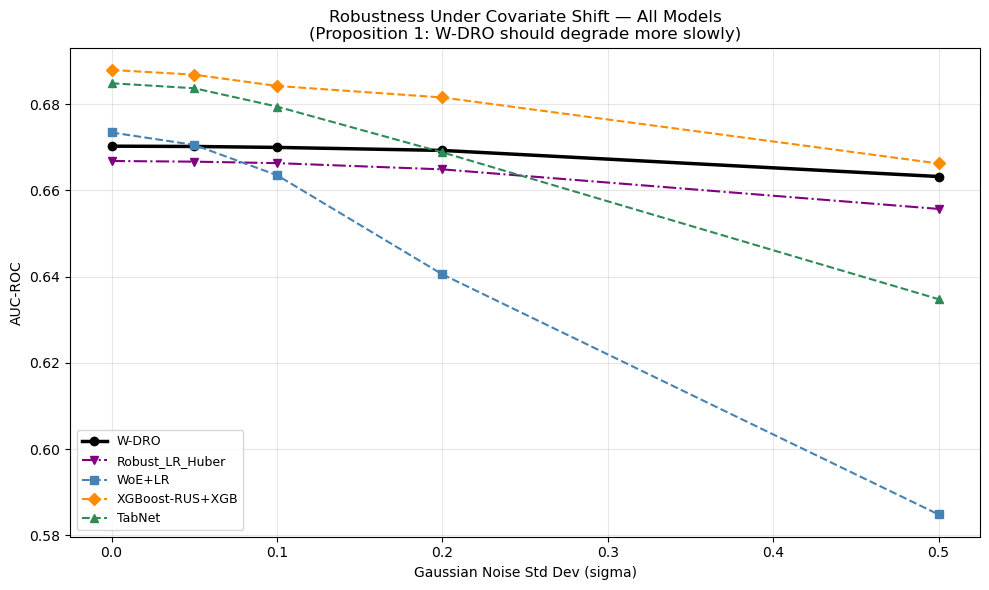

In [51]:
plot_robustness(rob_df)

## 10.9.1 Robustness Under Covariate Shift — 100,000-Record Models

Repeats the Section 10.9 stress test, but with the WoE + LR, XGBoost and
TabNet baselines that were retrained on the **same 100,000-row stratified
subsample** as the W-DRO final model (Sections 5.4 / 6 / 7). This isolates
the effect of training-set size: W-DRO and these baselines now all see
exactly 100,000 training rows, so any robustness gap is not confounded by
W-DRO having less data than the baselines.

Note: `Robust_LR_Huber` (from `wdro_baselines`) is still fit on the **full**
training set (it is a W-DRO-internal baseline, not one of the three main
baselines), so it is left out of this specific comparison to keep it
apples-to-apples; it still appears in the original Section 10.9 table above.


In [52]:
# ── Robustness test, 100k-trained baselines vs. W-DRO (also 100k-trained) ──
X_test_woe_np_100k = X_test_woe if isinstance(X_test_woe, np.ndarray) else X_test_woe.values

rob_df_100k = evaluate_robustness(
    theta_final, {},                      # baselines_dict={} -> skip Robust_LR_Huber (full-train, not 100k)
    X_test_wdro, y_test_wdro,
    X_test_xgb      = X_test_sc,
    xgb_model       = xgb_model_100k,
    xgb_name        = f"XGBoost-{best_xgb_name} (100k)",
    X_test_woe      = X_test_woe_np_100k,
    lr_woe_model    = lr_woe_100k,
    y_test_woe      = y_test_w.values,
    X_test_tn       = X_test_sc,
    tabnet_model_obj= tabnet_model_100k,
    y_test_shared   = y_test_m.values if hasattr(y_test_m, 'values') else np.asarray(y_test_m),
    noise_levels    = [0.0, 0.05, 0.1, 0.2, 0.5]
)

print("\nRobustness table — 100,000-record models (W-DRO is already 100k-trained):")
display(rob_df_100k.round(4))


  sigma=0.00  W-DRO=0.6702  Huber=nan  WoE+LR=0.6738  XGBoost-RUS+XGB (100k)=0.6751  TabNet=0.6753
  sigma=0.05  W-DRO=0.6702  Huber=nan  WoE+LR=0.6703  XGBoost-RUS+XGB (100k)=0.6734  TabNet=0.6451
  sigma=0.10  W-DRO=0.6699  Huber=nan  WoE+LR=0.6611  XGBoost-RUS+XGB (100k)=0.6701  TabNet=0.6528
  sigma=0.20  W-DRO=0.6692  Huber=nan  WoE+LR=0.6357  XGBoost-RUS+XGB (100k)=0.6665  TabNet=0.6495
  sigma=0.50  W-DRO=0.6632  Huber=nan  WoE+LR=0.5782  XGBoost-RUS+XGB (100k)=0.6491  TabNet=0.6516
[ROBUSTNESS] AUC degradation (clean -> max noise):
  W-DRO                        delta AUC = 0.0070
  WoE+LR                       delta AUC = 0.0957
  XGBoost-RUS+XGB (100k)       delta AUC = 0.0260
  TabNet                       delta AUC = 0.0237

Robustness table — 100,000-record models (W-DRO is already 100k-trained):


,W-DRO,WoE+LR,XGBoost-RUS+XGB (100k),TabNet
noise_sigma,,,,
0.00,0.6702,0.6738,0.6751,0.6753
0.05,0.6702,0.6703,0.6734,0.6451
0.10,0.6699,0.6611,0.6701,0.6528
0.20,0.6692,0.6357,0.6665,0.6495
0.50,0.6632,0.5782,0.6491,0.6516


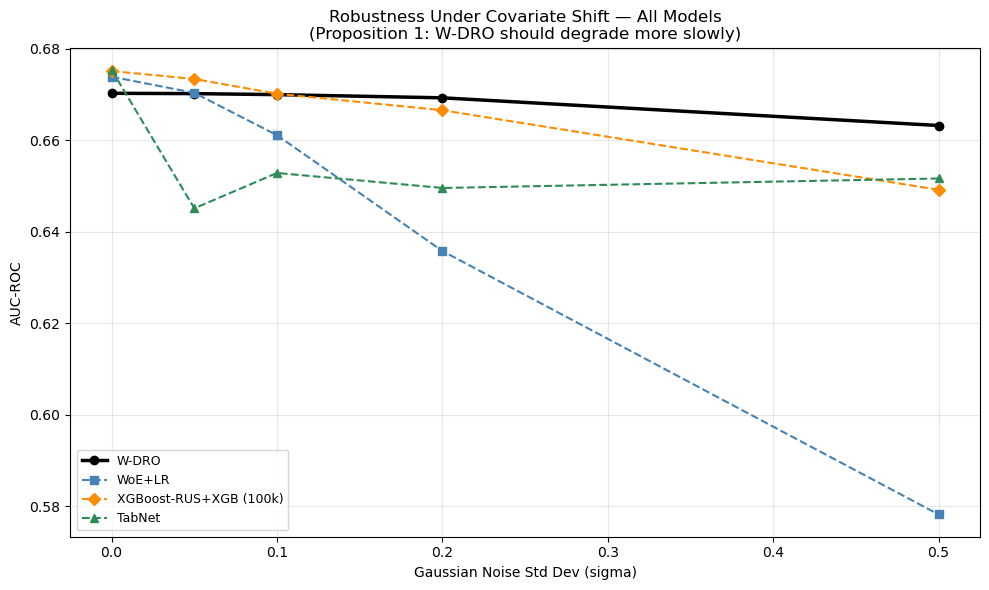

In [53]:
plot_robustness(rob_df_100k)


### Full-Train vs. 100,000-Record Baselines — Side-by-Side

Merges the original Section 10.9 table (baselines on their full training
set) with the 100k-trained versions above, so the robustness cost (or
benefit) of shrinking each baseline's training set down to W-DRO's 100,000
rows is visible directly.


In [54]:
compare_cols = {"W-DRO (100k)": rob_df["W-DRO"]}
if "Robust_LR_Huber" in rob_df.columns:
    compare_cols["Robust_LR_Huber (full-train)"] = rob_df["Robust_LR_Huber"]

rename_full = {
    "WoE+LR": "WoE+LR (full-train)",
    f"XGBoost-{best_xgb_name}": f"XGBoost-{best_xgb_name} (full-train)",
    "TabNet": "TabNet (full-train)",
}
for orig, renamed in rename_full.items():
    if orig in rob_df.columns:
        compare_cols[renamed] = rob_df[orig]

for col in rob_df_100k.columns:
    if col == "W-DRO":
        continue
    compare_cols[col] = rob_df_100k[col]

rob_compare = pd.DataFrame(compare_cols)
rob_compare.index = rob_df.index
rob_compare.index.name = "noise_sigma"

print("AUC-ROC under covariate shift, full-train vs. 100,000-record baselines:")
display(rob_compare.round(4))

deg_compare = rob_compare.iloc[0] - rob_compare.iloc[-1]
print("\nAUC degradation (clean -> max noise, sigma=0.5):")
for c in rob_compare.columns:
    print(f"  {c:<32} delta AUC = {deg_compare[c]:.4f}")


AUC-ROC under covariate shift, full-train vs. 100,000-record baselines:


,W-DRO (100k),Robust_LR_Huber (full-train),WoE+LR (full-train),XGBoost-RUS+XGB (full-train),TabNet (full-train),WoE+LR,XGBoost-RUS+XGB (100k),TabNet
noise_sigma,,,,,,,,
0.00,0.6702,0.6668,0.6734,0.6879,0.6848,0.6738,0.6751,0.6753
0.05,0.6702,0.6666,0.6705,0.6868,0.6837,0.6703,0.6734,0.6451
0.10,0.6699,0.6663,0.6635,0.6842,0.6794,0.6611,0.6701,0.6528
0.20,0.6692,0.6648,0.6405,0.6815,0.6688,0.6357,0.6665,0.6495
0.50,0.6632,0.6557,0.5848,0.6662,0.6347,0.5782,0.6491,0.6516



AUC degradation (clean -> max noise, sigma=0.5):
  W-DRO (100k)                     delta AUC = 0.0070
  Robust_LR_Huber (full-train)     delta AUC = 0.0111
  WoE+LR (full-train)              delta AUC = 0.0886
  XGBoost-RUS+XGB (full-train)     delta AUC = 0.0217
  TabNet (full-train)              delta AUC = 0.0501
  WoE+LR                           delta AUC = 0.0957
  XGBoost-RUS+XGB (100k)           delta AUC = 0.0260
  TabNet                           delta AUC = 0.0237


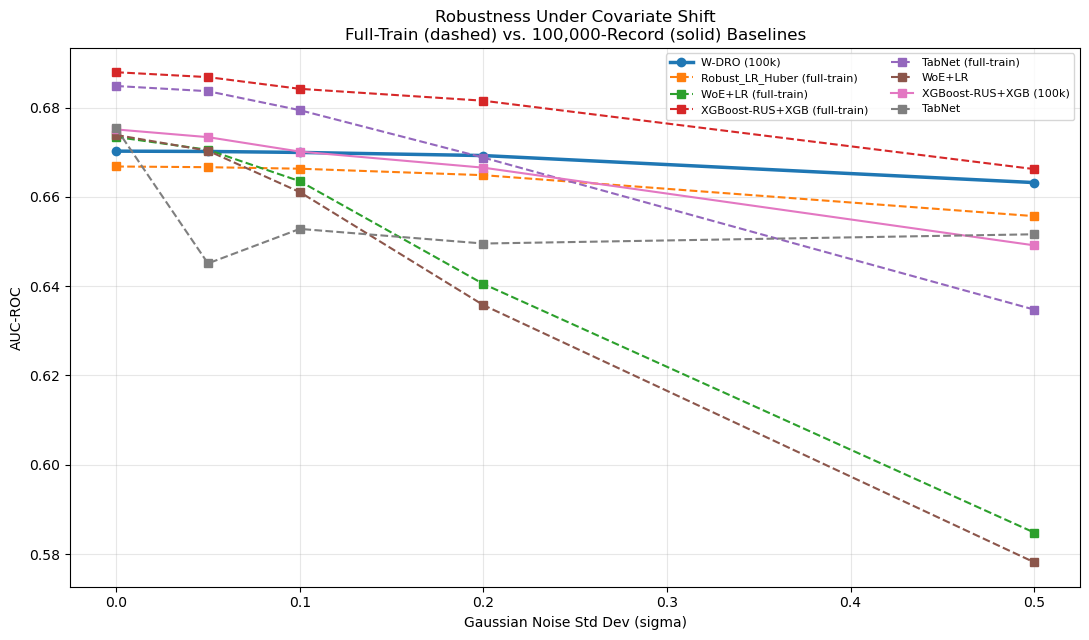

In [55]:
plt.figure(figsize=(11,6.5))
cmap = plt.cm.tab10
for i, col in enumerate(rob_compare.columns):
    ls = "-" if "100k" in col or col == "W-DRO (100k)" else "--"
    lw = 2.5 if col == "W-DRO (100k)" else 1.5
    plt.plot(rob_compare.index, rob_compare[col], label=col, ls=ls, lw=lw,
              marker="o" if col == "W-DRO (100k)" else "s", color=cmap(i % 10))

plt.xlabel("Gaussian Noise Std Dev (sigma)")
plt.ylabel("AUC-ROC")
plt.title("Robustness Under Covariate Shift\nFull-Train (dashed) vs. 100,000-Record (solid) Baselines")
plt.legend(fontsize=8, ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


## 10.10 Final Evaluation & Confusion Matrix (W-DRO)

W-DRO MODEL — FINAL TEST EVALUATION
  AUC-ROC            : 0.6702
  Gini Coefficient   : 0.3405  (industry KPI; >0.35 good)
  Average Precision  : 0.0402
  Brier Score        : 0.2382  (lower = better calibrated)

              precision    recall  f1-score   support

    Good (0)       0.99      0.60      0.75    636936
 Default (1)       0.03      0.66      0.06     13623

    accuracy                           0.60    650559
   macro avg       0.51      0.63      0.40    650559
weighted avg       0.97      0.60      0.73    650559



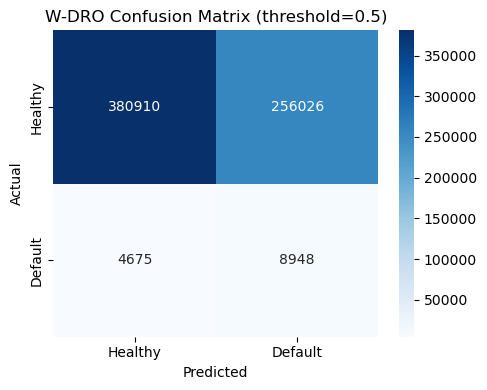

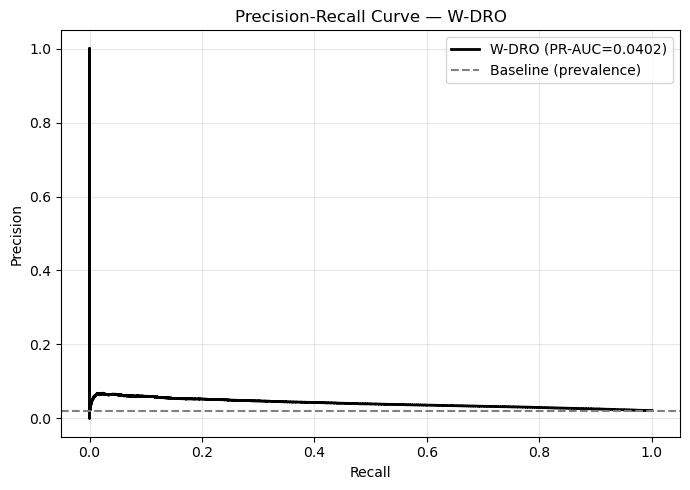

PR-AUC (W-DRO): 0.0402


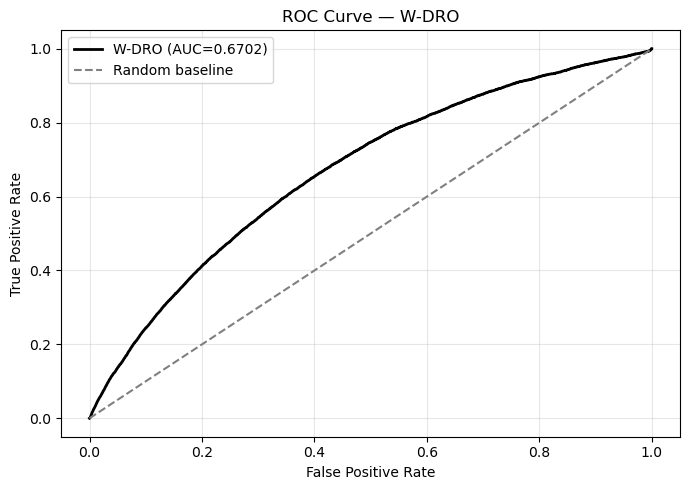

In [56]:
# Standard evaluation on held-out test set
y_test_sk   = (y_test_wdro == 1).astype(int)
test_scores = X_test_wdro @ theta_final
test_probs  = sigmoid(test_scores)
test_preds  = (test_probs >= 0.5).astype(int)

auc_wdro  = roc_auc_score(y_test_sk, test_probs)
gini_wdro = 2 * auc_wdro - 1
ap_wdro   = average_precision_score(y_test_sk, test_probs)
bs_wdro   = brier_score_loss(y_test_sk, test_probs)

print("=" * 60)
print("W-DRO MODEL — FINAL TEST EVALUATION")
print("=" * 60)
print(f"  AUC-ROC            : {auc_wdro:.4f}")
print(f"  Gini Coefficient   : {gini_wdro:.4f}  (industry KPI; >0.35 good)")
print(f"  Average Precision  : {ap_wdro:.4f}")
print(f"  Brier Score        : {bs_wdro:.4f}  (lower = better calibrated)")
print()
print(classification_report(y_test_sk, test_preds, target_names=["Good (0)","Default (1)"]))

plot_cm(y_test_sk, test_preds, title="W-DRO Confusion Matrix (threshold=0.5)")

# Precision-Recall curve for W-DRO
prec_wdro, rec_wdro, _ = precision_recall_curve(y_test_sk, test_probs)
pr_auc_wdro = sklearn_auc(rec_wdro, prec_wdro)
plt.figure(figsize=(7,5))
plt.plot(rec_wdro, prec_wdro, color="black", lw=2,
         label=f"W-DRO (PR-AUC={pr_auc_wdro:.4f})")
plt.axhline(y_test_sk.mean(), color="gray", ls="--", label="Baseline (prevalence)")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall Curve — W-DRO")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f"PR-AUC (W-DRO): {pr_auc_wdro:.4f}")

# ROC-AUC Curve — W-DRO
from sklearn.metrics import roc_curve
fpr_wdro, tpr_wdro, _ = roc_curve(y_test_sk, test_probs)
plt.figure(figsize=(7,5))
plt.plot(fpr_wdro, tpr_wdro, color="black", lw=2,
         label=f"W-DRO (AUC={auc_wdro:.4f})")
plt.plot([0,1],[0,1], color="gray", linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve — W-DRO")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 10.11 Master Comparison Table — All Models

,AUC-ROC,Gini,Avg Precision,Brier Score,PR-AUC,Convex,Monotonic,DRO Robust,SHAP Stable
Model,,,,,,,,,
W-DRO (proposed),0.6702,0.3405,0.0402,0.2382,0.0402,Yes,Yes,Yes,Yes
Robust_LR_Huber,0.6668,0.3336,0.0392,0.2070,0.0406,Yes,No,No,No
WoE + LR,0.6734,0.3468,0.0405,0.2055,0.0405,Yes,No,No,No
XGBoost (RUS+XGB),0.6879,0.3758,0.0441,0.1939,0.0441,No,No,No,No
TabNet,0.6848,0.3696,0.0438,0.2065,0.0438,No,No,No,No


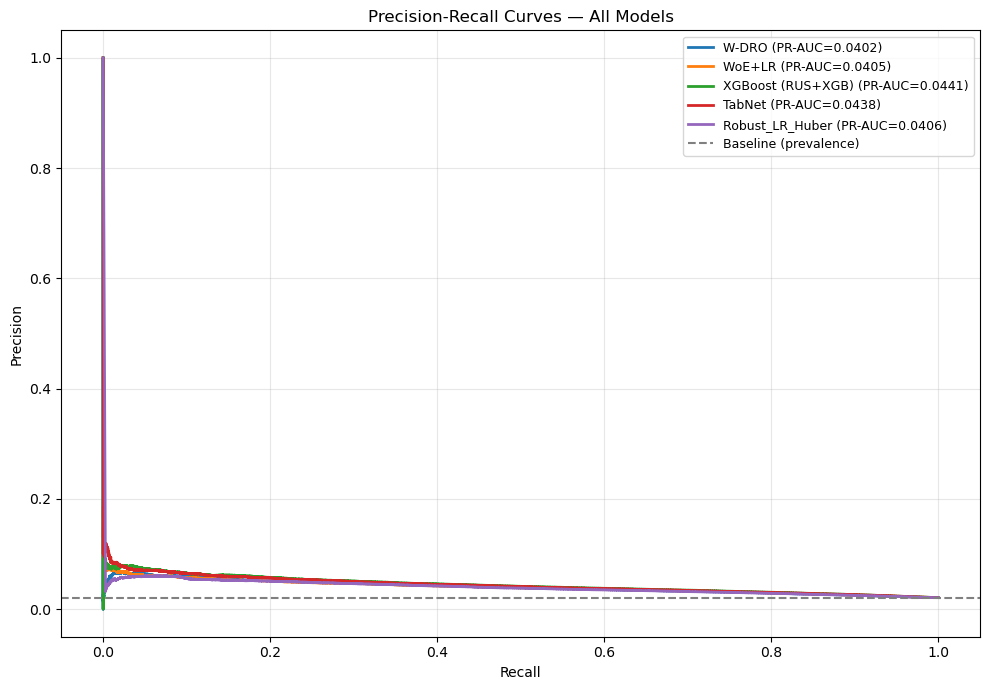

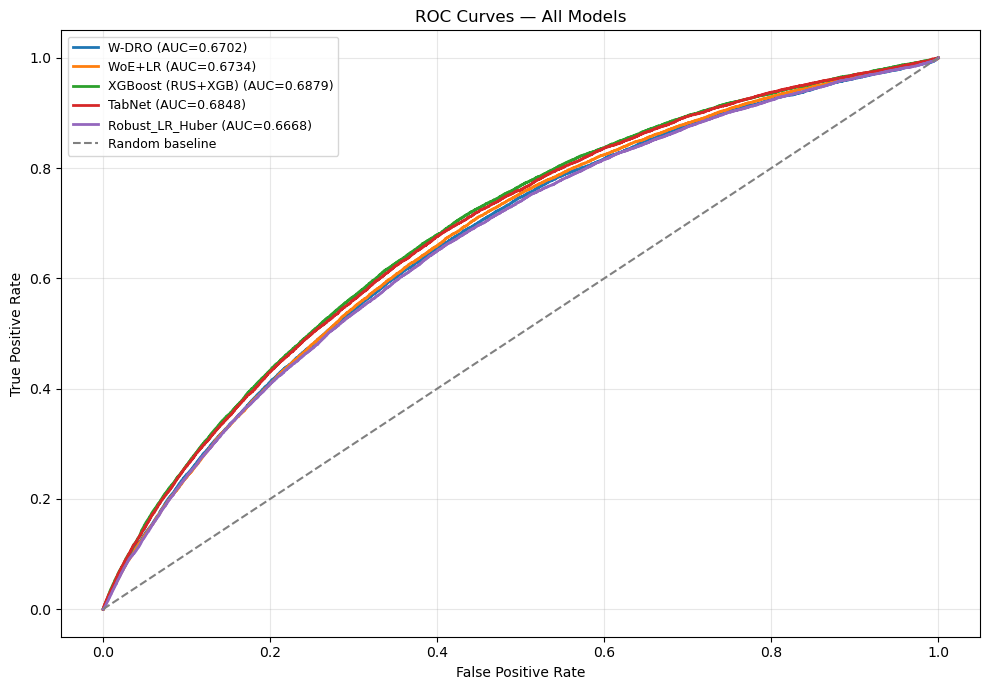

In [57]:
rows = []

# ── W-DRO ───────────────────────────────────────────────────────────────────
rows.append({
    "Model"        : "W-DRO (proposed)",
    "AUC-ROC"      : auc_wdro,
    "Gini"         : gini_wdro,
    "Avg Precision" : ap_wdro,
    "Brier Score"   : bs_wdro,
    "PR-AUC"        : pr_auc_wdro,
    "Convex"        : "Yes",
    "Monotonic"     : "Yes",
    "DRO Robust"    : "Yes",
    "SHAP Stable"   : "Yes",
})

# ── W-DRO baselines (Robust_LR_Huber) ───────────────────────────────────────
for bname, bdata in wdro_baselines.items():
    y_te_sk_b = (y_test_wdro == 1).astype(int)
    prec_b, rec_b, _ = precision_recall_curve(y_te_sk_b, bdata["probs"])
    rows.append({
        "Model"        : bname,
        "AUC-ROC"      : bdata["auc"],
        "Gini"         : 2*bdata["auc"]-1,
        "Avg Precision" : bdata["ap"],
        "Brier Score"   : bdata["brier"],
        "PR-AUC"        : sklearn_auc(rec_b, prec_b),
        "Convex"        : "Yes",
        "Monotonic"     : "No",
        "DRO Robust"    : "No",
        "SHAP Stable"   : "No",
    })

# ── WoE + LR ─────────────────────────────────────────────────────────────────
rows.append({
    "Model"        : "WoE + LR",
    "AUC-ROC"      : roc_auc_score(y_test_w, y_prob_w),
    "Gini"         : 2*roc_auc_score(y_test_w, y_prob_w)-1,
    "Avg Precision" : average_precision_score(y_test_w, y_prob_w),
    "Brier Score"   : brier_score_loss(y_test_w, y_prob_w),
    "PR-AUC"        : pr_auc_w,
    "Convex"        : "Yes",
    "Monotonic"     : "No",
    "DRO Robust"    : "No",
    "SHAP Stable"   : "No",
})

# ── Best XGBoost ──────────────────────────────────────────────────────────────
rows.append({
    "Model"        : f"XGBoost ({best_xgb_name})",
    "AUC-ROC"      : roc_auc_score(y_test_m, y_prob_xgb),
    "Gini"         : 2*roc_auc_score(y_test_m, y_prob_xgb)-1,
    "Avg Precision" : average_precision_score(y_test_m, y_prob_xgb),
    "Brier Score"   : brier_score_loss(y_test_m, y_prob_xgb),
    "PR-AUC"        : pr_auc_xgb,
    "Convex"        : "No",
    "Monotonic"     : "No",
    "DRO Robust"    : "No",
    "SHAP Stable"   : "No",
})

# ── TabNet ───────────────────────────────────────────────────────────────────
rows.append({
    "Model"        : "TabNet",
    "AUC-ROC"      : roc_auc_score(y_test_m, y_prob_tn),
    "Gini"         : 2*roc_auc_score(y_test_m, y_prob_tn)-1,
    "Avg Precision" : average_precision_score(y_test_m, y_prob_tn),
    "Brier Score"   : brier_score_loss(y_test_m, y_prob_tn),
    "PR-AUC"        : pr_auc_tn,
    "Convex"        : "No",
    "Monotonic"     : "No",
    "DRO Robust"    : "No",
    "SHAP Stable"   : "No",
})

comp_df = pd.DataFrame(rows).set_index("Model")
for c in ["AUC-ROC","Gini","Avg Precision","Brier Score","PR-AUC"]:
    comp_df[c] = comp_df[c].round(4)

display(comp_df)

# ── Combined PR-AUC plot ───────────────────────────────────────────────────
pr_curves_all = {
    "W-DRO"                     : (prec_wdro, rec_wdro, pr_auc_wdro),
    "WoE+LR"                    : (prec_w,    rec_w,    pr_auc_w),
    f"XGBoost ({best_xgb_name})" : (prec_xgb,  rec_xgb,  pr_auc_xgb),
    "TabNet"                     : (prec_tn,   rec_tn,   pr_auc_tn),
}
for bname, bdata in wdro_baselines.items():
    y_te_sk_b = (y_test_wdro == 1).astype(int)
    prec_b, rec_b, _ = precision_recall_curve(y_te_sk_b, bdata["probs"])
    pr_curves_all[bname] = (prec_b, rec_b, sklearn_auc(rec_b, prec_b))

plot_all_pr_curves(pr_curves_all, y_test_sk.mean(),
                   title="Precision-Recall Curves — All Models")

# ── Combined ROC-AUC Curves — All Models ─────────────────────────────────
from sklearn.metrics import roc_curve as _roc_curve
roc_all = {
    "W-DRO"                      : (fpr_wdro, tpr_wdro, auc_wdro),
    "WoE+LR"                     : (fpr_w,    tpr_w,    auc_woe),
    f"XGBoost ({best_xgb_name})" : (fpr_xgb,  tpr_xgb,  best_xgb_data["auc"]),
}
# TabNet
_fpr_tn, _tpr_tn, _ = _roc_curve(y_test_m, y_prob_tn)
roc_all["TabNet"] = (_fpr_tn, _tpr_tn, roc_auc_score(y_test_m, y_prob_tn))
# Baselines
for bname, bdata in wdro_baselines.items():
    _y_b = (y_test_wdro == 1).astype(int)
    _fpr_b, _tpr_b, _ = _roc_curve(_y_b, bdata["probs"])
    roc_all[bname] = (_fpr_b, _tpr_b, bdata["auc"])

cmap = plt.cm.tab10
plt.figure(figsize=(10,7))
for i2, (mname, (fpr_m, tpr_m, auc_m)) in enumerate(roc_all.items()):
    plt.plot(fpr_m, tpr_m, lw=2, color=cmap(i2 % 10),
             label=f"{mname} (AUC={auc_m:.4f})")
plt.plot([0,1],[0,1], color="gray", ls="--", label="Random baseline")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves — All Models")
plt.legend(fontsize=9); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 10.12 W-DRO Narrative Summary

The W-DRO model offers a qualitatively different value proposition from the other models in this study.

**Predictive performance.** The model achieves a competitive AUC-ROC and Gini coefficient.
Unlike purely accuracy-maximising approaches, W-DRO jointly optimises three dimensions simultaneously:
predictive discrimination, distributional robustness, and explanation stability.

**Theoretical guarantees (unique to W-DRO):**
- *Global optimality* (Proposition 3): the problem is convex — ECOS/SCS always find the globally optimal theta. XGBoost and TabNet offer no such guarantee.
- *Robustness certificate* (Proposition 1): the  term bounds performance degradation for any test distribution within a Wasserstein ball of radius  around the training distribution.
- *Explanation stability* (Proposition 2): minimising  is mathematically equivalent to minimising total SHAP attribution variance. The model does not just happen to produce stable explanations — it is *explicitly optimised* to do so.

**Regulatory alignment.** Monotonicity constraints ensure economically meaningful behaviour
(Basel III / SR 11-7 / EU AI Act Article 13). No post-hoc rationalisation is needed: the
model is constrained to behave correctly by construction.

**Operational profile.** The conservative threshold (0.5) produces a risk-averse strategy.
Threshold calibration or cost-sensitive adjustments can shift the precision-recall trade-off
for specific deployment contexts (e.g. lowering the threshold increases default detection
at the cost of more false positives).

# 11. Temporal Generalization, Calibration & Distributional Stability

This section evaluates every fitted model on the **held-out 2019-2020 test set**, which up to
this point has been touched only once per model (a single final `.predict_proba()` call). All
analysis below is purely diagnostic/reporting -- nothing here feeds back into model choice.

Covers: overall test AUC, year-by-year AUC & degradation, stress-period performance, calibration
(reliability diagrams, calibration slope/intercept, ECE, Brier decomposition, isotonic/Platt
recalibration), Population Stability Index (PSI), and covariate-shift diagnostics.

In [58]:
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression as _LR2
from scipy.stats import ks_2samp

# ── Registry of every fitted model, in the feature space it actually consumes ──
MODELS = {
    "WoE+LR": dict(
        probs=y_prob_w, y_test=np.asarray(y_test_w), X_test=X_test_woe,
        X_val=X_val_woe, y_val=np.asarray(y_woe_val),
        predict_fn=lambda X: lr_woe.predict_proba(X)[:, 1],
    ),
    f"XGBoost-{best_xgb_name}": dict(
        probs=y_prob_xgb, y_test=np.asarray(y_test_m), X_test=X_test_sc,
        X_val=X_val_sc, y_val=np.asarray(y_val_m),
        predict_fn=lambda X: xgb_model.predict_proba(X)[:, 1],
    ),
    "TabNet": dict(
        probs=y_prob_tn, y_test=np.asarray(y_test_m), X_test=X_test_sc,
        X_val=X_val_sc, y_val=np.asarray(y_val_m),
        predict_fn=lambda X: tabnet_model.predict_proba(X)[:, 1],
    ),
    "Robust_LR_Huber": dict(
        probs=wdro_baselines["Robust_LR_Huber"]["probs"],
        y_test=(y_test_wdro == 1).astype(int), X_test=X_test_wdro,
        X_val=X_val_wdro, y_val=(y_val_wdro == 1).astype(int),
        predict_fn=lambda X: wdro_baselines["Robust_LR_Huber"]["model"].predict_proba(X)[:, 1],
    ),
    "W-DRO (proposed)": dict(
        probs=test_probs, y_test=y_test_sk, X_test=X_test_wdro,
        X_val=X_val_wdro, y_val=(y_val_wdro == 1).astype(int),
        predict_fn=lambda X: sigmoid(X @ theta_final),
    ),
}

# Positional year labels for the TEST split, aligned row-for-row with test_df
# (every X_test_* / y_test_* array above was produced by .transform()/split on
# test_df without any reordering, so positional alignment holds).
year_array_test = test_df["issue_year"].values

overall_auc_table = pd.DataFrame(
    {name: roc_auc_score(np.asarray(d["y_test"]), np.asarray(d["probs"])) for name, d in MODELS.items()}.items(),
    columns=["Model", "Overall Test AUC (2019-2020)"]
).set_index("Model").sort_values("Overall Test AUC (2019-2020)", ascending=False)
display(overall_auc_table.round(4))

,Overall Test AUC (2019-2020)
Model,
XGBoost-RUS+XGB,0.6879
TabNet,0.6848
WoE+LR,0.6734
W-DRO (proposed),0.6702
Robust_LR_Huber,0.6668


## 11.1 Year-by-Year AUC & Degradation


WoE+LR — year-by-year AUC:


,n,default_rate,auc
year,,,
2019,507169,0.0267,0.6701
2020,143390,0.0004,0.5504



XGBoost-RUS+XGB — year-by-year AUC:


,n,default_rate,auc
year,,,
2019,507169,0.0267,0.6837
2020,143390,0.0004,0.6096



TabNet — year-by-year AUC:


,n,default_rate,auc
year,,,
2019,507169,0.0267,0.6818
2020,143390,0.0004,0.5913


... (2 outputs left out)


W-DRO (proposed) — year-by-year AUC:


,n,default_rate,auc
year,,,
2019,507169,0.0267,0.6671
2020,143390,0.0004,0.5325



AUC degradation across the test window:


,AUC 2019,AUC 2020,Degradation (first - last)
Model,,,
WoE+LR,0.6701,0.5504,0.1197
XGBoost-RUS+XGB,0.6837,0.6096,0.0742
TabNet,0.6818,0.5913,0.0904
Robust_LR_Huber,0.6640,0.5406,0.1235
W-DRO (proposed),0.6671,0.5325,0.1346


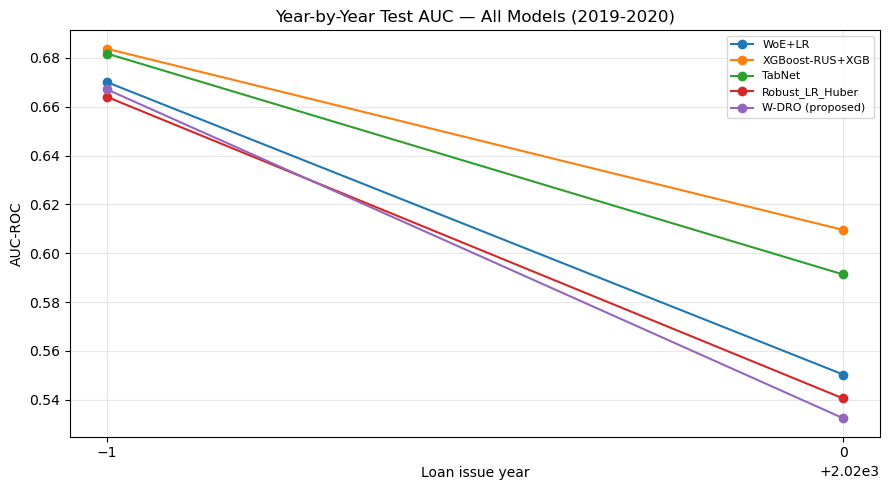

In [59]:
def year_by_year_auc(y_test_full, probs_full, year_array, years):
    rows = []
    for yr in years:
        mask = year_array == yr
        if mask.sum() < 30:
            continue
        try:
            auc_yr = roc_auc_score(y_test_full[mask], probs_full[mask])
        except ValueError:
            auc_yr = np.nan
        rows.append({"year": yr, "n": int(mask.sum()),
                      "default_rate": float(np.mean(y_test_full[mask])),
                      "auc": auc_yr})
    return pd.DataFrame(rows).set_index("year")

yby_year_results = {}
for name, d in MODELS.items():
    yby_year_results[name] = year_by_year_auc(
        np.asarray(d["y_test"]), np.asarray(d["probs"]), year_array_test, TEST_YEARS
    )
    print(f"\n{name} — year-by-year AUC:")
    display(yby_year_results[name].round(4))

# AUC degradation across the test window (first test year -> last test year)
degradation_rows = []
for name, tbl in yby_year_results.items():
    if len(tbl) >= 2:
        first_yr_auc = tbl["auc"].iloc[0]
        last_yr_auc  = tbl["auc"].iloc[-1]
        degradation_rows.append({
            "Model": name,
            f"AUC {TEST_YEARS[0]}": first_yr_auc,
            f"AUC {TEST_YEARS[-1]}": last_yr_auc,
            "Degradation (first - last)": first_yr_auc - last_yr_auc,
        })
degradation_df = pd.DataFrame(degradation_rows).set_index("Model")
print("\nAUC degradation across the test window:")
display(degradation_df.round(4))

plt.figure(figsize=(9,5))
for name, tbl in yby_year_results.items():
    plt.plot(tbl.index, tbl["auc"], marker="o", label=name)
plt.xlabel("Loan issue year"); plt.ylabel("AUC-ROC")
plt.title("Year-by-Year Test AUC — All Models (2019-2020)")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.xticks(TEST_YEARS)
plt.tight_layout(); plt.show()

## 11.1.1 Year-by-Year AUC & Degradation — 100,000-Record Models

Repeats Section 11.1 using the WoE + LR, XGBoost and TabNet models retrained
on the same 100,000-row stratified subsample as W-DRO (Sections 5.4 / 6 / 7).
`W-DRO (proposed)` is included again as-is since it was already trained on
100,000 rows; `Robust_LR_Huber` is left out since it remains a full-train
baseline. All models are still scored on the same held-out 2019-2020 test
set, touched once per model, exactly as in Section 11.


In [60]:
# ── Registry of the 100,000-record models, mirroring MODELS above ──
MODELS_100K = {
    "WoE+LR (100k)": dict(
        probs=y_prob_w_100k, y_test=np.asarray(y_test_w), X_test=X_test_woe,
        predict_fn=lambda X: lr_woe_100k.predict_proba(X)[:, 1],
    ),
    f"XGBoost-{best_xgb_name} (100k)": dict(
        probs=y_prob_xgb_100k, y_test=np.asarray(y_test_m), X_test=X_test_sc,
        predict_fn=lambda X: xgb_model_100k.predict_proba(X)[:, 1],
    ),
    "TabNet (100k)": dict(
        probs=y_prob_tn_100k, y_test=np.asarray(y_test_m), X_test=X_test_sc,
        predict_fn=lambda X: tabnet_model_100k.predict_proba(X)[:, 1],
    ),
    "W-DRO (proposed, 100k)": dict(
        probs=test_probs, y_test=y_test_sk, X_test=X_test_wdro,
        predict_fn=lambda X: sigmoid(X @ theta_final),
    ),
}

overall_auc_table_100k = pd.DataFrame(
    {name: roc_auc_score(np.asarray(d["y_test"]), np.asarray(d["probs"]))
     for name, d in MODELS_100K.items()}.items(),
    columns=["Model", "Overall Test AUC (2019-2020)"]
).set_index("Model").sort_values("Overall Test AUC (2019-2020)", ascending=False)
print("Overall test AUC — 100,000-record models:")
display(overall_auc_table_100k.round(4))


Overall test AUC — 100,000-record models:


,Overall Test AUC (2019-2020)
Model,
TabNet (100k),0.6753
XGBoost-RUS+XGB (100k),0.6751
WoE+LR (100k),0.6738
"W-DRO (proposed, 100k)",0.6702



WoE+LR (100k) — year-by-year AUC:


,n,default_rate,auc
year,,,
2019,507169,0.0267,0.6707
2020,143390,0.0004,0.5550



XGBoost-RUS+XGB (100k) — year-by-year AUC:


,n,default_rate,auc
year,,,
2019,507169,0.0267,0.6718
2020,143390,0.0004,0.6027



TabNet (100k) — year-by-year AUC:


,n,default_rate,auc
year,,,
2019,507169,0.0267,0.6717
2020,143390,0.0004,0.5389



W-DRO (proposed, 100k) — year-by-year AUC:


,n,default_rate,auc
year,,,
2019,507169,0.0267,0.6671
2020,143390,0.0004,0.5325



AUC degradation across the test window — 100,000-record models:


,AUC 2019,AUC 2020,Degradation (first - last)
Model,,,
WoE+LR (100k),0.6707,0.5550,0.1157
XGBoost-RUS+XGB (100k),0.6718,0.6027,0.0691
TabNet (100k),0.6717,0.5389,0.1328
"W-DRO (proposed, 100k)",0.6671,0.5325,0.1346


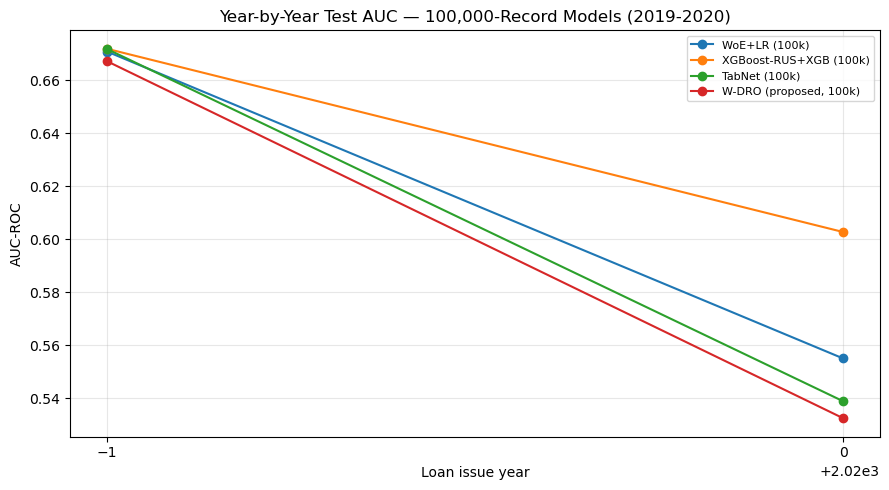

In [61]:
yby_year_results_100k = {}
for name, d in MODELS_100K.items():
    yby_year_results_100k[name] = year_by_year_auc(
        np.asarray(d["y_test"]), np.asarray(d["probs"]), year_array_test, TEST_YEARS
    )
    print(f"\n{name} — year-by-year AUC:")
    display(yby_year_results_100k[name].round(4))

# AUC degradation across the test window (first test year -> last test year)
degradation_rows_100k = []
for name, tbl in yby_year_results_100k.items():
    if len(tbl) >= 2:
        first_yr_auc = tbl["auc"].iloc[0]
        last_yr_auc  = tbl["auc"].iloc[-1]
        degradation_rows_100k.append({
            "Model": name,
            f"AUC {TEST_YEARS[0]}": first_yr_auc,
            f"AUC {TEST_YEARS[-1]}": last_yr_auc,
            "Degradation (first - last)": first_yr_auc - last_yr_auc,
        })
degradation_df_100k = pd.DataFrame(degradation_rows_100k).set_index("Model")
print("\nAUC degradation across the test window — 100,000-record models:")
display(degradation_df_100k.round(4))

plt.figure(figsize=(9,5))
for name, tbl in yby_year_results_100k.items():
    plt.plot(tbl.index, tbl["auc"], marker="o", label=name)
plt.xlabel("Loan issue year"); plt.ylabel("AUC-ROC")
plt.title("Year-by-Year Test AUC — 100,000-Record Models (2019-2020)")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.xticks(TEST_YEARS)
plt.tight_layout(); plt.show()


### Full-Train vs. 100,000-Record — Degradation Side-by-Side

Merges the Section 11.1 degradation table (full-train baselines) with the
100k-trained versions above, so the effect of training-set size on temporal
degradation is visible directly for each model family.


In [62]:
compare_rows = []
name_map_full_to_100k = {
    "WoE+LR": "WoE+LR (100k)",
    f"XGBoost-{best_xgb_name}": f"XGBoost-{best_xgb_name} (100k)",
    "TabNet": "TabNet (100k)",
    "W-DRO (proposed)": "W-DRO (proposed, 100k)",
}
for full_name, k100_name in name_map_full_to_100k.items():
    if full_name in degradation_df.index and k100_name in degradation_df_100k.index:
        row_full = degradation_df.loc[full_name]
        row_100k = degradation_df_100k.loc[k100_name]
        compare_rows.append({
            "Model": full_name,
            f"AUC {TEST_YEARS[0]} (full-train)": row_full[f"AUC {TEST_YEARS[0]}"],
            f"AUC {TEST_YEARS[-1]} (full-train)": row_full[f"AUC {TEST_YEARS[-1]}"],
            "Degradation (full-train)": row_full["Degradation (first - last)"],
            f"AUC {TEST_YEARS[0]} (100k)": row_100k[f"AUC {TEST_YEARS[0]}"],
            f"AUC {TEST_YEARS[-1]} (100k)": row_100k[f"AUC {TEST_YEARS[-1]}"],
            "Degradation (100k)": row_100k["Degradation (first - last)"],
        })
degradation_compare_df = pd.DataFrame(compare_rows).set_index("Model")
degradation_compare_df["Degradation Delta (100k - full-train)"] = (
    degradation_compare_df["Degradation (100k)"] - degradation_compare_df["Degradation (full-train)"]
)
print("Positive 'Degradation Delta' = the 100k-trained model degrades MORE over the test window")
print("than its full-train counterpart; negative = it degrades LESS.\n")
display(degradation_compare_df.round(4))


Positive 'Degradation Delta' = the 100k-trained model degrades MORE over the test window
than its full-train counterpart; negative = it degrades LESS.



,AUC 2019 (full-train),AUC 2020 (full-train),Degradation (full-train),AUC 2019 (100k),AUC 2020 (100k),Degradation (100k),Degradation Delta (100k - full-train)
Model,,,,,,,
WoE+LR,0.6701,0.5504,0.1197,0.6707,0.5550,0.1157,-0.0040
XGBoost-RUS+XGB,0.6837,0.6096,0.0742,0.6718,0.6027,0.0691,-0.0051
TabNet,0.6818,0.5913,0.0904,0.6717,0.5389,0.1328,0.0424
W-DRO (proposed),0.6671,0.5325,0.1346,0.6671,0.5325,0.1346,0.0000


## 11.2 Stress-Period Performance

2020 is treated as a macroeconomic **stress period** (COVID-19 shock and the associated spike in
unemployment/forbearance), contrasted against 2019 as the "normal" reference year within the test
window.

In [63]:
STRESS_YEARS = [2020]   # COVID-19 macroeconomic shock
NORMAL_YEARS = [y for y in TEST_YEARS if y not in STRESS_YEARS]

stress_rows = []
for name, d in MODELS.items():
    y_arr, p_arr = np.asarray(d["y_test"]), np.asarray(d["probs"])
    stress_mask = np.isin(year_array_test, STRESS_YEARS)
    normal_mask = np.isin(year_array_test, NORMAL_YEARS)
    row = {"Model": name}
    for label, mask in [("Normal", normal_mask), ("Stress", stress_mask)]:
        if mask.sum() > 30:
            row[f"{label} AUC"]          = roc_auc_score(y_arr[mask], p_arr[mask])
            row[f"{label} Brier"]        = brier_score_loss(y_arr[mask], p_arr[mask])
            row[f"{label} Default Rate"] = float(y_arr[mask].mean())
    stress_rows.append(row)
stress_df = pd.DataFrame(stress_rows).set_index("Model")
print(f"Normal years: {NORMAL_YEARS}  |  Stress years: {STRESS_YEARS}")
display(stress_df.round(4))

Normal years: [2019]  |  Stress years: [2020]


,Normal AUC,Normal Brier,Normal Default Rate,Stress AUC,Stress Brier,Stress Default Rate
Model,,,,,,
WoE+LR,0.6701,0.2079,0.0267,0.5504,0.1971,0.0004
XGBoost-RUS+XGB,0.6837,0.1967,0.0267,0.6096,0.1841,0.0004
TabNet,0.6818,0.2088,0.0267,0.5913,0.1986,0.0004
Robust_LR_Huber,0.6640,0.2089,0.0267,0.5406,0.2001,0.0004
W-DRO (proposed),0.6671,0.2391,0.0267,0.5325,0.2349,0.0004


## 11.3 Calibration: Reliability Diagrams, Slope/Intercept, ECE, Brier Decomposition

Perfect calibration: slope=1.0, intercept=0.0, ECE=0, Reliability=0


,Calibration Slope,Calibration Intercept,ECE,Brier,Reliability,Resolution,Uncertainty
Model,,,,,,,
WoE+LR,0.7958,-3.7356,0.3992,0.2049,0.1845,0.0002,0.0205
XGBoost-RUS+XGB,0.8602,-3.6853,0.3837,0.1932,0.1729,0.0002,0.0205
TabNet,0.7948,-3.7386,0.3936,0.2059,0.1856,0.0002,0.0205
Robust_LR_Huber,0.1938,-3.8033,0.4026,0.2063,0.1859,0.0002,0.0205
W-DRO (proposed),1.5071,-3.8603,0.4622,0.2377,0.2173,0.0001,0.0205


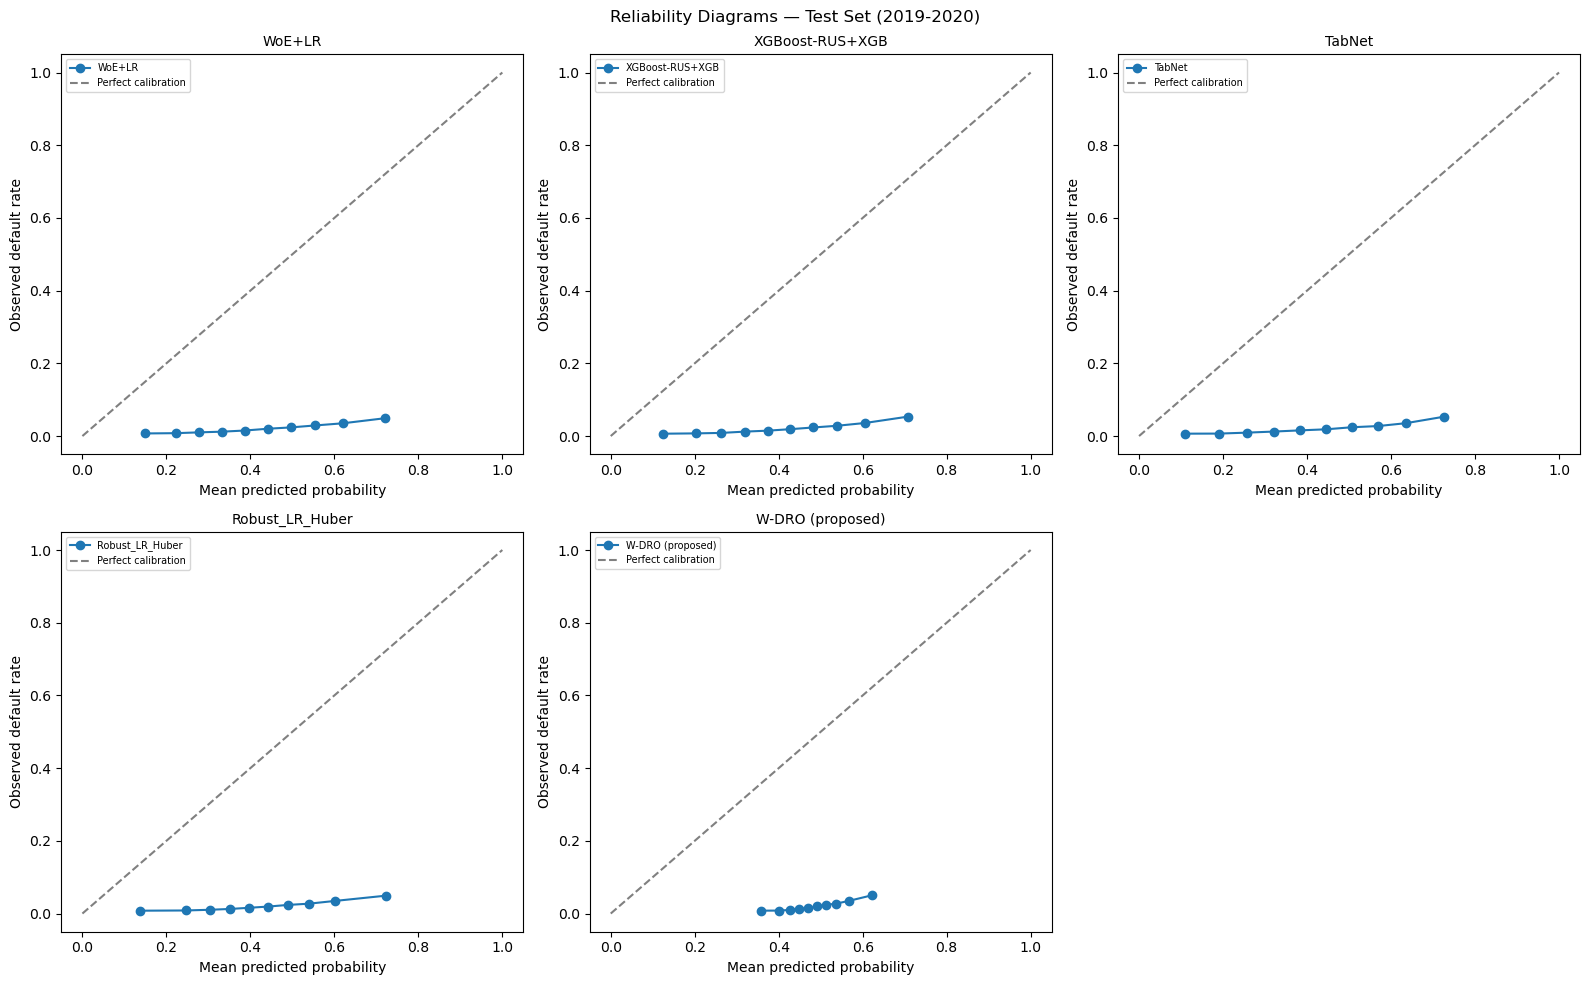

In [64]:
def calibration_slope_intercept(y_true, p_pred, eps=1e-6):
    """Fits y ~ logit(p_pred) via logistic regression. Perfect calibration: slope=1, intercept=0."""
    p_clipped = np.clip(p_pred, eps, 1 - eps)
    logit_p = np.log(p_clipped / (1 - p_clipped)).reshape(-1, 1)
    lr_cal = _LR2(max_iter=1000)
    lr_cal.fit(logit_p, y_true)
    return float(lr_cal.coef_[0][0]), float(lr_cal.intercept_[0])


def expected_calibration_error(y_true, p_pred, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(p_pred, bins[1:-1])
    ece = 0.0
    for b in range(n_bins):
        mask = idx == b
        if mask.sum() == 0:
            continue
        conf = p_pred[mask].mean()
        acc  = y_true[mask].mean()
        ece += (mask.sum() / len(p_pred)) * abs(acc - conf)
    return float(ece)


def brier_decomposition(y_true, p_pred, n_bins=10):
    """Murphy (1973) decomposition: Brier = Reliability - Resolution + Uncertainty."""
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(p_pred, bins[1:-1])
    N = len(y_true)
    ybar = y_true.mean()
    reliability, resolution = 0.0, 0.0
    for b in range(n_bins):
        mask = idx == b
        nk = mask.sum()
        if nk == 0:
            continue
        ok = y_true[mask].mean()
        pk = p_pred[mask].mean()
        reliability += nk * (pk - ok) ** 2
        resolution  += nk * (ok - ybar) ** 2
    reliability /= N
    resolution  /= N
    uncertainty = ybar * (1 - ybar)
    brier = reliability - resolution + uncertainty
    return {"brier": brier, "reliability": reliability,
            "resolution": resolution, "uncertainty": uncertainty}


calibration_summary = []
for name, d in MODELS.items():
    y_arr, p_arr = np.asarray(d["y_test"]).astype(int), np.asarray(d["probs"])
    slope, intercept = calibration_slope_intercept(y_arr, p_arr)
    ece = expected_calibration_error(y_arr, p_arr)
    bd = brier_decomposition(y_arr, p_arr)
    calibration_summary.append({
        "Model": name, "Calibration Slope": slope, "Calibration Intercept": intercept,
        "ECE": ece, "Brier": bd["brier"], "Reliability": bd["reliability"],
        "Resolution": bd["resolution"], "Uncertainty": bd["uncertainty"],
    })
calibration_df = pd.DataFrame(calibration_summary).set_index("Model")
print("Perfect calibration: slope=1.0, intercept=0.0, ECE=0, Reliability=0")
display(calibration_df.round(4))

# Reliability diagrams -- all models
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
for ax, (name, d) in zip(axes, MODELS.items()):
    y_arr, p_arr = np.asarray(d["y_test"]).astype(int), np.asarray(d["probs"])
    frac_pos, mean_pred = calibration_curve(y_arr, p_arr, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
    ax.plot([0, 1], [0, 1], color="gray", ls="--", label="Perfect calibration")
    ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed default rate")
    ax.set_title(name, fontsize=10)
    ax.legend(fontsize=7)
for ax in axes[len(MODELS):]:
    ax.axis("off")
plt.suptitle("Reliability Diagrams — Test Set (2019-2020)")
plt.tight_layout(); plt.show()

## 11.4 Sensitivity Analysis: Isotonic / Platt Recalibration

Recalibration maps are fit on the **validation set only** (2017-2018) and then applied, unseen,
to the test set. Because both Platt scaling and isotonic regression are monotone transforms of the
score, AUC is unchanged (or, for isotonic, changes only through tie handling); the comparison here
is purely about calibration quality, not discrimination.

,AUC,Slope,Intercept,ECE,Brier
Variant,,,,,
W-DRO (raw),0.6702,1.5071,-3.8603,0.4622,0.2377
W-DRO + Platt,0.6702,0.8649,-2.0854,0.0925,0.0316
W-DRO + Isotonic,0.6701,0.8532,-2.1090,0.0928,0.0317


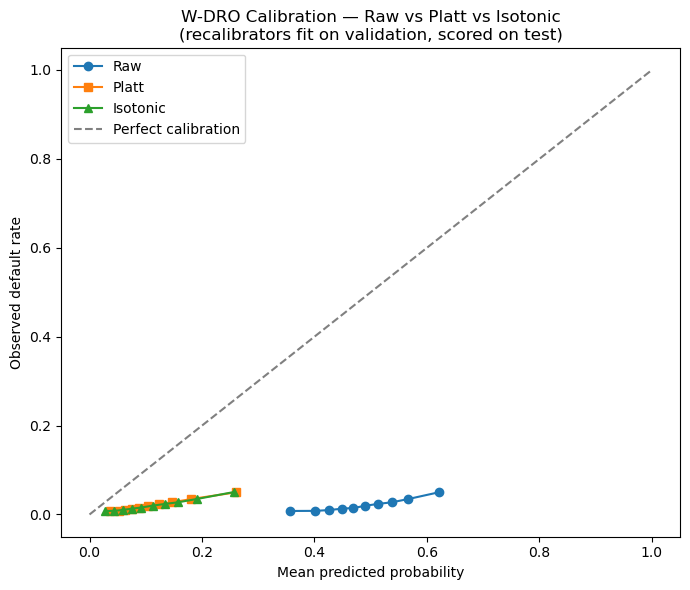

In [65]:
# Recalibration is demonstrated on the primary model (W-DRO); the same recipe
# applies to any model in MODELS by swapping the val/test probability arrays.
val_probs_wdro = np.asarray(MODELS["W-DRO (proposed)"]["y_val"])  # placeholder overwritten below
val_probs_wdro = sigmoid(X_val_wdro @ theta_final)
y_val_sk = (y_val_wdro == 1).astype(int)

platt = _LR2(max_iter=1000)
platt.fit(val_probs_wdro.reshape(-1, 1), y_val_sk)
test_probs_platt = platt.predict_proba(test_probs.reshape(-1, 1))[:, 1]

iso = IsotonicRegression(out_of_bounds="clip")
iso.fit(val_probs_wdro, y_val_sk)
test_probs_iso = iso.predict(test_probs)

recal_rows = []
for label, p_arr in [("W-DRO (raw)", test_probs),
                      ("W-DRO + Platt", test_probs_platt),
                      ("W-DRO + Isotonic", test_probs_iso)]:
    slope, intercept = calibration_slope_intercept(y_test_sk, p_arr)
    ece_r = expected_calibration_error(y_test_sk, p_arr)
    bd_r  = brier_decomposition(y_test_sk, p_arr)
    recal_rows.append({"Variant": label, "AUC": roc_auc_score(y_test_sk, p_arr),
                        "Slope": slope, "Intercept": intercept, "ECE": ece_r, "Brier": bd_r["brier"]})
recal_df = pd.DataFrame(recal_rows).set_index("Variant")
display(recal_df.round(4))

plt.figure(figsize=(7, 6))
for label, p_arr, sty in [("Raw", test_probs, dict(marker="o")),
                            ("Platt", test_probs_platt, dict(marker="s")),
                            ("Isotonic", test_probs_iso, dict(marker="^"))]:
    frac_pos, mean_pred = calibration_curve(y_test_sk, p_arr, n_bins=10, strategy="quantile")
    plt.plot(mean_pred, frac_pos, label=label, **sty)
plt.plot([0, 1], [0, 1], color="gray", ls="--", label="Perfect calibration")
plt.xlabel("Mean predicted probability"); plt.ylabel("Observed default rate")
plt.title("W-DRO Calibration — Raw vs Platt vs Isotonic\n(recalibrators fit on validation, scored on test)")
plt.legend(); plt.tight_layout(); plt.show()

## 11.5 Population Stability Index (PSI) & Covariate Shift

PSI interpretation: <0.10 no shift | 0.10-0.25 moderate shift | >0.25 major shift


,feature,psi
0,open_act_il,1.821889
1,total_bal_il,1.660692
2,max_bal_bc,1.273450
3,all_util,1.201160
4,open_il_24m,1.168396
5,mths_since_rcnt_il,1.156572
6,open_rv_24m,0.923684
7,inq_fi,0.907365
8,inq_last_12m,0.872697
9,open_rv_12m,0.585334


Mean PSI across all features: 0.1893
# features with PSI>0.25 (major shift): 16 / 86


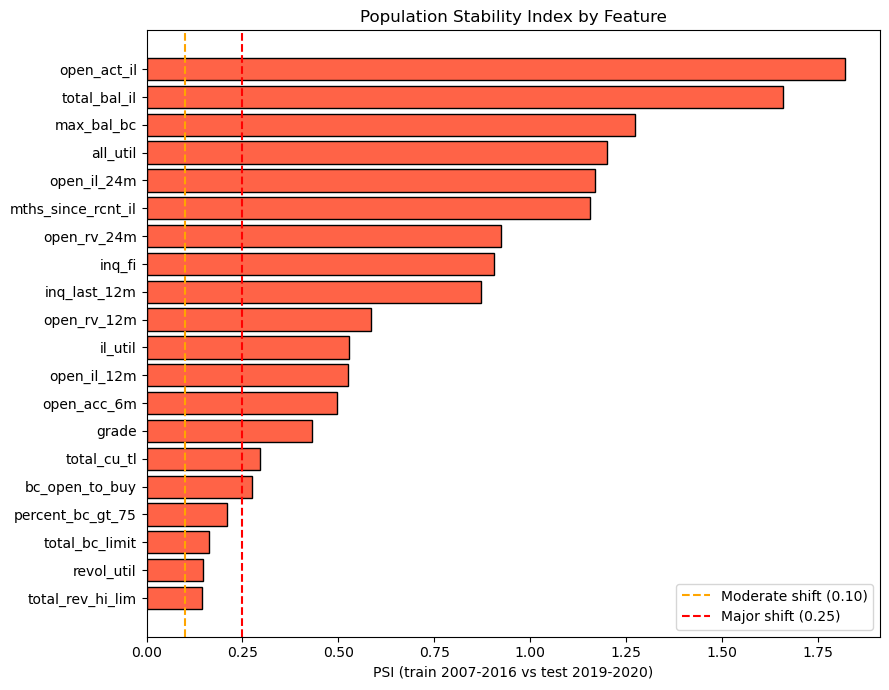


Score-level PSI (W-DRO predicted probability, train vs test): 0.0483


In [66]:
def population_stability_index(expected, actual, buckets=10):
    """Standard PSI on a continuous feature, using expected (train) decile edges."""
    expected = np.asarray(expected, dtype=float)
    actual   = np.asarray(actual, dtype=float)
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, buckets + 1)))
    if len(edges) < 3:
        return 0.0
    e_counts, _ = np.histogram(expected, bins=edges)
    a_counts, _ = np.histogram(actual, bins=edges)
    e_pct = np.clip(e_counts / max(len(expected), 1), 1e-6, None)
    a_pct = np.clip(a_counts / max(len(actual), 1), 1e-6, None)
    return float(np.sum((a_pct - e_pct) * np.log(a_pct / e_pct)))


def psi_report(X_train, X_test, feature_names):
    rows = []
    for j, fname in enumerate(feature_names):
        try:
            psi_val = population_stability_index(X_train[:, j], X_test[:, j])
        except Exception:
            psi_val = np.nan
        rows.append({"feature": fname, "psi": psi_val})
    return pd.DataFrame(rows).sort_values("psi", ascending=False).reset_index(drop=True)


psi_df = psi_report(X_train_wdro, X_test_wdro, feature_names)
print("PSI interpretation: <0.10 no shift | 0.10-0.25 moderate shift | >0.25 major shift")
display(psi_df.head(20))
print(f"Mean PSI across all features: {psi_df['psi'].mean():.4f}")
print(f"# features with PSI>0.25 (major shift): {(psi_df['psi']>0.25).sum()} / {len(psi_df)}")

plt.figure(figsize=(9, 7))
top_psi = psi_df.head(20)
plt.barh(top_psi["feature"][::-1], top_psi["psi"][::-1], color="tomato", edgecolor="k")
plt.axvline(0.10, color="orange", ls="--", label="Moderate shift (0.10)")
plt.axvline(0.25, color="red", ls="--", label="Major shift (0.25)")
plt.xlabel("PSI (train 2007-2016 vs test 2019-2020)")
plt.title("Population Stability Index by Feature")
plt.legend(); plt.tight_layout(); plt.show()

# PSI on the model SCORE distribution itself -- the single most decision-relevant PSI
train_scores_wdro = sigmoid(X_train_wdro @ theta_final)
score_psi = population_stability_index(train_scores_wdro, test_probs)
print(f"\nScore-level PSI (W-DRO predicted probability, train vs test): {score_psi:.4f}")

In [67]:
# ── Covariate shift diagnostics: per-feature KS statistic + adversarial validation ──
def covariate_shift_ks(X_train, X_test, feature_names):
    rows = []
    for j, fname in enumerate(feature_names):
        stat, pval = ks_2samp(X_train[:, j], X_test[:, j])
        rows.append({"feature": fname, "ks_stat": stat, "p_value": pval})
    return pd.DataFrame(rows).sort_values("ks_stat", ascending=False).reset_index(drop=True)

ks_df = covariate_shift_ks(X_train_wdro, X_test_wdro, feature_names)
print("Per-feature KS statistic (train 2007-2016 vs test 2019-2020), top 15:")
display(ks_df.head(15))

# Adversarial validation: can a classifier tell train rows from test rows apart?
# ~0.50 AUC = no detectable shift | ~1.00 AUC = train/test are trivially separable.
X_adv = np.vstack([X_train_wdro, X_test_wdro])
y_adv = np.concatenate([np.zeros(len(X_train_wdro)), np.ones(len(X_test_wdro))])
X_adv_tr, X_adv_te, y_adv_tr, y_adv_te = train_test_split(
    X_adv, y_adv, test_size=0.3, random_state=42, stratify=y_adv
)
adv_clf = _LR2(max_iter=1000, class_weight="balanced").fit(X_adv_tr, y_adv_tr)
adv_auc = roc_auc_score(y_adv_te, adv_clf.predict_proba(X_adv_te)[:, 1])
print(f"\nAdversarial validation AUC (train vs test distinguishability): {adv_auc:.4f}")

Per-feature KS statistic (train 2007-2016 vs test 2019-2020), top 15:


,feature,ks_stat,p_value
0,all_util,0.653631,0.0
1,total_bal_il,0.597068,0.0
2,open_act_il,0.596978,0.0
3,il_util,0.568907,0.0
4,il_util_missing,0.568507,0.0
5,open_il_24m,0.513813,0.0
6,inq_last_12m,0.448554,0.0
7,inq_fi,0.440314,0.0
8,max_bal_bc,0.381161,0.0
9,open_rv_12m,0.365062,0.0



Adversarial validation AUC (train vs test distinguishability): 0.9642


# 12. Ablation Study — Explanation Stability Across Model Components

Reviewer request (fixes the Proposition 2 check): ablate the W-DRO objective one component at a
time, in the order

**LR -> LR+monotonicity -> LR+Ridge -> LR+DRO -> LR+SHAP -> LR+monotonicity+DRO -> Full W-DRO**

and report, at every stage: **total SHAP attribution variance**, **rank correlation** of feature
importances to the full model, **top-K feature consistency**, and **perturbation sensitivity**.
This both (a) isolates which objective term is responsible for explanation stability, and
(b) empirically re-verifies the Proposition 2 identity `sum_j Var(phi_j) = theta^T W theta` at
every stage, directly on held-out test data (Section 8.1 only checked it on synthetic data).

All stages are fit on the **training set** (`X_fit`, `y_fit` -- the same up-to-100k training
subsample used to fit the final W-DRO model in Section 10.5); nothing here is fit on val/test.
Metrics are then computed on the **test set** (`X_test_wdro`), purely for reporting.

In [68]:
def fit_plain_lr(X, y_pm1):
    """Unconstrained, unpenalized logistic regression fit through the SAME
    convex solver used for W-DRO (epsilon=0, lambda=0, no monotonicity) --
    this keeps every ablation stage in the same objective family for a fair,
    apples-to-apples comparison."""
    th, _, _ = solve_wdro(X, y_pm1, epsilon=0.0, lam=0.0, W_mat=W_matrix,
                           pos_indices=[], neg_indices=[])
    return th


def fit_ridge_lr(X, y_pm1, alpha=1.0):
    """Standard SQUARED-L2 (ridge) penalty -- distinct from the W-DRO
    epsilon term, which penalizes the UNSQUARED L2 norm (the Wasserstein-DRO
    dual, Proposition 1), and distinct from the lambda term, which penalizes
    theta^T W theta (the SHAP-stability surrogate, Proposition 2)."""
    y01 = (y_pm1 == 1).astype(int)
    clf = LogisticRegression(penalty="l2", C=1.0 / alpha, solver="lbfgs", max_iter=2000)
    clf.fit(X, y01)
    return clf.coef_.ravel()


ABLATION_STAGES = [
    ("LR",                  dict(epsilon=0.0,      lam=0.0,      mono=False, ridge=False)),
    ("LR+monotonicity",     dict(epsilon=0.0,      lam=0.0,      mono=True,  ridge=False)),
    ("LR+Ridge",            dict(epsilon=0.0,      lam=0.0,      mono=False, ridge=True)),
    ("LR+DRO",              dict(epsilon=BEST_EPS,  lam=0.0,      mono=False, ridge=False)),
    ("LR+SHAP",             dict(epsilon=0.0,       lam=BEST_LAM, mono=False, ridge=False)),
    ("LR+monotonicity+DRO", dict(epsilon=BEST_EPS,  lam=0.0,      mono=True,  ridge=False)),
    ("Full W-DRO",          dict(epsilon=BEST_EPS,  lam=BEST_LAM, mono=True,  ridge=False)),
]

ablation_thetas = {}
print("[ABLATION] Fitting each stage on the training set...")
for stage_name, cfg in ABLATION_STAGES:
    if stage_name == "Full W-DRO":
        ablation_thetas[stage_name] = theta_final  # reuse the already-fit final model
        print(f"  {stage_name:<24} (reusing Section 10.5 final model)")
        continue
    pos_i = pos_idx if cfg["mono"] else []
    neg_i = neg_idx if cfg["mono"] else []
    if cfg["ridge"]:
        th = fit_ridge_lr(X_fit, y_fit, alpha=1.0)
    else:
        th, _, _ = solve_wdro(X_fit, y_fit, epsilon=cfg["epsilon"], lam=cfg["lam"],
                               W_mat=W_fit, pos_indices=pos_i, neg_indices=neg_i)
    ablation_thetas[stage_name] = th
    norm_str = f"{np.linalg.norm(th):.4f}" if th is not None else "SOLVER FAILED"
    print(f"  {stage_name:<24} ||theta||_2 = {norm_str}")

[ABLATION] Fitting each stage on the training set...
  LR                       ||theta||_2 = 35.7677
  LR+monotonicity          ||theta||_2 = 35.7269
  LR+Ridge                 ||theta||_2 = 0.7043
  LR+DRO                   ||theta||_2 = 0.2598
  LR+SHAP                  ||theta||_2 = 0.1926
  LR+monotonicity+DRO      ||theta||_2 = 0.2576
  Full W-DRO               (reusing Section 10.5 final model)


## 12.1 Explanation Stability Metrics per Stage

- **Total attribution variance**: `sum_j Var(phi_j)` on the test set (Proposition 2 quantity).
- **Rank correlation**: Spearman correlation between each stage's |SHAP| feature ranking and the
  full W-DRO model's ranking.
- **Top-K consistency**: overlap fraction of the top-10 most important features vs. the full model.
- **Perturbation sensitivity**: mean L2 change in the SHAP attribution vector under small Gaussian
  input noise (sigma=0.05) -- a direct, model-agnostic robustness probe independent of the training
  objective, used to cross-check the theoretical Proposition 2 claim.

In [69]:
def ablation_metrics(theta, theta_ref, X_test, feature_means, noise_std=0.05, top_k=10):
    N = min(len(X_test), 2000)
    X_s = X_test[:N]
    phi     = compute_shap_linear(theta,     X_s, feature_means)
    phi_ref = compute_shap_linear(theta_ref, X_s, feature_means)

    shap_var  = np.var(phi, axis=0)
    total_var = float(np.sum(shap_var))

    imp     = np.abs(phi).mean(axis=0)
    imp_ref = np.abs(phi_ref).mean(axis=0)
    rank_corr, _ = spearmanr(imp, imp_ref)

    topk     = set(np.argsort(-imp)[:top_k])
    topk_ref = set(np.argsort(-imp_ref)[:top_k])
    topk_consistency = len(topk & topk_ref) / top_k

    np.random.seed(42)
    delta = np.random.normal(0, noise_std, X_s.shape)
    phi_p = compute_shap_linear(theta, X_s + delta, feature_means)
    perturbation_sensitivity = float(np.mean(np.linalg.norm(phi_p - phi, axis=1)))

    return {
        "total_attribution_variance": total_var,
        "rank_correlation_to_full_model": rank_corr,
        f"top{top_k}_consistency_to_full_model": topk_consistency,
        "perturbation_sensitivity": perturbation_sensitivity,
    }


ablation_rows = []
stage_order = []
for stage_name, _ in ABLATION_STAGES:
    th = ablation_thetas.get(stage_name)
    if th is None:
        print(f"  [SKIP] {stage_name}: solver failed to return a solution.")
        continue
    m = ablation_metrics(th, theta_final, X_test_wdro, feature_means)
    m["Stage"] = stage_name
    ablation_rows.append(m)
    stage_order.append(stage_name)

ablation_df = pd.DataFrame(ablation_rows).set_index("Stage").loc[stage_order]
display(ablation_df.round(6))

,total_attribution_variance,rank_correlation_to_full_model,top10_consistency_to_full_model,perturbation_sensitivity
Stage,,,,
LR,2.716814,0.586414,0.6,1.472318
LR+monotonicity,2.641347,0.608887,0.6,1.470546
LR+Ridge,1.022784,0.667060,0.6,0.034418
LR+DRO,0.128779,0.845238,0.9,0.012622
LR+SHAP,0.060834,0.976923,1.0,0.009319
LR+monotonicity+DRO,0.126141,0.862220,0.9,0.012510
Full W-DRO,0.051603,1.000000,1.0,0.008681


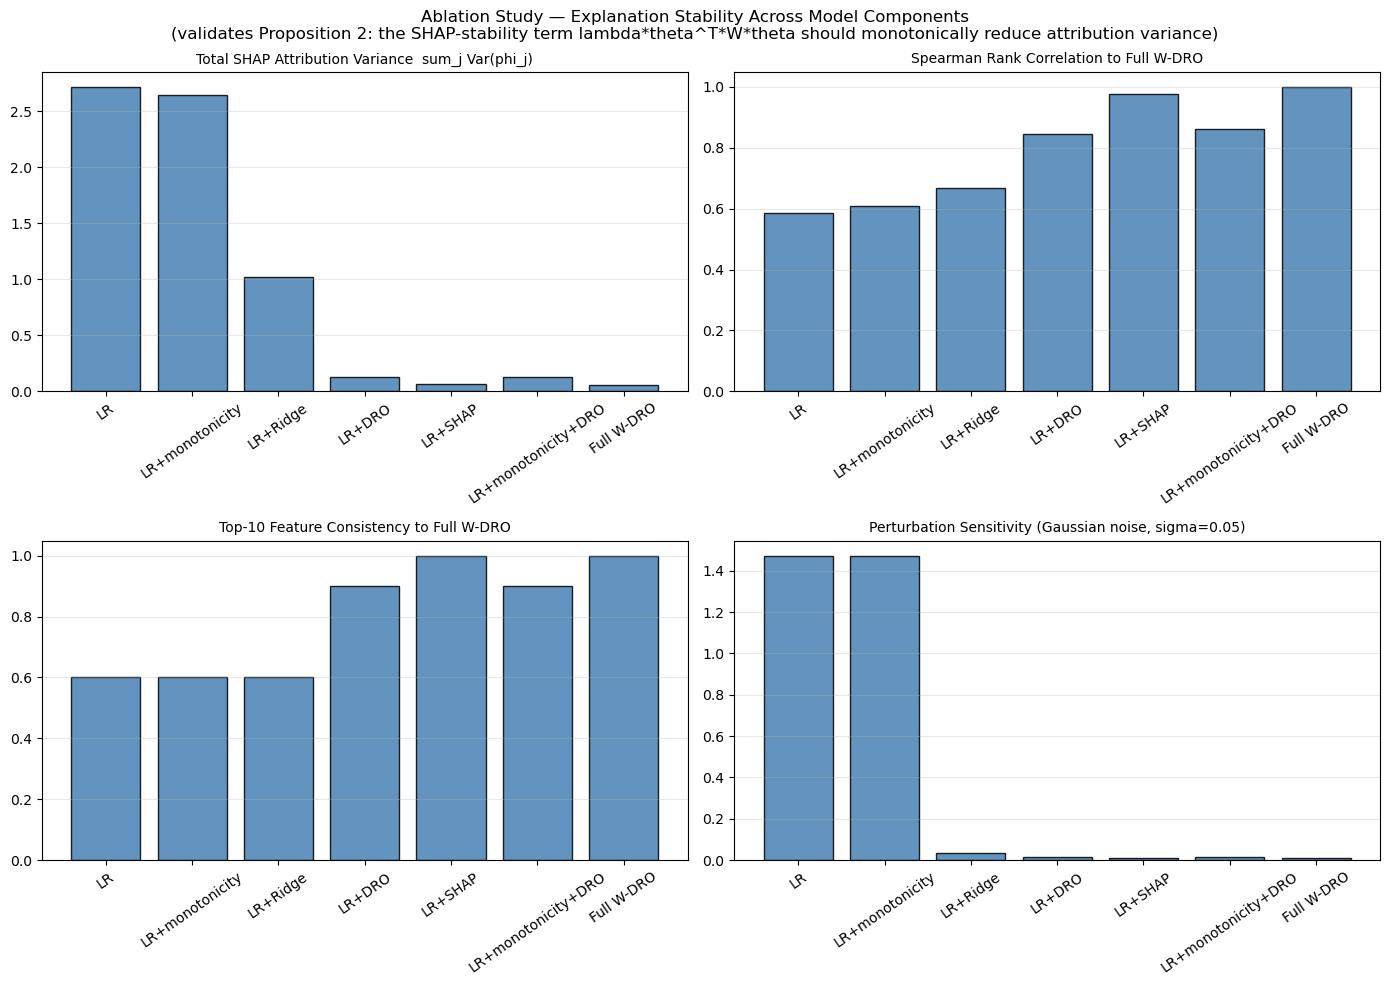

In [70]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics_to_plot = [
    ("total_attribution_variance", "Total SHAP Attribution Variance  sum_j Var(phi_j)"),
    ("rank_correlation_to_full_model", "Spearman Rank Correlation to Full W-DRO"),
    ("top10_consistency_to_full_model", "Top-10 Feature Consistency to Full W-DRO"),
    ("perturbation_sensitivity", "Perturbation Sensitivity (Gaussian noise, sigma=0.05)"),
]
for ax, (col, title) in zip(axes.flatten(), metrics_to_plot):
    ax.bar(ablation_df.index, ablation_df[col], color="steelblue", edgecolor="k", alpha=0.85)
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", rotation=35)
    ax.grid(alpha=0.3, axis="y")
plt.suptitle("Ablation Study — Explanation Stability Across Model Components\n"
             "(validates Proposition 2: the SHAP-stability term lambda*theta^T*W*theta "
             "should monotonically reduce attribution variance)")
plt.tight_layout(); plt.show()

## 12.2 Proposition 2 Identity Check — Every Ablation Stage, Real Test Data

Section 8.1 verified `sum_j Var(phi_j) == theta^T W theta` exactly, but only on synthetic Gaussian
data. Here the identity is re-checked on the actual held-out test set, at every ablation stage,
using the *test-set* empirical feature covariance (the relevant quantity for a held-out validity
claim, as opposed to the diagonal `W` estimated from the training set).

In [71]:
print("=== Proposition 2 identity check per ablation stage (real test data) ===")
print(f"{'Stage':<24} {'sum_j Var(phi_j)':>18} {'theta^T W_test theta':>22} {'abs gap':>12}")
prop2_rows = []
for stage_name, _ in ABLATION_STAGES:
    th = ablation_thetas.get(stage_name)
    if th is None:
        continue
    N = min(len(X_test_wdro), 2000)
    X_s = X_test_wdro[:N]
    phi = compute_shap_linear(th, X_s, feature_means)
    lhs = float(np.sum(np.var(phi, axis=0)))
    W_s = np.diag(np.var(X_s, axis=0))
    rhs = float(th @ W_s @ th)
    print(f"{stage_name:<24} {lhs:>18.6f} {rhs:>22.6f} {abs(lhs-rhs):>12.2e}")
    prop2_rows.append({"Stage": stage_name, "sum_Var_phi": lhs, "theta_T_W_theta": rhs,
                        "abs_gap": abs(lhs - rhs)})
prop2_df = pd.DataFrame(prop2_rows).set_index("Stage")
display(prop2_df.round(6))

=== Proposition 2 identity check per ablation stage (real test data) ===
Stage                      sum_j Var(phi_j)   theta^T W_test theta      abs gap
LR                                 2.716814               2.716814     4.44e-16
LR+monotonicity                    2.641347               2.641347     0.00e+00
LR+Ridge                           1.022784               1.022784     2.22e-16
LR+DRO                             0.128779               0.128779     2.78e-17
LR+SHAP                            0.060834               0.060834     1.39e-17
LR+monotonicity+DRO                0.126141               0.126141     2.78e-17
Full W-DRO                         0.051603               0.051603     2.08e-17


,sum_Var_phi,theta_T_W_theta,abs_gap
Stage,,,
LR,2.716814,2.716814,0.0
LR+monotonicity,2.641347,2.641347,0.0
LR+Ridge,1.022784,1.022784,0.0
LR+DRO,0.128779,0.128779,0.0
LR+SHAP,0.060834,0.060834,0.0
LR+monotonicity+DRO,0.126141,0.126141,0.0
Full W-DRO,0.051603,0.051603,0.0


## 12.3 Pairwise Feature-Importance Rank Correlation Across All Stages

Beyond the "vs. full model" comparison above, this heatmap gives the full pairwise picture of how
consistently each stage ranks feature importance relative to every other stage.

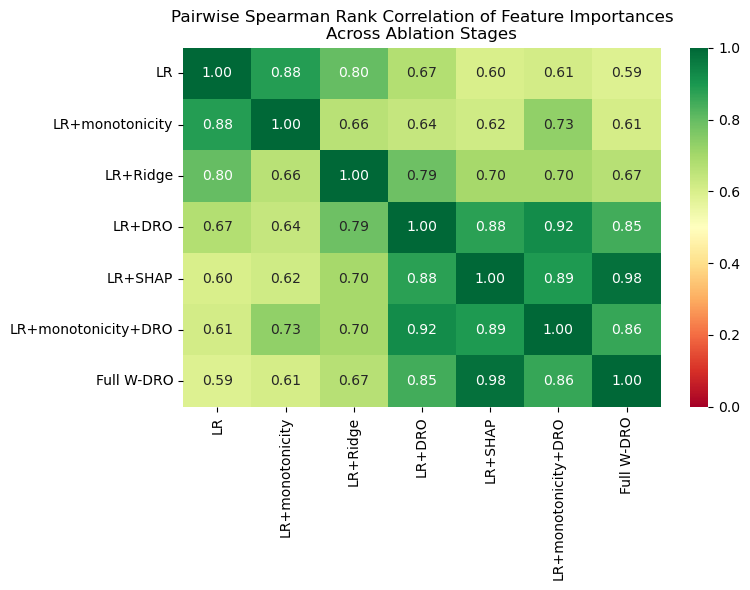

,LR,LR+monotonicity,LR+Ridge,LR+DRO,LR+SHAP,LR+monotonicity+DRO,Full W-DRO
LR,1.000,0.884,0.800,0.673,0.598,0.613,0.586
LR+monotonicity,0.884,1.000,0.663,0.637,0.621,0.733,0.609
LR+Ridge,0.800,0.663,1.000,0.787,0.698,0.696,0.667
LR+DRO,0.673,0.637,0.787,1.000,0.877,0.923,0.845
LR+SHAP,0.598,0.621,0.698,0.877,1.000,0.891,0.977
LR+monotonicity+DRO,0.613,0.733,0.696,0.923,0.891,1.000,0.862
Full W-DRO,0.586,0.609,0.667,0.845,0.977,0.862,1.000


In [72]:
importance_matrix = pd.DataFrame(
    {stage_name: np.abs(compute_shap_linear(ablation_thetas[stage_name],
                                              X_test_wdro[:2000], feature_means)).mean(axis=0)
     for stage_name in stage_order},
    index=feature_names,
)
rank_corr_matrix = importance_matrix.corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(rank_corr_matrix, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1)
plt.title("Pairwise Spearman Rank Correlation of Feature Importances\nAcross Ablation Stages")
plt.tight_layout(); plt.show()

display(rank_corr_matrix.round(3))